# Initial Setup

Import packages


1.   pandas : dataset manipulation & descriptive analysis
2.   numpy : handling arrays operations
3.   matplotlib & seaborn : data visualization
4.   scipy & statsmodels : statistical analysis
5.   sklearn : machine learning



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from scipy.stats import chi2, kruskal
from scipy.stats import chi2_contingency
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import poisson
from scipy import stats

import statsmodels.api as sm
from patsy import dmatrices, build_design_matrices
from scipy.stats import nbinom
from sklearn.metrics import mean_poisson_deviance

import gc
import re
from sklearn.metrics import mean_poisson_deviance


Settings to show all rows & columns permanently for the rest of this notebook

In [ ]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
SEED = 42
MAIN_COLOR = "#2a6fdb"   # single-series charts use one neutral accent

OUTPUT_DIR = Path("outputs")          # in Colab you can point this to Drive instead, e.g.
OUTPUT_DIR.mkdir(exist_ok=True)       # Path("/content/drive/MyDrive/analytics-portfolio/insurance/outputs")

# Upload Data

Connecting to OpenML

In [ ]:
# Load both tables straight from OpenML (first run downloads ~ 20 MB and caches it)
freq_raw = fetch_openml(data_id=41214, as_frame=True, parser="auto").frame   # policies + claim counts
sev_raw  = fetch_openml(data_id=41215, as_frame=True, parser="auto").frame   # one row per claim

Reading the datasets

In [ ]:
print(f"freMTPL2freq (policies): {freq_raw.shape[0]:,} rows x {freq_raw.shape[1]} columns")
print(f"freMTPL2sev  (claims)  : {sev_raw.shape[0]:,} rows x {sev_raw.shape[1]} columns")
display(freq_raw.head())
display(sev_raw.head())

freMTPL2freq (policies): 678,013 rows x 12 columns
freMTPL2sev  (claims)  : 26,639 rows x 2 columns


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.00,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.00,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.00,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.00,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.00,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,"1,128.12"
2,4024277,"1,851.11"
3,4007252,"1,204.00"
4,4046424,"1,204.00"


**Data Dictionary**

In [ ]:
data_dictionary = pd.DataFrame([
    ("IDpol",       "both",   "Policy ID - links the two tables"),
    ("ClaimNb",     "policy", "Number of claims during the exposure period"),
    ("Exposure",    "policy", "Time insured during the observation year, in years (1.0 = full year)"),
    ("Area",        "policy", "Density class of the driver's town, from A (rural) to F (urban centre)"),
    ("VehPower",    "policy", "Vehicle power (ordered categories)"),
    ("VehAge",      "policy", "Vehicle age in years"),
    ("DrivAge",     "policy", "Driver age in years (minimum driving age in France is 18)"),
    ("BonusMalus",  "policy", "Bonus-malus coefficient x100: 100 = base premium (new driver), 50 = maximum 50% discount, above 100 = surcharge (max 350)"),    ("VehBrand",    "policy", "Vehicle brand (anonymised codes B1-B14)"),
    ("VehGas",      "policy", "Fuel type: Diesel or Regular"),
    ("Density",     "policy", "Population density (inhabitants per km2) of the driver's town"),
    ("Region",      "policy", "Region of France (pre-2016 INSEE region codes)"),
    ("ClaimAmount", "claim",  "Cost of an individual claim (EUR)"),
], columns=["column", "table", "description"])
display(data_dictionary)

,column,table,description
0,IDpol,both,Policy ID - links the two tables
1,ClaimNb,policy,Number of claims during the exposure period
2,Exposure,policy,"Time insured during the observation year, in y..."
3,Area,policy,"Density class of the driver's town, from A (ru..."
4,VehPower,policy,Vehicle power (ordered categories)
5,VehAge,policy,Vehicle age in years
6,DrivAge,policy,Driver age in years (minimum driving age in Fr...
7,BonusMalus,policy,Bonus-malus coefficient x100: 100 = base premi...
8,VehBrand,policy,Vehicle brand (anonymised codes B1-B14)
9,VehGas,policy,Fuel type: Diesel or Regular


# Data Cleaning

## 1.1 Missing values and duplicates

In [ ]:
dq_log = []
def log(check, table, n, action):
    # re-running a cell replaces its earlier entry instead of adding a duplicate
    dq_log[:] = [r for r in dq_log if r["check"] != ( check)]
    dq_log.append({ "check": check, "table": table,
                   "rows_affected": int(n), "action": action})

In [ ]:
miss_freq = freq_raw.isna().any(axis=1).sum()
miss_sev  = sev_raw.isna().any(axis=1).sum()
dup_row_freq = freq_raw.duplicated().sum()
dup_id_freq  = freq_raw["IDpol"].duplicated().sum()
dup_row_sev  = sev_raw.duplicated().sum()     # same policy + same amount: can be genuine, only reported

log( "Rows with any missing value",        "policy", miss_freq,    "Investigate")
log( "Rows with any missing value",        "claim",  miss_sev,     "Investigate")
log( "Fully duplicated rows",              "policy", dup_row_freq, "Drop")
log("Duplicated policy IDs",              "policy", dup_id_freq,  "Drop(IDpol must be unique)")
log( "Identical claim rows (same ID & amount)", "claim", dup_row_sev, "Kept: two claims can have the same cost")

display(pd.DataFrame(dq_log))

,check,table,rows_affected,action
0,Rows with any missing value,claim,0,Investigate
1,Fully duplicated rows,policy,0,Drop
2,Duplicated policy IDs,policy,0,Drop(IDpol must be unique)
3,Identical claim rows (same ID & amount),claim,255,Kept: two claims can have the same cost


## 1.2 Standardise data types


*OpenML stores some text values wrapped in quotes (for example `'Regular'`), so these are stripped before the columns are converted to categories.*

In [ ]:
freq = freq_raw.drop_duplicates().drop_duplicates(subset="IDpol").copy()
sev  = sev_raw.copy()

for df in (freq, sev):
    for col in df.columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].astype(str).str.strip().str.strip("'")

int_cols = ["IDpol", "ClaimNb", "VehPower", "VehAge", "DrivAge", "BonusMalus", "Density"]
freq[int_cols] = freq[int_cols].astype("int64")
freq["Exposure"] = freq["Exposure"].astype("float64")
sev["IDpol"] = sev["IDpol"].astype("int64")
sev["ClaimAmount"] = sev["ClaimAmount"].astype("float64")

cat_cols = ["Area", "VehBrand", "VehGas", "Region"]
for col in cat_cols:
    freq[col] = pd.Categorical(freq[col], categories=sorted(freq[col].unique()))

display(freq.dtypes.to_frame("dtype").T)
display(pd.DataFrame({c: [", ".join(map(str, freq[c].cat.categories))] for c in cat_cols},
                     index=["levels"]).T)

,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
dtype,int64,int64,float64,category,int64,int64,int64,int64,category,category,int64,category


,levels
Area,"A, B, C, D, E, F"
VehBrand,"B1, B10, B11, B12, B13, B14, B2, B3, B4, B5, B6"
VehGas,"Diesel, Regular"
Region,"R11, R21, R22, R23, R24, R25, R26, R31, R41, R..."


## 1.3 Policy–claim join checks


*The two tables must agree: every claim should belong to a policy, and a policy's `ClaimNb` should match its number of claim records.*

In [ ]:
n_records = sev.groupby("IDpol").size()
freq["n_claim_records"] = freq["IDpol"].map(n_records).fillna(0).astype("int64")

orphan_claims      = ~sev["IDpol"].isin(freq["IDpol"])
claims_no_amount   = (freq["ClaimNb"] > 0) & (freq["n_claim_records"] == 0)
records_no_claimnb = (freq["ClaimNb"] == 0) & (freq["n_claim_records"] > 0)
count_mismatch     = (freq["ClaimNb"] != freq["n_claim_records"]) & (freq["n_claim_records"] > 0)
nonpositive_amount = sev["ClaimAmount"] <= 0

log( "Claims with no matching policy (orphans)",          "claim",  orphan_claims.sum(),      "Drop (cannot be linked to risk factors)")
log( "Policies with ClaimNb > 0 but no claim record",     "policy", claims_no_amount.sum(),   "See decision D3")
log( "Policies with ClaimNb = 0 but claim records",       "policy", records_no_claimnb.sum(), "See decision D3")
log( "Policies whose ClaimNb differs from no. of records", "policy", count_mismatch.sum(),     "See decision D3")
log( "Claims with amount <= 0",                           "claim",  nonpositive_amount.sum(), "Drop (a claim cost must be positive)")

join_summary = pd.DataFrame({
    "measure": ["Claims reported in policy table (sum of ClaimNb)",
                "Claim records with an amount (claim table)",
                "Claim records linked to a policy",
                "Share of reported claims that have an amount"],
    "value": [freq["ClaimNb"].sum(), len(sev), (~orphan_claims).sum(),
              f"{(~orphan_claims).sum() / freq['ClaimNb'].sum():.1%}"],
})
display(join_summary)
display(pd.DataFrame(dq_log[-5:]))

,measure,value
0,Claims reported in policy table (sum of ClaimNb),36102
1,Claim records with an amount (claim table),26639
2,Claim records linked to a policy,26444
3,Share of reported claims that have an amount,73.2%


,check,table,rows_affected,action
0,Claims with no matching policy (orphans),claim,195,Drop (cannot be linked to risk factors)
1,Policies with ClaimNb > 0 but no claim record,policy,9116,See decision D3
2,Policies with ClaimNb = 0 but claim records,policy,0,See decision D3
3,Policies whose ClaimNb differs from no. of rec...,policy,1,See decision D3
4,Claims with amount <= 0,claim,0,Drop (a claim cost must be positive)


**Is the missing claim cost random?**

Some reported claims have no cost recorded. If that happens at the same rate in every segment, dropping those claims makes every segment look equally safer, so comparisons between segments still hold. If it happens more in some segments than others, those segments would look artificially safe, which would bias the pricing. The tables below show the share of claiming policies with no cost by segment, and the chi-square test checks whether the differences are real. Because the sample is large, even small differences are significant, so Cramér's V (0 = no association, above about 0.1 = a meaningful one) shows how big the difference is.

In [ ]:
claimants = freq[freq["ClaimNb"] > 0].copy()
claimants["has_no_amount"] = claimants["n_claim_records"] == 0

def missing_rate_by(col):
    t = (claimants.groupby(col, observed=True)
                  .agg(policies_with_claims=("has_no_amount", "size"),
                       pct_without_amount=("has_no_amount", "mean")))
    t["pct_without_amount"] = (t["pct_without_amount"] * 100).round(1)
    return t

for col in ["Area", "VehGas", "Region"]:
    print(f"Share of claiming policies with no claim amount, by {col}")
    display(missing_rate_by(col).T if col != "Region" else missing_rate_by(col).sort_values("pct_without_amount"))

Share of claiming policies with no claim amount, by Area


Area,A,B,C,D,E,F
policies_with_claims,"4,831.00","3,630.00","9,356.00","7,892.00","7,296.00","1,055.00"
pct_without_amount,33.00,30.50,28.10,23.40,21.90,32.40


Share of claiming policies with no claim amount, by VehGas


VehGas,Diesel,Regular
policies_with_claims,"15,709.00","18,351.00"
pct_without_amount,19.20,33.30


Share of claiming policies with no claim amount, by Region


,policies_with_claims,pct_without_amount
Region,,
R82,4760,15.90
R54,920,16.80
R31,1092,20.10
R52,1909,21.50
R72,1264,22.10
R41,589,23.30
R74,242,24.00
R93,3625,24.10
R83,181,25.40


In [ ]:
from scipy.stats import chi2_contingency

tests = []
for col in ["Area", "VehGas", "Region"]:
    ct = pd.crosstab(claimants[col], claimants["has_no_amount"])
    chi2_stat, p, dof, _ = chi2_contingency(ct)
    rates = missing_rate_by(col)["pct_without_amount"]
    tests.append({"factor": col, "chi2": round(chi2_stat, 1), "dof": dof, "p_value": f"{p:.1e}",
                  "cramers_v": round(np.sqrt(chi2_stat / ct.values.sum()), 3),
                  "lowest_pct": rates.min(), "highest_pct": rates.max()})
display(pd.DataFrame(tests))

,factor,chi2,dof,p_value,cramers_v,lowest_pct,highest_pct
0,Area,278.70,5,3.8e-58,0.09,21.90,33.00
1,VehGas,860.70,1,3.4e-189,0.16,19.20,33.30
2,Region,877.00,21,4.1e-172,0.16,15.90,53.00


**Finding:**

**Missing claim costs are not spread evenly across segments**
- The share of claiming policies with no recorded cost ranges from 22% to 33% by area, 19.2% vs 33.3% by fuel type (Regular highest), and ~16% to 53% by region.
- The chi-square test is significant for all factors (p < 0.01), with Cramér's V of 0.09 for area, and 0.16 for fuel type and region.
- The differences in missing-cost rates are large enough to matter for pricing: dropping uncosted claims would understate the claim frequency of the high-missing fuel group by about 17% relative to the other, so every reported claim is kept for frequency modelling (decision D3).

## 1.4 Validity and range checks

In [ ]:
rules = {
    "Exposure <= 0":                 freq["Exposure"] <= 0,
    "Exposure > 1 year":             freq["Exposure"] > 1,
    "ClaimNb > 4":                   freq["ClaimNb"] > 4,
    "DrivAge < 18":                  freq["DrivAge"] < 18,
    "DrivAge > 90":                  freq["DrivAge"] > 90,
    "VehAge > 30":                   freq["VehAge"] > 30,
    "BonusMalus outside 50-350":     ~freq["BonusMalus"].between(50, 350),
    "Density <= 0":                  freq["Density"] <= 0,
}
validity = pd.DataFrame({"rule": list(rules), "rows": [int(m.sum()) for m in rules.values()]})
validity["pct_of_policies"] = (validity["rows"] / len(freq) * 100).round(3)
display(validity)

print("ClaimNb distribution (policy table):")
display(freq["ClaimNb"].value_counts().sort_index().to_frame("policies").T)

facts = pd.DataFrame({"fact": [
        "Policies with at least one claim",
        "Policies with Exposure exactly 1.0 (full year)",
        "Policies at maximum bonus (BonusMalus = 50)",
        "Policies with VehAge exactly 100",
    ], "policies": [
        (freq["ClaimNb"] > 0).sum(), (freq["Exposure"] == 1).sum(),
        (freq["BonusMalus"] == 50).sum(), (freq["VehAge"] == 100).sum(),
    ]})
facts["pct_of_policies"] = (facts["policies"] / len(freq) * 100).round(2)
display(facts)

print("Most frequent claim amounts:")
display(sev["ClaimAmount"].value_counts().head(5).to_frame("claims")
           .assign(pct_of_claims=lambda d: (d["claims"] / len(sev) * 100).round(1)))

,rule,rows,pct_of_policies
0,Exposure <= 0,0,0.00
1,Exposure > 1 year,1224,0.18
2,ClaimNb > 4,9,0.00
3,DrivAge < 18,0,0.00
4,DrivAge > 90,401,0.06
5,VehAge > 30,1116,0.17
6,BonusMalus outside 50-350,0,0.00
7,Density <= 0,0,0.00


ClaimNb distribution (policy table):


ClaimNb,0,1,2,3,4,5,6,8,9,11,16
policies,643953,32178,1784,82,7,2,1,1,1,3,1


,fact,policies,pct_of_policies
0,Policies with at least one claim,34060,5.02
1,Policies with Exposure exactly 1.0 (full year),168125,24.80
2,Policies at maximum bonus (BonusMalus = 50),384156,56.66
3,Policies with VehAge exactly 100,25,0.00


Most frequent claim amounts:


,claims,pct_of_claims
ClaimAmount,,
"1,204.00",4792,18.00
"1,128.12",3056,11.50
"1,172.00",2072,7.80
"1,128.00",831,3.10
602.00,433,1.60


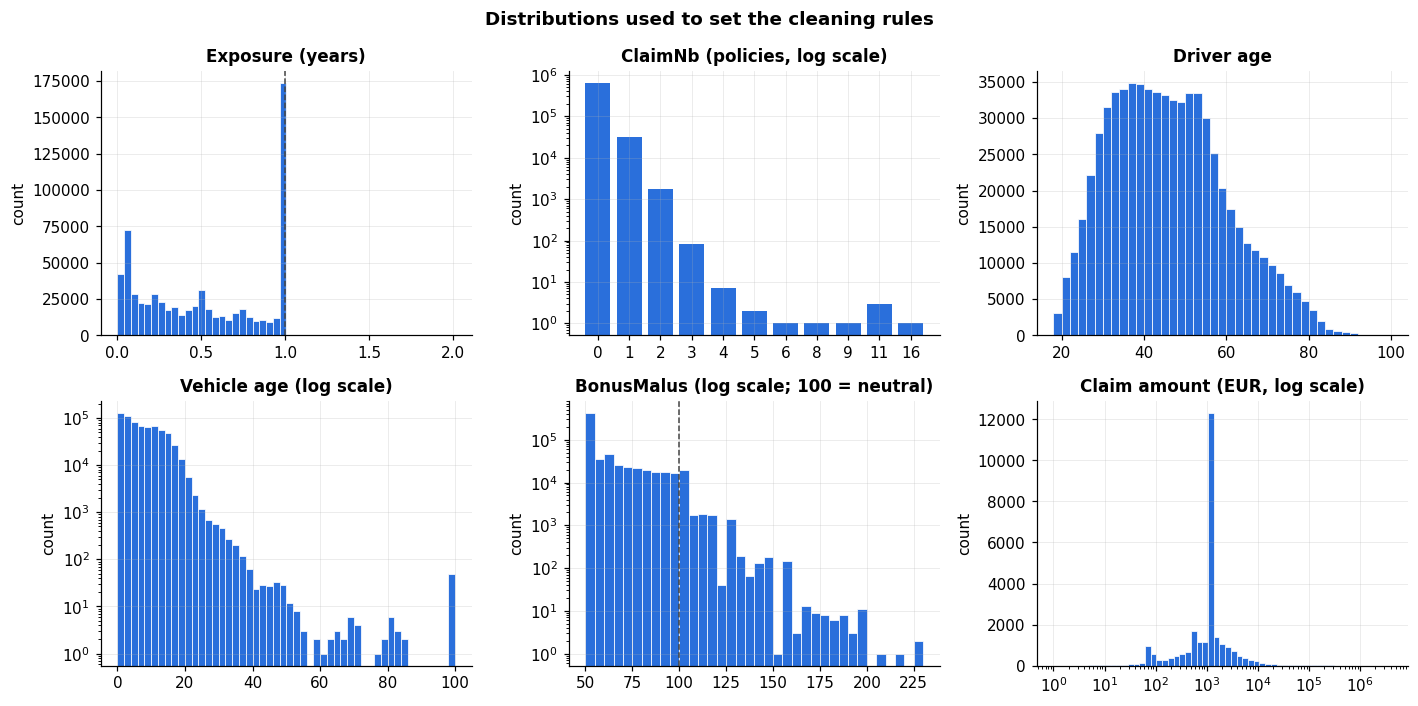

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))

axes[0, 0].hist(freq["Exposure"], bins=50, color=MAIN_COLOR, edgecolor="white", linewidth=0.5)
axes[0, 0].axvline(1, color="#444", ls="--", lw=1); axes[0, 0].set_title("Exposure (years)")

cn = freq["ClaimNb"].value_counts().sort_index()
axes[0, 1].bar(cn.index.astype(str), cn.values, color=MAIN_COLOR)
axes[0, 1].set_yscale("log"); axes[0, 1].set_title("ClaimNb (policies, log scale)")

axes[0, 2].hist(freq["DrivAge"], bins=range(18, 102, 2), color=MAIN_COLOR, edgecolor="white", linewidth=0.5)
axes[0, 2].set_title("Driver age")

axes[1, 0].hist(freq["VehAge"], bins=range(0, 101, 2), color=MAIN_COLOR, edgecolor="white", linewidth=0.5)
axes[1, 0].set_yscale("log"); axes[1, 0].set_title("Vehicle age (log scale)")

axes[1, 1].hist(freq["BonusMalus"], bins=range(50, 232, 5), color=MAIN_COLOR, edgecolor="white", linewidth=0.5)
axes[1, 1].set_yscale("log"); axes[1, 1].axvline(100, color="#444", ls="--", lw=1)
axes[1, 1].set_title("BonusMalus (log scale; 100 = neutral)")

pos = sev.loc[sev["ClaimAmount"] > 0, "ClaimAmount"]
axes[1, 2].hist(pos, bins=np.logspace(np.log10(pos.min()), np.log10(pos.max()), 60),
                color=MAIN_COLOR, edgecolor="white", linewidth=0.5)
axes[1, 2].set_xscale("log"); axes[1, 2].set_title("Claim amount (EUR, log scale)")

for ax in axes.flat:
    ax.set_ylabel("count")
fig.suptitle("Distributions used to set the cleaning rules", fontweight="bold")
fig.tight_layout(); plt.show()

**Finding:**

**Data validity: the data is clean, with a few small, explainable issues**
- Only four rules flag any rows, each under 0.2% of policies: 1,224 policies (0.18%) have Exposure above 1 year, 1,116 (0.17%) have a vehicle older than 30 years, 401 (0.06%) have a driver older than 90, and 9 have more than 4 claims. No policy has zero or negative exposure, a driver under 18, a BonusMalus outside 50–350, or zero density.
- Claims are rare: 643,953 policies have no claim, 32,178 have one, 1,784 have two and 82 have three; 5.02% of policies have at least one claim. The 9 policies with 5 to 16 claims in one year are implausible for a single car and are treated as data errors (D4).
- Exposure: 168,125 policies (24.8%) are insured for the full year (the spike at 1.0); the rest joined or left during the year, which is why claim counts must be measured per year insured. Values above 1 (the tail up to 2 years) are recording errors (D1).
- Most drivers are between about 30 and 55, with few under 20. Most vehicles are under 20 years old, but 25 policies have a vehicle age of exactly 100, which looks like a placeholder value (D6).
- 55.6% of policies sit at the BonusMalus floor of 50 (maximum 50% no-claims discount), and very few are above 125.
- Claim amounts range from ~100 to 10,000+ EUR (claim table profile), with a long right tail. One amount, 1,204 EUR, accounts for 18% of all claims, which points to fixed-rate settlements; this spike needs attention when testing severity distributions in Section 4.
- A single claim amount, EUR 1,204, appears on 4792 claims (18% of all claims), far more than any other value. Such repetition is consistent with fixed-amount settlements, where insurers settle many minor claims at a standard flat rate rather than the exact cost.

## 1.5 Cleaning decisions




| # | Issue | Decision | Reason |
|---|---|---|---|
| D1 | Exposure above 1 year (1,224 policies, 0.18%) | Cap at 1.0 | Exposure is the denominator of every frequency and premium rate and the offset in the Poisson GLM. Claims were recorded over a one-year window, so exposure above 1 is a recording error that would understate these policies' claim frequency. Capping keeps their otherwise valid information. |
| D2 | Claims with no matching policy | Drop | They cannot be linked to any rating factor. |
| D3 | Reported claims without a recorded cost | Keep every reported claim for frequency: `ClaimNb_model` = reported count (raised to the number of costed records where that is higher). Severity is modelled on costed claims only. The cost of uncosted claims is estimated in Section 6 from the severity model. | The missing-cost check shows the gaps are **not** spread evenly across segments, so dropping uncosted claims would make some segments look artificially safe. Assumption: within the same rating segment, an uncosted claim costs on average the same as a costed one. |
| D4 | More than 4 claims in a year | Cap `ClaimNb_model` at 4 for the frequency model | Extremely rare and widely treated as data errors in the literature on this dataset (also done in scikit-learn's freMTPL2 example). Total claim cost is not changed. |
| D5 | Very large claims | Not capped here | The cap is chosen in Section 4 with a mean-excess plot, and the excess is spread back as a loading. |
| D6 | Extreme driver / vehicle ages, including VehAge = 100 | Keep, flagged | VehAge = 100 looks like a placeholder value, but it is a tiny share of policies and falls in the open-ended 16+ band, as do drivers over 90 in the 71+ band, so it has no effect on the banded analysis. |

In [ ]:
assert "ClaimNb" in freq.columns and freq["Exposure"].max() > 1, \
    "freq looks already cleaned - re-run from step 1.2 (or Runtime > Restart session and run all)"

In [ ]:
# D1 - cap exposure
n_exp = (freq["Exposure"] > 1).sum()
freq["Exposure"] = freq["Exposure"].clip(upper=1.0)
log( "D1 Exposure capped at 1 year", "policy", n_exp, "Capped")

# D2 - drop orphan claims and non-positive amounts
n_before = len(sev)
sev = sev[sev["IDpol"].isin(freq["IDpol"]) & (sev["ClaimAmount"] > 0)].copy()
log( "D2 Orphan / non-positive claims removed", "claim", n_before - len(sev), "Dropped")

# D3 - keep every reported claim; never fewer than the claims that have a cost
freq["ClaimNb_reported"] = freq["ClaimNb"]
freq["n_claims_costed"] = freq["IDpol"].map(sev.groupby("IDpol").size()).fillna(0).astype("int64")
freq["ClaimNb_model"] = np.maximum(freq["ClaimNb_reported"], freq["n_claims_costed"])
log( "D3 Claim count raised to number of costed records", "policy",
    (freq["ClaimNb_model"] != freq["ClaimNb_reported"]).sum(), "ClaimNb_model = max(reported, costed)")

# D4 - cap claim count for the frequency model
n_cap = (freq["ClaimNb_model"] > 4).sum()
freq["ClaimNb_model"] = freq["ClaimNb_model"].clip(upper=4)
log( "D4 ClaimNb_model capped at 4", "policy", n_cap, "Capped (claim cost unchanged)")

# claims with no recorded cost - their cost is estimated in Section 6
freq["n_claims_uncosted"] = (freq["ClaimNb_model"] - freq["n_claims_costed"]).clip(lower=0)
log( "D3 Policies with uncosted claims (cost estimated later)", "policy",
    (freq["n_claims_uncosted"] > 0).sum(), "Flagged: n_claims_uncosted")

freq = freq.drop(columns=["ClaimNb", "n_claim_records"])
display(pd.DataFrame(dq_log[-5:]))

,check,table,rows_affected,action
0,D1 Exposure capped at 1 year,policy,1224,Capped
1,D2 Orphan / non-positive claims removed,claim,195,Dropped
2,D3 Claim count raised to number of costed records,policy,0,"ClaimNb_model = max(reported, costed)"
3,D4 ClaimNb_model capped at 4,policy,9,Capped (claim cost unchanged)
4,D3 Policies with uncosted claims (cost estimat...,policy,9117,Flagged: n_claims_uncosted


### Aggregate claims to policy level

*`claims` keeps one row per claim (used for severity modelling in Section 4); `policies` gets one row per policy with its total claim cost.*

In [ ]:
claim_totals = sev.groupby("IDpol", as_index=False)["ClaimAmount"].sum()

policies = freq.merge(claim_totals, on="IDpol", how="left")
policies["ClaimAmount"] = policies["ClaimAmount"].fillna(0.0)   # recorded cost only

# claim-level table with the policy's rating factors attached
rating_cols = ["IDpol", "Exposure", "Area", "VehPower", "VehAge", "DrivAge",
               "BonusMalus", "VehBrand", "VehGas", "Density", "Region"]
claims = sev.merge(freq[rating_cols], on="IDpol", how="left")

# reconciliation: no cost may be lost or double-counted in the merge
recon = pd.DataFrame({
    "check": ["Total claim cost: claim table", "Total claim cost: policy table",
              "Policies (rows)", "Claims (rows)"],
    "value": [sev["ClaimAmount"].sum(), policies["ClaimAmount"].sum(), len(policies), len(claims)],
})
display(recon)
assert np.isclose(sev["ClaimAmount"].sum(), policies["ClaimAmount"].sum()), "claim cost lost in merge"
assert policies["IDpol"].is_unique

,check,value
0,Total claim cost: claim table,"59,909,216.50"
1,Total claim cost: policy table,"59,909,216.50"
2,Policies (rows),"678,013.00"
3,Claims (rows),"26,444.00"


## 1.6 Feature engineering


Numeric rating factors (driver age, vehicle age, vehicle power, bonus-malus, density) are grouped into **bands**, for example driver age 18-20, 21-25 and so on. Bands are used for the one-way analysis (Section 3) and as tariff-style factors in the GLM (Section 5), the same way insurers publish their prices by age group rather than by every single age. The breakpoints follow common motor-pricing practice; the bonus-malus boundary at 100 separates customers with a discount (below 100) from those paying a surcharge (above 100).

**Why we measure in policy-years, not number of policies**

A *policy-year* is one car insured for one full year. Policies in this data are insured for different lengths of time: some for the whole year, others only for a few months because they started or cancelled during the year.

Think of it like comparing two drivers: one was insured for 12 months and had 1 claim, the other was insured for 3 months and also had 1 claim. Counting them as "one policy each" makes them look equally risky, but the second driver had their claim in a quarter of the time, so they are actually four times riskier. Measuring in policy-years fixes this:

| Policy | Insured for | Policy-years |
|---|---|---|
| A | 12 months | 1.00 |
| B | 6 months | 0.50 |
| C | 3 months | 0.25 |
| **Total** | | **1.75** (not 3) |

So claim frequency is always calculated as **claims ÷ policy-years**, the number of claims per year of insured driving.

**Why we check each band's policy-years and claims**

Each band will get its own claim rate and its own price factor, so each band needs enough data to be trusted. A band with plenty of claims gives a stable rate; a band with only a handful of claims can swing a lot just by chance, like judging a basketball player on 5 shots instead of 500. The check below shows, for every band, how much insured time and how many claims it has, plus the margin of error on its claim rate. Actuaries use about **1,082 claims** as the standard for a fully reliable rate (90% confidence that the rate is within 5% of the true value). Bands well below this are candidates to be merged with a neighbouring band.

The check counts the **actual claims in each band** and compares them with the 1,082 standard. The portfolio totals printed at the top of the output (total claims, total policy-years and the average claim rate) give a quick rule of thumb as well: a band needs roughly **1,082 ÷ average claim rate** policy-years to reach the standard. For example, at an average of about 0.1 claims per policy-year, a band needs about 10,800 policy-years.

The 1,082 comes from the Poisson distribution of claim counts: with N claims, the random error in the claim rate is about 1 ÷ √N. For 90% confidence (z = 1.645) that the rate is within 5% of the true value, 1.645 ÷ √N ≤ 0.05, so N ≥ (1.645 ÷ 0.05)² ≈ 1,082 claims.

In [ ]:
band_specs = {
    "DrivAgeBand":    ("DrivAge",    [17, 20, 25, 30, 40, 50, 60, 70, np.inf],
                       ["18-20", "21-25", "26-30", "31-40", "41-50", "51-60", "61-70", "71+"]),
    "VehAgeBand":     ("VehAge",     [-1, 0, 2, 5, 10, 15, np.inf],
                       ["0", "1-2", "3-5", "6-10", "11-15", "16+"]),
    "VehPowerBand":   ("VehPower",   [3, 4, 5, 6, 7, 8, 9, 11, np.inf],
                       ["4", "5", "6", "7", "8", "9", "10-11", "12+"]),
    "BonusMalusBand": ("BonusMalus", [49, 50, 70, 90, 100, 125, np.inf],
                       ["50", "51-70", "71-90", "91-100", "101-125", "126+"]),
    "DensityBand":    ("Density",    [0, 50, 200, 1000, 5000, np.inf],
                       ["<50", "50-199", "200-999", "1,000-4,999", "5,000+"]),
}
for new_col, (src, bins, labels) in band_specs.items():
    policies[new_col] = pd.cut(policies[src], bins=bins, labels=labels, ordered=True)

policies["LogDensity"] = np.log(policies["Density"])

# Region names (pre-2016 INSEE codes) - useful for the Power BI map
region_names = {
    "R11": "Ile-de-France", "R21": "Champagne-Ardenne", "R22": "Picardie", "R23": "Haute-Normandie",
    "R24": "Centre", "R25": "Basse-Normandie", "R26": "Bourgogne", "R31": "Nord-Pas-de-Calais",
    "R41": "Lorraine", "R42": "Alsace", "R43": "Franche-Comte", "R52": "Pays de la Loire",
    "R53": "Bretagne", "R54": "Poitou-Charentes", "R72": "Aquitaine", "R73": "Midi-Pyrenees",
    "R74": "Limousin", "R82": "Rhone-Alpes", "R83": "Auvergne", "R91": "Languedoc-Roussillon",
    "R93": "Provence-Alpes-Cote d'Azur", "R94": "Corse",
}
policies["RegionName"] = policies["Region"].astype(str).map(region_names)
print("Region codes without a name:", sorted(set(policies.loc[policies["RegionName"].isna(), "Region"].astype(str))))

band_cols = list(band_specs)
unbanded = policies[band_cols].isna().sum()
assert unbanded.sum() == 0, f"values fell outside the bands:\n{unbanded}"

# exposure per band - every band should carry enough exposure to be estimated reliably
for col in band_cols:
    t = policies.groupby(col, observed=True)["Exposure"].sum()
    print(f"\n{col}: exposure (policy-years) per band")
    display((t.to_frame("exposure").assign(pct=lambda d: (d["exposure"] / d["exposure"].sum() * 100).round(1))).T)

Region codes without a name: []

DrivAgeBand: exposure (policy-years) per band


DrivAgeBand,18-20,21-25,26-30,31-40,41-50,51-60,61-70,71+
exposure,"2,584.54","13,642.65","29,167.21","83,897.52","88,099.98","75,700.42","38,321.18","26,946.60"
pct,0.70,3.80,8.10,23.40,24.60,21.10,10.70,7.50



VehAgeBand: exposure (policy-years) per band


VehAgeBand,0,1-2,3-5,6-10,11-15,16+
exposure,"16,696.33","62,441.62","72,021.11","98,974.30","77,955.00","30,271.75"
pct,4.70,17.40,20.10,27.60,21.80,8.40



VehPowerBand: exposure (policy-years) per band


VehPowerBand,4,5,6,7,8,9,10-11,12+
exposure,"60,055.33","68,148.13","82,497.59","77,919.75","22,673.97","15,338.64","23,858.40","7,868.30"
pct,16.80,19.00,23.00,21.70,6.30,4.30,6.70,2.20



BonusMalusBand: exposure (policy-years) per band


BonusMalusBand,50,51-70,71-90,91-100,101-125,126+
exposure,"225,152.65","74,442.55","41,799.13","13,395.04","3,197.68",373.05
pct,62.80,20.80,11.70,3.70,0.90,0.10



DensityBand: exposure (policy-years) per band


DensityBand,<50,50-199,200-999,"1,000-4,999","5,000+"
exposure,"63,571.59","85,996.49","96,619.05","89,914.95","22,258.02"
pct,17.70,24.00,27.00,25.10,6.20


## 1.7 Train / test split



*An 80/20 split made **before** any modelling, stratified on whether the policy has a claim so both sets have the same claim rate. The same split is used by every model in Sections 4-5.*

In [ ]:
has_claim = (policies["ClaimNb_model"] > 0).astype(int)
train_idx, test_idx = train_test_split(policies.index, test_size=0.20, random_state=SEED, stratify=has_claim)
policies["split"] = "train"
policies.loc[test_idx, "split"] = "test"
claims = claims.merge(policies[["IDpol", "split"]], on="IDpol", how="left")

split_check = (policies.groupby("split")
                       .agg(policies=("IDpol", "size"),
                            exposure=("Exposure", "sum"),
                            claims=("ClaimNb_model", "sum"),
                            costed_claims=("n_claims_costed", "sum"),
                            recorded_cost=("ClaimAmount", "sum")))
split_check["frequency"] = split_check["claims"] / split_check["exposure"]
split_check["avg_severity"] = split_check["recorded_cost"] / split_check["costed_claims"]
display(split_check)

,policies,exposure,claims,costed_claims,recorded_cost,frequency,avg_severity
split,,,,,,,
test,135603,"71,583.60",7225,5312,"11,055,690.67",0.10,"2,081.27"
train,542410,"286,776.50",28831,21132,"48,853,525.83",0.10,"2,311.83"


## 1.8 Data-quality log and save

In [ ]:
dq_table = pd.DataFrame(dq_log)
display(dq_table)

final_shape = pd.DataFrame({
    "table": ["policies", "claims"],
    "rows": [len(policies), len(claims)],
    "columns": [policies.shape[1], claims.shape[1]],
})
display(final_shape)

policies.to_pickle(OUTPUT_DIR / "policies_clean.pkl")   # pickle keeps the category types for the next sections
claims.to_pickle(OUTPUT_DIR / "claims_clean.pkl")
dq_table.to_csv(OUTPUT_DIR / "data_quality_log.csv", index=False)
print("Saved:", *sorted(p.name for p in OUTPUT_DIR.iterdir()), sep="\n  ")

,check,table,rows_affected,action
0,Rows with any missing value,claim,0,Investigate
1,Fully duplicated rows,policy,0,Drop
2,Duplicated policy IDs,policy,0,Drop(IDpol must be unique)
3,Identical claim rows (same ID & amount),claim,255,Kept: two claims can have the same cost
4,Claims with no matching policy (orphans),claim,195,Drop (cannot be linked to risk factors)
5,Policies with ClaimNb > 0 but no claim record,policy,9116,See decision D3
6,Policies with ClaimNb = 0 but claim records,policy,0,See decision D3
7,Policies whose ClaimNb differs from no. of rec...,policy,1,See decision D3
8,Claims with amount <= 0,claim,0,Drop (a claim cost must be positive)
9,D1 Exposure capped at 1 year,policy,1224,Capped


,table,rows,columns
0,policies,678013,24
1,claims,26444,13


Saved:
  claims_clean.pkl
  data_quality_log.csv
  policies_clean.pkl


**Finding:**

**Data quality and cleaning summary**
- 195 orphan claims were removed, 1,224 policies had exposure capped at 1 year and 9 policies had their claim count capped at 4.
- 9,116 policies have at least one claim without a recorded cost. These claims stay in the frequency model and their cost is estimated in Section 6, because missing costs vary by segment.
- The cleaned data has 678,013 policies and 26,444 costed claims. The train and test sets have a claim frequency of 28,831 and 7,225 and an average severity of 2,312 and 2,081 EUR, so the split is balanced.

# Portfolio overview

**Objective 1: Understand the portfolio's risk profile**
- How often do policyholders claim?
- How much does a claim cost on average?
- How concentrated is the cost: what share of total claims cost comes from the largest 1% of claims?


**Three measures used throughout the project**
- **Claim frequency** = number of claims ÷ policy-years. How often a car insured for one year makes a claim.
- **Claim severity** = claims cost ÷ number of claims. How much a claim costs on average.
- **Pure premium** = frequency × severity. The expected claims cost per car per year, i.e. the price needed just to pay claims (before expenses and profit).

## 2.1 Headline risk figures - portfolio KPIs: claim frequency, average severity, pure premium

In [ ]:
n_pol          = len(policies)
exposure_total = policies["Exposure"].sum()
claims_total   = policies["ClaimNb_model"].sum()
costed_total   = policies["n_claims_costed"].sum()
cost_total     = policies["ClaimAmount"].sum()
n_claiming     = (policies["ClaimNb_model"] > 0).sum()

frequency      = claims_total / exposure_total
avg_severity   = cost_total / costed_total
median_sev     = claims["ClaimAmount"].median()
pure_premium   = frequency * avg_severity

kpis = pd.DataFrame([
    ("Policies",                          f"{n_pol:,}",                                  "Number of insured cars"),
    ("Policy-years (exposure)",           f"{exposure_total:,.0f}",                      "Total insured time (1 car for 1 year = 1)"),
    ("Average time insured per policy",   f"{exposure_total / n_pol:.2f} years",         "Many policies were insured for only part of the year"),
    ("Policies with at least one claim",  f"{n_claiming:,} ({n_claiming / n_pol:.2%})",  "Share of cars that claimed"),
    ("Reported claims",                   f"{claims_total:,}",                           "Used for frequency (D3)"),
    ("Claims with a recorded cost",       f"{costed_total:,} ({costed_total / claims_total:.1%} of reported)", "Used for severity"),
    ("Claim frequency",                   f"{frequency:.4f} per policy-year",            "Reported claims / policy-years (exposure)"),
    ("Claim frequency, plain terms",      f"{frequency * 100:.1f} claims per 100 cars per year", "Same figure, per 100 cars insured for a full year"),
    ("Average severity (mean)",           f"EUR {avg_severity:,.0f}",                    "Recorded cost / costed claims"),
    ("Median severity",                   f"EUR {median_sev:,.0f}",                      "Half of all claims cost less than this"),
    ("Mean / median severity",            f"{avg_severity / median_sev:.1f}x",            "Well above 1 = a few large claims pull the average up"),
    ("Pure premium (estimated)",          f"EUR {pure_premium:,.2f} per policy-year",    "Frequency x average severity: expected claims cost per car per year"),
    ("Recorded cost per policy-year",     f"EUR {cost_total / exposure_total:,.2f}",     "Recorded amounts only; lower because uncosted claims have no amount"),
], columns=["measure", "value", "meaning"])
display(kpis.style.hide(axis="index"))

measure,value,meaning
Policies,"678,013",Number of insured cars
Policy-years (exposure),"358,360",Total insured time (1 car for 1 year = 1)
Average time insured per policy,0.53 years,Many policies were insured for only part of the year
Policies with at least one claim,"34,060 (5.02%)",Share of cars that claimed
Reported claims,"36,056",Used for frequency (D3)
Claims with a recorded cost,"26,444 (73.3% of reported)",Used for severity
Claim frequency,0.1006 per policy-year,Reported claims / policy-years (exposure)
"Claim frequency, plain terms",10.1 claims per 100 cars per year,"Same figure, per 100 cars insured for a full year"
Average severity (mean),"EUR 2,266",Recorded cost / costed claims
Median severity,"EUR 1,172",Half of all claims cost less than this


**Finding:**

**There are about 10 claims per 100 cars each year, an average claim costs EUR 2,266, so claims cost about EUR 227.94 per car per year**.

- The portfolio covers 678,013 policies but only 358,360 policy-years, because the average policy was insured for ~0.5 years.
- Claim frequency is 0.1 claims per policy-year, i.e. about 10 claims per 100 cars insured for a full year; only 5.02% of policies made any claim.
- The average claim costs EUR 2,266, but the median is only EUR 1,172: the mean is almost 2x the median, so a small number of very expensive claims pull the average up.
- The estimated pure premium is EUR 227.94 per policy-year: the amount each car must pay on average just to cover expected claims, before expenses and profit.

## 2.2 How many claims a policy makes


This step shows how claims are spread across policies: how many policies have 0, 1, 2, 3 or 4 claims, and what share of all claims each group accounts for.

**Method:** group policies by their claim count (`ClaimNb_model`) and calculate each group's share of policies, policy-years and claims. Multiple claims per policy are important for modelling: if they are much more common than a simple random (Poisson) process predicts, Section 4 will need a model that allows for this (overdispersion).

In [ ]:
claim_dist = (policies.groupby("ClaimNb_model")
                      .agg(policies=("IDpol", "size"), policy_years=("Exposure", "sum")))
claim_dist["claims"] = claim_dist.index * claim_dist["policies"]
claim_dist["pct_policies"] = (claim_dist["policies"] / claim_dist["policies"].sum() * 100).round(2)
claim_dist["pct_claims"]   = (claim_dist["claims"] / claim_dist["claims"].sum() * 100).round(2)
claim_dist.index.name = "claims per policy"
display(claim_dist)

claiming = policies[policies["ClaimNb_model"] > 0]
print(f"Among the {len(claiming):,} policies with a claim: "
      f"{(claiming['ClaimNb_model'] == 1).mean():.1%} had exactly one claim, "
      f"average {claiming['ClaimNb_model'].mean():.2f} claims per claiming policy.")

,policies,policy_years,claims,pct_policies,pct_claims
claims per policy,,,,,
0,643953,"336,484.19",0,94.98,0.00
1,32178,"20,663.58",32178,4.75,89.24
2,1784,"1,153.13",3568,0.26,9.90
3,82,52.76,246,0.01,0.68
4,16,6.45,64,0.00,0.18


Among the 34,060 policies with a claim: 94.5% had exactly one claim, average 1.06 claims per claiming policy.


**Finding:**

**Claims are rare events, and most claiming policies claim only once**

- ~95% of policies made no claim during the year; 4.75% made exactly one claim.
- Of the 34,060 policies that claimed, 94.5% had exactly one claim (average 1.06 claims per claiming policy), so multiple claims in a year are uncommon.
- Policies with 2 or more claims make up only 0.27% of policies but 10.76% of all claims.

## 2.3 Who is in the portfolio: exposure mix by rating factor


This step shows how the portfolio's insured time (policy-years) is split across each rating factor, e.g. what share of the portfolio is young drivers, or drivers at the maximum no-claims bonus.

**Method:** sum policy-years per band and divide by the total. Policy-years are used rather than policy counts so that part-year policies count only for the time they were insured. The summary table lists the largest and smallest band of each factor, which is what the finding below refers to.

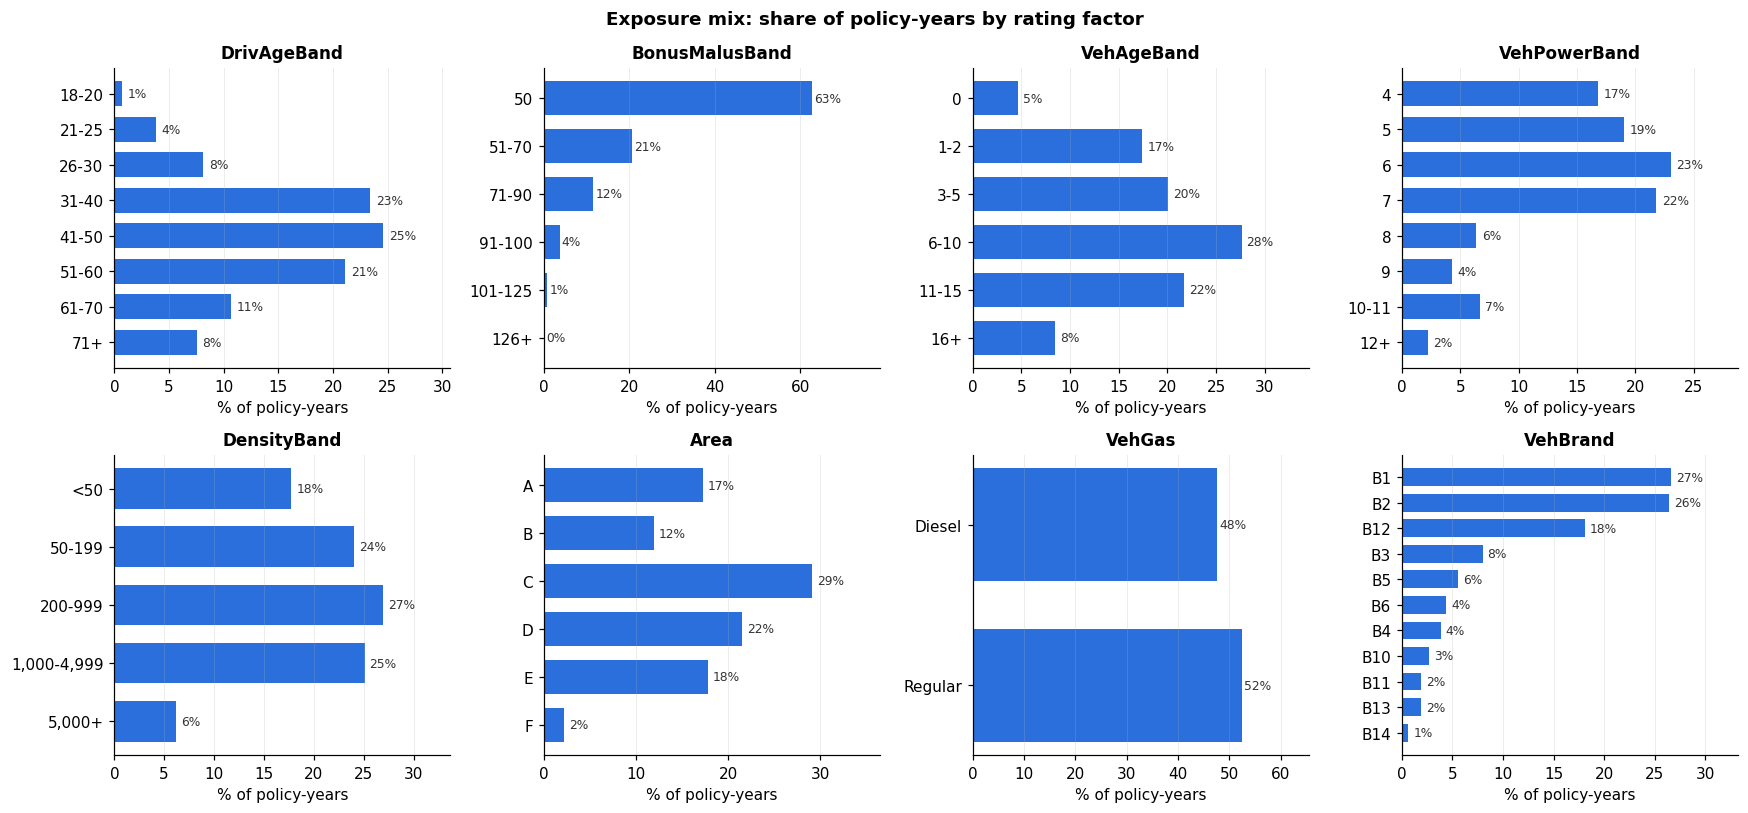

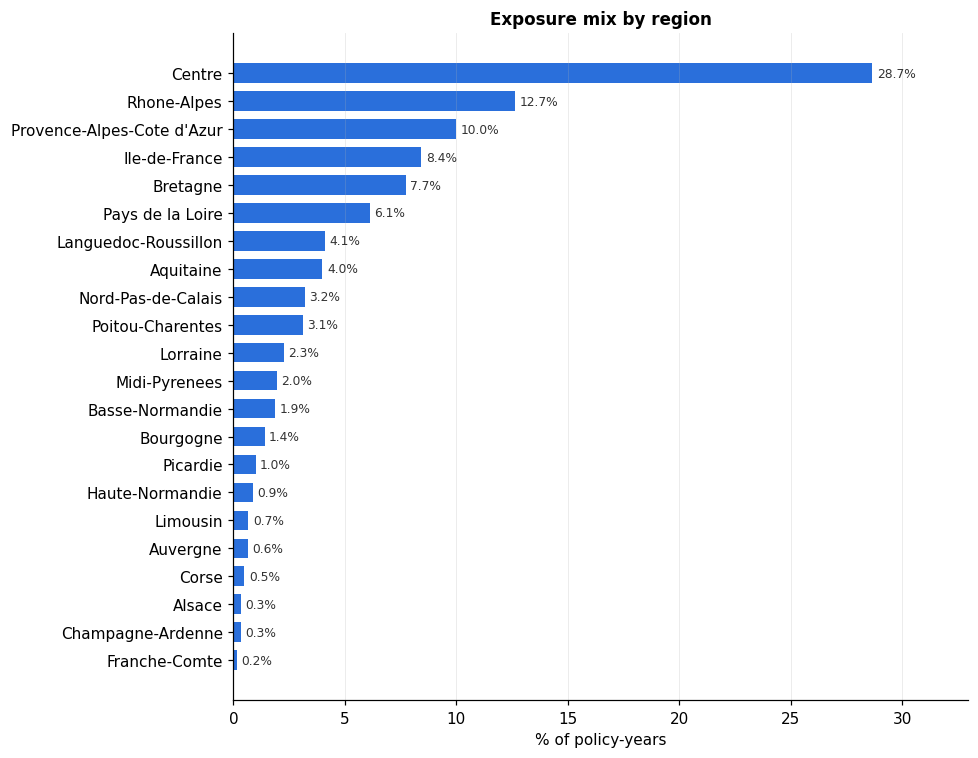

factor,largest band,largest %,smallest band,smallest %
DrivAgeBand,41-50,24.6,18-20,0.7
BonusMalusBand,50,62.8,126+,0.1
VehAgeBand,6-10,27.6,0,4.7
VehPowerBand,6,23.0,12+,2.2
DensityBand,200-999,27.0,"5,000+",6.2
Area,C,29.1,F,2.3
VehGas,Regular,52.4,Diesel,47.6
VehBrand,B1,26.6,B14,0.6
RegionName,Centre,28.7,Franche-Comte,0.2


In [ ]:
mix_factors = ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "VehPowerBand",
               "DensityBand", "Area", "VehGas", "VehBrand"]

def exposure_mix(col):
    t = policies.groupby(col, observed=True)["Exposure"].sum()
    return (t / t.sum() * 100)

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, col in zip(axes.flat, mix_factors):
    s = exposure_mix(col)
    if col == "VehBrand":                      # no natural order - sort by size
        s = s.sort_values(ascending=False)
    ax.barh(s.index.astype(str), s.values, color=MAIN_COLOR, height=0.7)
    ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlabel("% of policy-years")
    for y, v in enumerate(s.values):
        ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8, color="#333")
    ax.set_xlim(0, s.max() * 1.25)
    ax.grid(axis="y", visible=False)
fig.suptitle("Exposure mix: share of policy-years by rating factor", fontweight="bold")
fig.tight_layout(); plt.show()

# region has 22 levels - shown separately, sorted
reg = exposure_mix("RegionName").sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(reg.index, reg.values, color=MAIN_COLOR, height=0.7)
for y, v in enumerate(reg.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=8, color="#333")
ax.set_xlabel("% of policy-years"); ax.set_title("Exposure mix by region")
ax.set_xlim(0, reg.max() * 1.15); ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

# summary: largest and smallest band per factor
mix_summary = []
for col in mix_factors + ["RegionName"]:
    s = exposure_mix(col)
    mix_summary.append({"factor": col,
                        "largest band": str(s.idxmax()), "largest %": round(s.max(), 1),
                        "smallest band": str(s.idxmin()), "smallest %": round(s.min(), 1)})
display(pd.DataFrame(mix_summary).style.hide(axis="index").format({"largest %": "{:.1f}", "smallest %": "{:.1f}"}))

**Finding:**

**Most of the portfolio (who the insurer covers) is long-standing claim-free drivers; the other factors are more evenly spread**.

- 62.8% of policy-years are at the maximum bonus (BonusMalus band "50"), meaning nearly two-thirds of insured time comes from long-standing claim-free drivers. This is the only factor where one band clearly dominates.
- The largest driver age band is 41-50 (24.6%) and young drivers aged 18-20 make up only 0.7% of policy-years (partly because this band covers only 3 ages).
- The most common vehicle age is 6-10 years (27.6%), and fuel type is almost evenly split between Regular (52.4%) and Diesel (47.6%).
- The largest region is Centre (28.7%) and the smallest is Franche-Comte (0.2%).
- Several bands are very small: BonusMalus 126+ (0.1%), Franche-Comte (0.2%), vehicle brand B14 (0.6%) and drivers aged 18-20 (0.7%). Their claim rates will rest on little data, so they are checked against the reliability standard (Section 1.7) and may need merging before modelling.

## 2.4 What a typical claim costs


**What this step does:** describes the full range of claim costs, not just the average.

**Method:**
- **Percentiles**: the 50th percentile (median) is the cost that half of claims fall below; the 99th percentile is the cost that only 1% of claims exceed.
- **Skewness**: 0 means symmetric; a large positive value means a long tail of very expensive claims.
- **Histogram on a log scale**: claim costs range from a few euros to over a million, so a log scale is needed to see the whole range. The dashed lines mark the median and the mean.


statistic,claim cost (EUR)
minimum,1.00
1th percentile,39.69
10th percentile,197.35
25th percentile,685.99
50th percentile,"1,172.00"
75th percentile,"1,212.38"
90th percentile,"2,767.60"
95th percentile,"4,765.09"
99th percentile,"16,451.22"
99.9th percentile,"152,223.24"


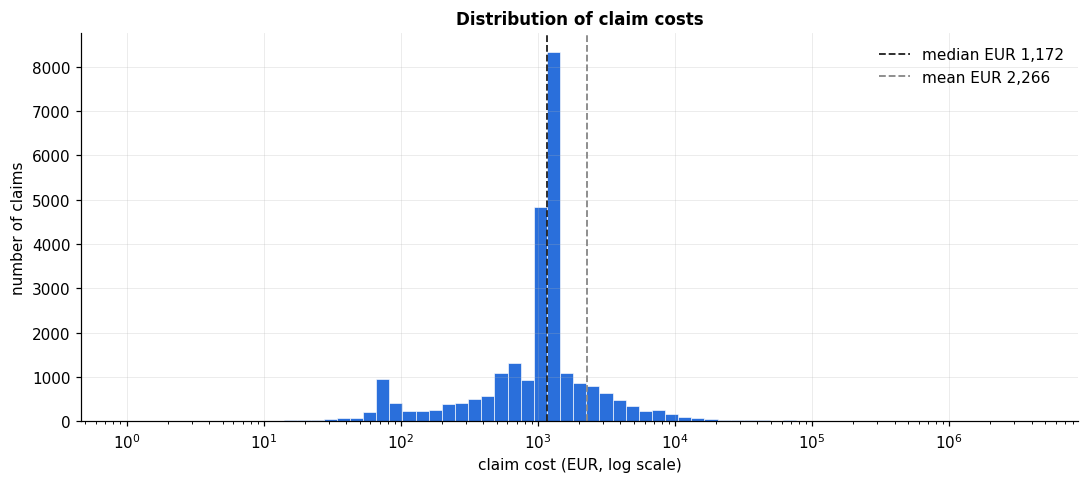

In [ ]:
amounts = claims["ClaimAmount"]
pcts = [0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
sev_pct = pd.DataFrame({
    "statistic": ["minimum"] + [f"{int(p * 1000) / 10:g}th percentile" for p in pcts] + ["maximum", "mean", "skewness"],
    "claim cost (EUR)": [amounts.min()] + [amounts.quantile(p) for p in pcts]
                        + [amounts.max(), amounts.mean(), amounts.skew()],
})
display(sev_pct.style.hide(axis="index").format({"claim cost (EUR)": "{:,.2f}"}))

fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.logspace(np.log10(amounts.min()), np.log10(amounts.max()), 70)
ax.hist(amounts, bins=bins, color=MAIN_COLOR, edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
ax.axvline(amounts.median(), color="#222", ls="--", lw=1.2, label=f"median EUR {amounts.median():,.0f}")
ax.axvline(amounts.mean(),   color="#888", ls="--", lw=1.2, label=f"mean EUR {amounts.mean():,.0f}")
ax.set_xlabel("claim cost (EUR, log scale)"); ax.set_ylabel("number of claims")
ax.set_title("Distribution of claim costs")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

**Finding:**

**Most claims are small and many are settled at a near-identical amount, but the cost distribution has a very long tail**.

- Half of all claims cost less than EUR 1,172 (median), and 90% cost less than EUR 2,768.
- The 50th and 75th percentiles (EUR 1,172 and EUR 1,212) are only EUR 40 apart, and the histogram shows a tall spike at this level: a large share of claims are settled at almost the same amount, the fixed-amount settlements identified in Section 1.4.
- The tail climbs steeply: the most expensive 1% of claims cost more than EUR 16,451 each, the most expensive 0.1% more than EUR 152,223, and the largest single claim is EUR 4,075,401.
- The mean (EUR 2,266) is almost double the median, and the skewness of 109.53 confirms a strongly right-skewed distribution: a small number of very expensive claims pull the average up.

## 2.5 How concentrated the cost is



This step answers *"what share of total claims cost comes from the largest 1% of claims?"*

**Method:**
1. Sort all costed claims from most to least expensive.
2. For the largest 0.1%, 1%, 5%, 10%, 20% and 50% of claims, calculate their share of total cost.
3. **Concentration curve**: plots the cumulative share of cost against the cumulative share of claims (largest first). If every claim cost the same, the curve would follow the diagonal; the further it bulges above the diagonal, the more concentrated the cost.
4. **Gini index**: one number for concentration, from 0 (every claim costs the same) to 1 (one claim makes up all of the cost).
5. The same idea at policy level: what share of policies generates all of the cost.

largest claims,number of claims,share of total cost (%),smallest claim in group (EUR)
top 0.1%,27,21.600000,"152,333"
top 1%,265,38.000000,"16,510"
top 5%,"1,323",52.100000,"4,766"
top 10%,"2,645",59.900000,"2,768"
top 20%,"5,289",68.800000,"1,462"
top 50%,"13,222",84.900000,"1,172"


Gini index of claim costs: 0.641


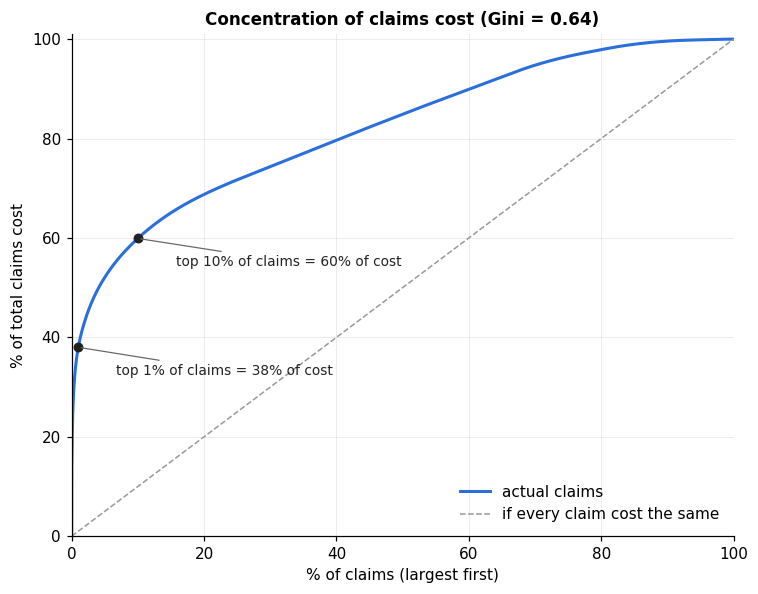

Policies with any recorded claim cost: 3.68% of all policies (they generate 100% of recorded cost)
The most expensive 1% of policies generate 73.9% of recorded cost


In [ ]:
amt_desc = np.sort(claims["ClaimAmount"].to_numpy())[::-1]
total_cost = amt_desc.sum()
n_claims = len(amt_desc)

conc = []
for p in [0.001, 0.01, 0.05, 0.10, 0.20, 0.50]:
    k = max(1, int(np.ceil(n_claims * p)))
    conc.append({"largest claims": f"top {p * 100:g}%",
                 "number of claims": k,
                 "share of total cost (%)": round(amt_desc[:k].sum() / total_cost * 100, 1),
                 "smallest claim in group (EUR)": round(amt_desc[k - 1], 0)})
conc = pd.DataFrame(conc)
display(conc.style.hide(axis="index").format({"number of claims": "{:,}", "smallest claim in group (EUR)": "{:,.0f}"}))

# Gini index (from the ascending Lorenz curve)
asc = np.sort(amt_desc)
lorenz = np.concatenate([[0], np.cumsum(asc) / total_cost])
gini = 1 - 2 * np.trapezoid(lorenz, dx=1 / n_claims) if hasattr(np, "trapezoid") else 1 - 2 * np.trapz(lorenz, dx=1 / n_claims)
print(f"Gini index of claim costs: {gini:.3f}")

# concentration curve (largest claims first)
x = np.arange(0, n_claims + 1) / n_claims * 100
y = np.concatenate([[0], np.cumsum(amt_desc) / total_cost * 100])
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(x, y, color=MAIN_COLOR, lw=2, label="actual claims")
ax.plot([0, 100], [0, 100], color="#999", ls="--", lw=1, label="if every claim cost the same")
for p in [1, 10]:
    share = conc.loc[conc["largest claims"] == f"top {p:g}%", "share of total cost (%)"].iloc[0]
    ax.scatter([p], [share], color="#222", s=30, zorder=3)
    ax.annotate(f"top {p}% of claims = {share:.0f}% of cost", (p, share), xytext=(25, -18),
                textcoords="offset points", fontsize=9, color="#222",
                arrowprops=dict(arrowstyle="-", color="#666", lw=0.8))
ax.set_xlabel("% of claims (largest first)"); ax.set_ylabel("% of total claims cost")
ax.set_xlim(0, 100); ax.set_ylim(0, 101)
ax.set_title(f"Concentration of claims cost (Gini = {gini:.2f})")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

# policy-level view
pol_cost = policies["ClaimAmount"]
pct_pol_with_cost = (pol_cost > 0).mean() * 100
top1_pol_share = np.sort(pol_cost.to_numpy())[::-1][: int(np.ceil(len(pol_cost) * 0.01))].sum() / pol_cost.sum() * 100
print(f"Policies with any recorded claim cost: {pct_pol_with_cost:.2f}% of all policies (they generate 100% of recorded cost)")
print(f"The most expensive 1% of policies generate {top1_pol_share:.1f}% of recorded cost")

**Finding:**

**A small share of claims drives a large share of the cost**.

- The largest 1% of claims (each above EUR 16,510) account for 38% of total claims cost, and the largest 10% account for ~60%.
- The Gini index of 0.64 confirms that claim costs are highly unequal (0 = every claim costs the same, 1 = one claim is all the cost).
- At policy level, only 3.68% of policies have any recorded claim cost, and the most expensive 1% of policies generate approx. 74% of said claim cost.

## **Conclusion - Objective 1:**


- Claims are rare: the portfolio has a claim frequency of 0.1 per policy-year (about 10 claims per 100 cars per year), and almost 95% of policies made no claim.
- An average claim costs EUR 2,266, but half cost less than EUR 1,172; the cost distribution is strongly right-skewed.
- The estimated pure premium (expected claims cost per car per year) is EUR 227.94.
- Cost is highly concentrated: the largest 1% of claims make up 38% of total cost (Gini 0.64).
- The portfolio is dominated by customers with long claim-free history  (e.g. 62.8% of policy-years at the maximum no-claims bonus).

**Business implications**
1. Because a few large claims drive a large share of cost, the insurer's results are volatile: one or two very large claims can swing a year's profit. This supports reinsurance or a large-claim loading, and it means large claims must be handled separately in pricing (Section 4) so that they do not distort the price of ordinary risks.
2. With most claims being small and many settled at fixed amounts, claims-handling efficiency on small claims matters for cost control, while underwriting attention should focus on what drives the large ones.
3. With most of the portfolio at the maximum bonus, a large share of customers already pays the lowest bonus-malus price; any underpricing of these customers (tested in Section 6) would affect a large part of the book.

**Limitations**
- Around 27% of reported claims have no recorded cost; the pure premium assumes they cost the same on average as recorded claims.
- The data covers one year only, so year-to-year volatility and trends cannot be measured.
- Claim amounts are not adjusted for inflation or for claims that may still develop after the data was extracted.

# Risk drivers - one-way analysis

**Objective 2: Identify the drivers of claim frequency and severity**
- Which rating factors drive **how often** people claim (frequency)?
- Which drive **how much** claims cost (severity)?
- Are they the same factors?

**Key terms**
- **One-way analysis**: looks at one factor at a time, e.g. claim frequency for each driver age band.
- **Relativity**: a band's rate divided by the portfolio average. 1.00 = average, 1.50 = 50% above average, 0.80 = 20% below. This is how insurers express price differences between groups.
- **Spread**: the highest relativity divided by the lowest, among bands with enough data. A spread of 2.0 means the riskiest band claims twice as often (or twice as expensively) as the safest. It measures how much a factor matters in practice.
- **Statistical test**: checks whether the differences between bands are real or could be chance. With this much data almost every factor is "significant", so the spread is the better guide to how much a factor matters.

## 3.0 Initial setup


This step attaches the bands to each claim, and sets the portfolio averages that every band is compared against.

for severity, very large claims are capped at the 99th percentile *for this section only*. Without the cap, a single multi-million claim landing in one band would make that band look expensive purely by chance. The cap applies only to the severity comparisons in this section; the formal large-claim treatment is decided in Section 4.

In [ ]:
factors = ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "VehPowerBand", "DensityBand",
           "Area", "VehGas", "VehBrand", "RegionName"]
unordered = ["VehBrand", "RegionName"]          # no natural order - sorted by relativity in charts

claims_b = claims.merge(policies[["IDpol"] + band_cols + ["RegionName"]], on="IDpol", how="left")

port_freq = policies["ClaimNb_model"].sum() / policies["Exposure"].sum()
SEV_CAP = claims_b["ClaimAmount"].quantile(0.99)
claims_b["ClaimAmount_capped"] = claims_b["ClaimAmount"].clip(upper=SEV_CAP)
port_sev = claims_b["ClaimAmount_capped"].mean()

MIN_PY_SHARE = 1.0     # frequency spread: only bands with >= 1% of policy-years
MIN_SEV_CLAIMS = 200   # severity spread: only bands with >= 200 costed claims

print(f"Portfolio claim frequency:           {port_freq:.4f} claims per policy-year")
print(f"Severity cap (99th percentile):      EUR {SEV_CAP:,.0f}  "
      f"({(claims_b['ClaimAmount'] > SEV_CAP).sum():,} claims above it)")
print(f"Portfolio average severity (capped): EUR {port_sev:,.0f}")

Portfolio claim frequency:           0.1006 claims per policy-year
Severity cap (99th percentile):      EUR 16,451  (265 claims above it)
Portfolio average severity (capped): EUR 1,569


## 3.1 Which factors drive claim frequency


For every rating factor, the claim frequency of each band is calculated and compared with the portfolio average.

**Method:**
- **Frequency** = claims ÷ policy-years in the band; **relativity** = band frequency ÷ portfolio frequency.
- **Spread** is calculated only over bands with at least 1% of policy-years, so a tiny, noisy band cannot exaggerate it.

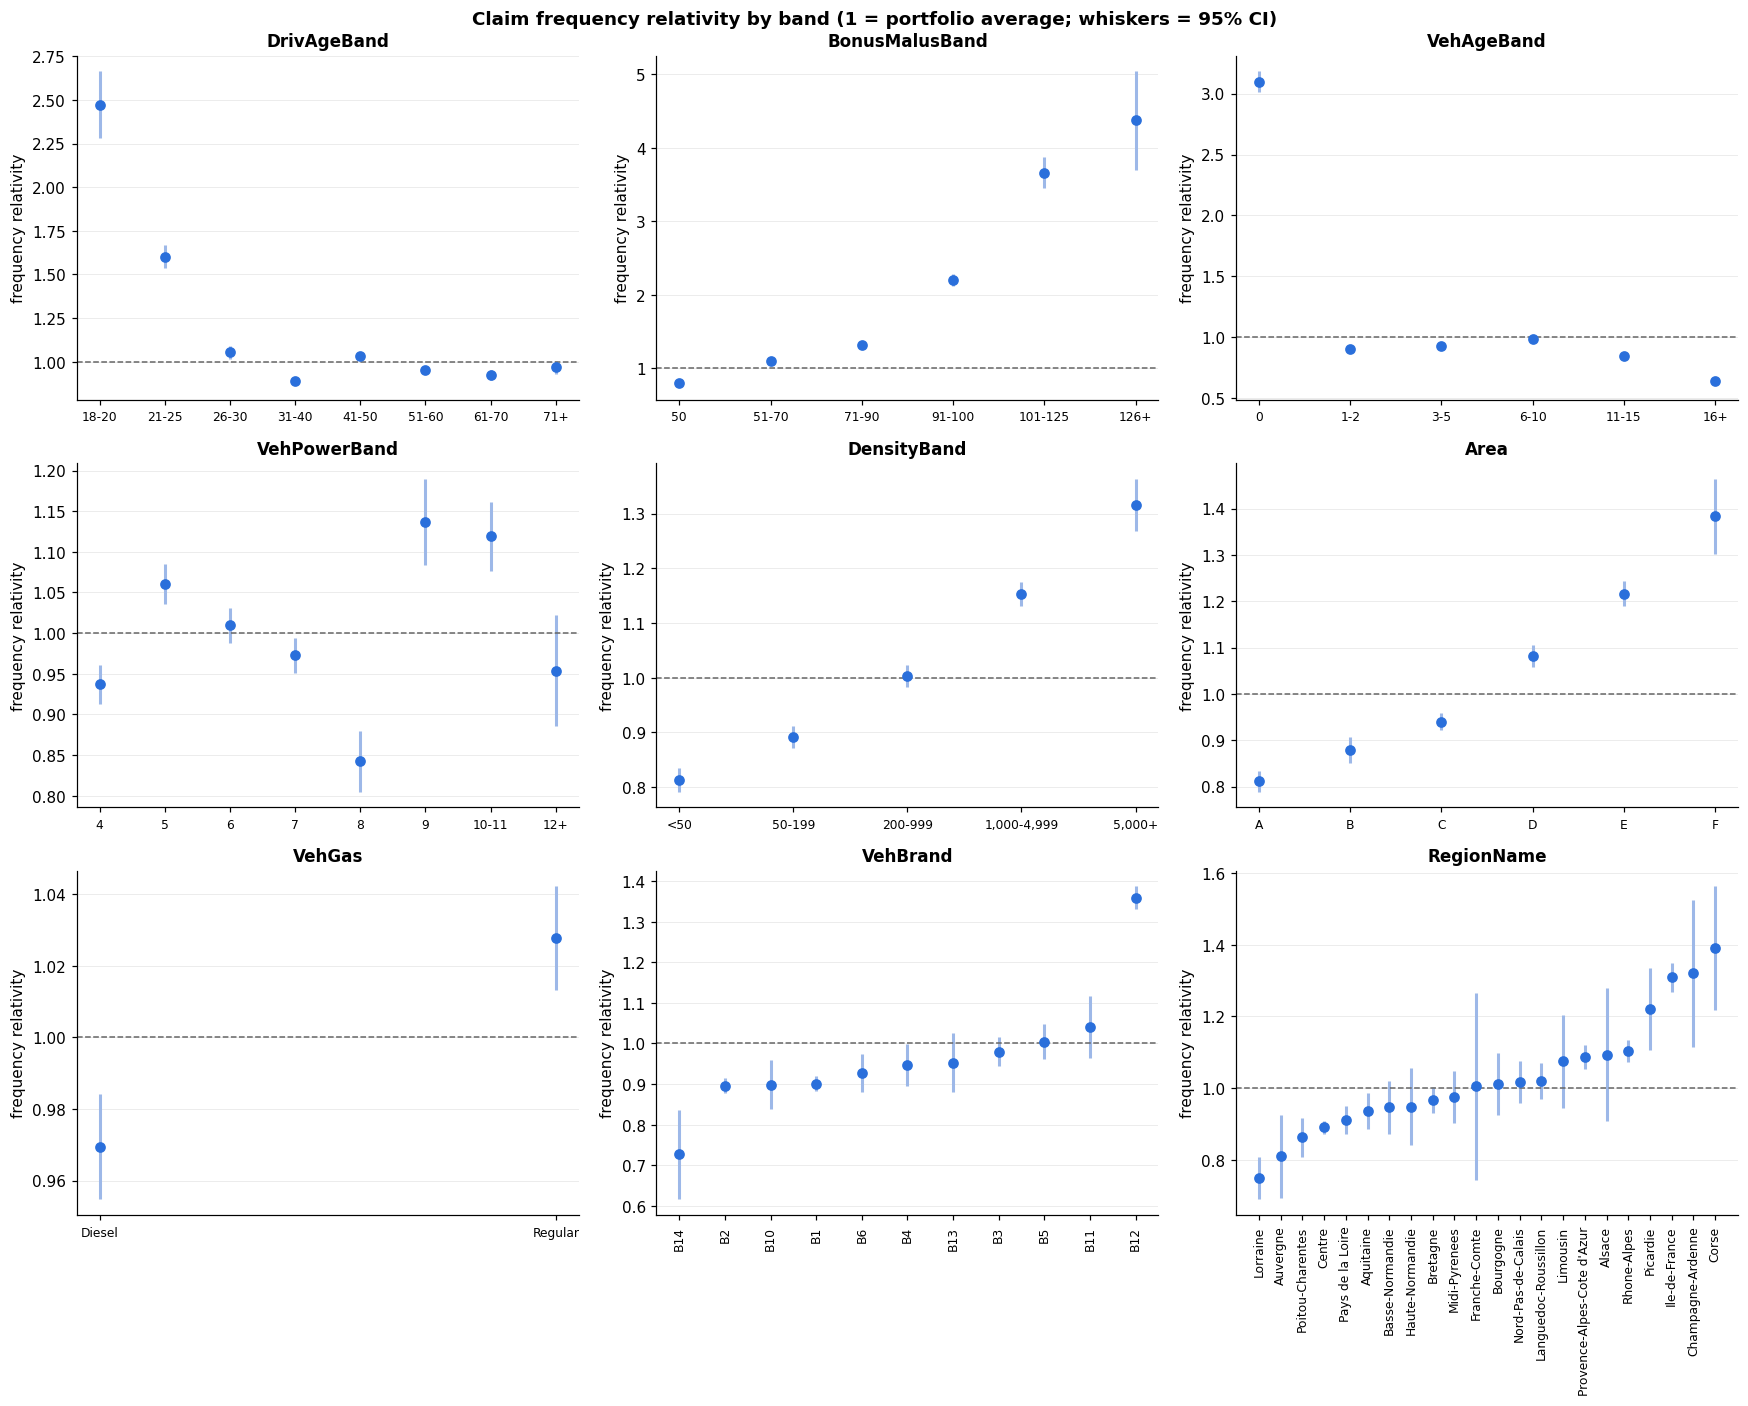

Frequency drivers, ranked by spread:


factor,bands,LR statistic,df,p_value,lowest band,lowest rel.,highest band,highest rel.,spread
VehAgeBand,6,"5,463.3",5,0.0e+00,16+,0.64,0,3.10,4.81
BonusMalusBand,6,"4,481.0",5,0.0e+00,50,0.80,91-100,2.20,2.77
DrivAgeBand,8,983.8,7,3.9e-208,31-40,0.89,21-25,1.60,1.80
RegionName,22,641.0,21,3.7e-122,Lorraine,0.75,Ile-de-France,1.31,1.75
Area,6,781.0,5,1.5e-166,A,0.81,F,1.38,1.71
DensityBand,5,747.2,4,2.1e-160,<50,0.81,"5,000+",1.32,1.62
VehBrand,11,"1,002.9",10,4.4e-209,B2,0.90,B12,1.36,1.52
VehPowerBand,8,177.6,7,6.3e-35,8,0.84,9,1.14,1.35
VehGas,2,30.5,1,3.3e-08,Diesel,0.97,Regular,1.03,1.06


In [ ]:
def one_way_freq(col):
    t = (policies.groupby(col, observed=True)
                 .agg(policy_years=("Exposure", "sum"), claims=("ClaimNb_model", "sum")))
    t["pct_policy_years"] = t["policy_years"] / t["policy_years"].sum() * 100
    t["frequency"] = t["claims"] / t["policy_years"]
    t["relativity"] = t["frequency"] / port_freq
    se = np.sqrt(t["claims"]) / t["policy_years"]
    t["rel_low"]  = ((t["frequency"] - 1.96 * se) / port_freq).clip(lower=0)
    t["rel_high"] = (t["frequency"] + 1.96 * se) / port_freq
    return t

def spread_info(rel):
    '''lowest/highest band and spread among credible bands (NaN if fewer than 2 bands qualify)'''
    if len(rel) < 2:
        return {"lowest band": "-", "lowest rel.": np.nan, "highest band": "-", "highest rel.": np.nan, "spread": np.nan}
    return {"lowest band": str(rel.idxmin()), "lowest rel.": round(rel.min(), 2),
            "highest band": str(rel.idxmax()), "highest rel.": round(rel.max(), 2),
            "spread": round(rel.max() / rel.min(), 2)}

def lr_test(t):
    c, r = t["claims"].to_numpy(), t["frequency"].to_numpy()
    lr = 2 * np.sum(np.where(c > 0, c * np.log(np.where(c > 0, r, 1) / port_freq), 0.0))
    dof = len(t) - 1
    return lr, dof, chi2.sf(lr, dof)

freq_tables, freq_summary = {}, []
for col in factors:
    t = one_way_freq(col)
    freq_tables[col] = t
    lr, dof, p = lr_test(t)
    cred = t[t["pct_policy_years"] >= MIN_PY_SHARE]
    freq_summary.append({"factor": col, "bands": len(t), "LR statistic": round(lr, 1), "df": dof,
                         "p_value": f"{p:.1e}", **spread_info(cred["relativity"])})
freq_summary = pd.DataFrame(freq_summary).sort_values("spread", ascending=False)

# chart: relativity with 95% CI per band
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, col in zip(axes.flat, factors):
    t = freq_tables[col].copy()
    if col in unordered:
        t = t.sort_values("relativity")
    xs = np.arange(len(t))
    ax.errorbar(xs, t["relativity"], yerr=[t["relativity"] - t["rel_low"], t["rel_high"] - t["relativity"]],
                fmt="o", color=MAIN_COLOR, ecolor="#9db8e8", elinewidth=2, capsize=0, markersize=6)
    ax.axhline(1, color="#666", ls="--", lw=1)
    ax.set_xticks(xs)
    ax.set_xticklabels(t.index.astype(str), rotation=90 if len(t) > 8 else 0, fontsize=8)
    ax.set_title(col); ax.set_ylabel("frequency relativity")
    ax.grid(axis="x", visible=False)
fig.suptitle("Claim frequency relativity by band (1 = portfolio average; whiskers = 95% CI)", fontweight="bold")
fig.tight_layout(); plt.show()

print("Frequency drivers, ranked by spread:")
display(freq_summary.style.hide(axis="index").format({"LR statistic": "{:,.1f}", "lowest rel.": "{:.2f}",
                                                      "highest rel.": "{:.2f}", "spread": "{:.2f}"}))

In [ ]:
# detail tables - the numbers behind the chart
for col in factors:
    t = freq_tables[col]
    print(f"\n{col}")
    display(t[["policy_years", "pct_policy_years", "claims", "frequency", "relativity", "rel_low", "rel_high"]]
            .style.format({"policy_years": "{:,.0f}", "pct_policy_years": "{:.1f}", "claims": "{:,}",
                           "frequency": "{:.4f}", "relativity": "{:.2f}", "rel_low": "{:.2f}", "rel_high": "{:.2f}"}))


DrivAgeBand


,policy_years,pct_policy_years,claims,frequency,relativity,rel_low,rel_high
DrivAgeBand,,,,,,,
18-20,"2,585",0.7,643,0.2488,2.47,2.28,2.66
21-25,"13,643",3.8,"2,198",0.1611,1.60,1.53,1.67
26-30,"29,167",8.1,"3,093",0.1060,1.05,1.02,1.09
31-40,"83,898",23.4,"7,522",0.0897,0.89,0.87,0.91
41-50,"88,100",24.6,"9,165",0.1040,1.03,1.01,1.06
51-60,"75,700",21.1,"7,254",0.0958,0.95,0.93,0.97
61-70,"38,321",10.7,"3,558",0.0928,0.92,0.89,0.95
71+,"26,947",7.5,"2,623",0.0973,0.97,0.93,1.00



BonusMalusBand


,policy_years,pct_policy_years,claims,frequency,relativity,rel_low,rel_high
BonusMalusBand,,,,,,,
50,"225,153",62.8,"18,010",0.0800,0.80,0.78,0.81
51-70,"74,443",20.8,"8,224",0.1105,1.10,1.07,1.12
71-90,"41,799",11.7,"5,516",0.1320,1.31,1.28,1.35
91-100,"13,395",3.7,"2,964",0.2213,2.20,2.12,2.28
101-125,"3,198",0.9,"1,178",0.3684,3.66,3.45,3.87
126+,373,0.1,164,0.4396,4.37,3.70,5.04



VehAgeBand


...

,policy_years,pct_policy_years,claims,frequency,relativity,rel_low,rel_high
VehGas,,,,,,,
Diesel,"170,588",47.6,"16,640",0.0975,0.97,0.95,0.98
Regular,"187,773",52.4,"19,416",0.1034,1.03,1.01,1.04



VehBrand


,policy_years,pct_policy_years,claims,frequency,relativity,rel_low,rel_high
VehBrand,,,,,,,
B1,"95,315",26.6,"8,639",0.0906,0.90,0.88,0.92
B10,"9,490",2.6,858,0.0904,0.90,0.84,0.96
B11,"6,883",1.9,721,0.1047,1.04,0.97,1.12
B12,"64,802",18.1,"8,859",0.1367,1.36,1.33,1.39
B13,"6,768",1.9,649,0.0959,0.95,0.88,1.03
B14,"2,271",0.6,166,0.0731,0.73,0.62,0.84
B2,"94,824",26.5,"8,552",0.0902,0.90,0.88,0.92
B3,"28,576",8.0,"2,818",0.0986,0.98,0.94,1.02
B4,"13,770",3.8,"1,312",0.0953,0.95,0.90,1.00



RegionName


,policy_years,pct_policy_years,claims,frequency,relativity,rel_low,rel_high
RegionName,,,,,,,
Alsace,"1,209",0.3,133,0.1100,1.09,0.91,1.28
Aquitaine,"14,316",4.0,"1,348",0.0942,0.94,0.89,0.99
Auvergne,"2,322",0.6,189,0.0814,0.81,0.69,0.92
Basse-Normandie,"6,653",1.9,633,0.0952,0.95,0.87,1.02
Bourgogne,"5,023",1.4,511,0.1017,1.01,0.92,1.10
Bretagne,"27,753",7.7,"2,702",0.0974,0.97,0.93,1.00
Centre,"102,706",28.7,"9,197",0.0895,0.89,0.87,0.91
Champagne-Ardenne,"1,204",0.3,160,0.1329,1.32,1.12,1.53
Corse,"1,766",0.5,247,0.1399,1.39,1.22,1.56


**Finding:**

**Vehicle age and bonus-malus have the biggest effect on how often people claim**.

- Vehicle age has the largest spread (4.84), but this comes almost entirely from one band: brand-new vehicles (age 0) claim 3.10x the portfolio average. All other vehicle-age bands are below average, falling from about 0.99x (6-10 years) to 0.64x (16+ years). Because the new-vehicle band pulls the portfolio average up, every other band sits below 1. A jump this large for new cars alone is unusual and is worth checking further, as it may reflect policy behaviour (e.g. new cars insured mid-year) rather than the vehicle itself.
- Bonus-malus ranks second (spread 2.75): customers in band 91-100, which includes new drivers starting at 100, claim 2.20x the average, against 0.80x for customers at the maximum bonus (50). This matches how the bonus-malus system works: it rewards a claim-free history.
- Driver age follows (spread 1.80): drivers aged 21-25 claim 1.60x the average, against 0.89x for drivers aged 31-40. The 18-20 band is not in the spread because it holds less than 1% of policy-years; its own relativity is shown in the detail table.
- Location matters too: Region (spread 1.75; Ile-de-France 1.31x vs Lorraine 0.75x), Area (spread 1.70; F 1.38x vs A 0.81x) and Density (spread 1.63; "5,000+" 1.32x vs "< 50" 0.81x) all show that drivers in denser, urban areas claim more often. These three factors measure similar things and are checked for overlap in 3.4.
- Vehicle brand (spread 1.51) and vehicle power (spread 1.36) have a moderate effect, while fuel type barely matters (Regular 1.03x vs Diesel 0.97x, spread 1.06).
- All 9 factors are statistically significant (p-values of 3.3e-08 or smaller), so significance alone cannot tell them apart (need to use the spread to show which ones matter in practice).

## 3.2 Which factors drive claim severity



For every rating factor, I compare the average cost of a claim in each band with the portfolio average.

**Method:**
- **Average severity** uses claim costs capped at the 99th percentile (see 3.0), so one huge claim cannot distort a band. The **median** (uncapped) is shown alongside as a robustness check.
- **Relativity** = band average severity ÷ portfolio average severity, with a 95% confidence interval.
- **Spread** is calculated only over bands with at least 200 costed claims.

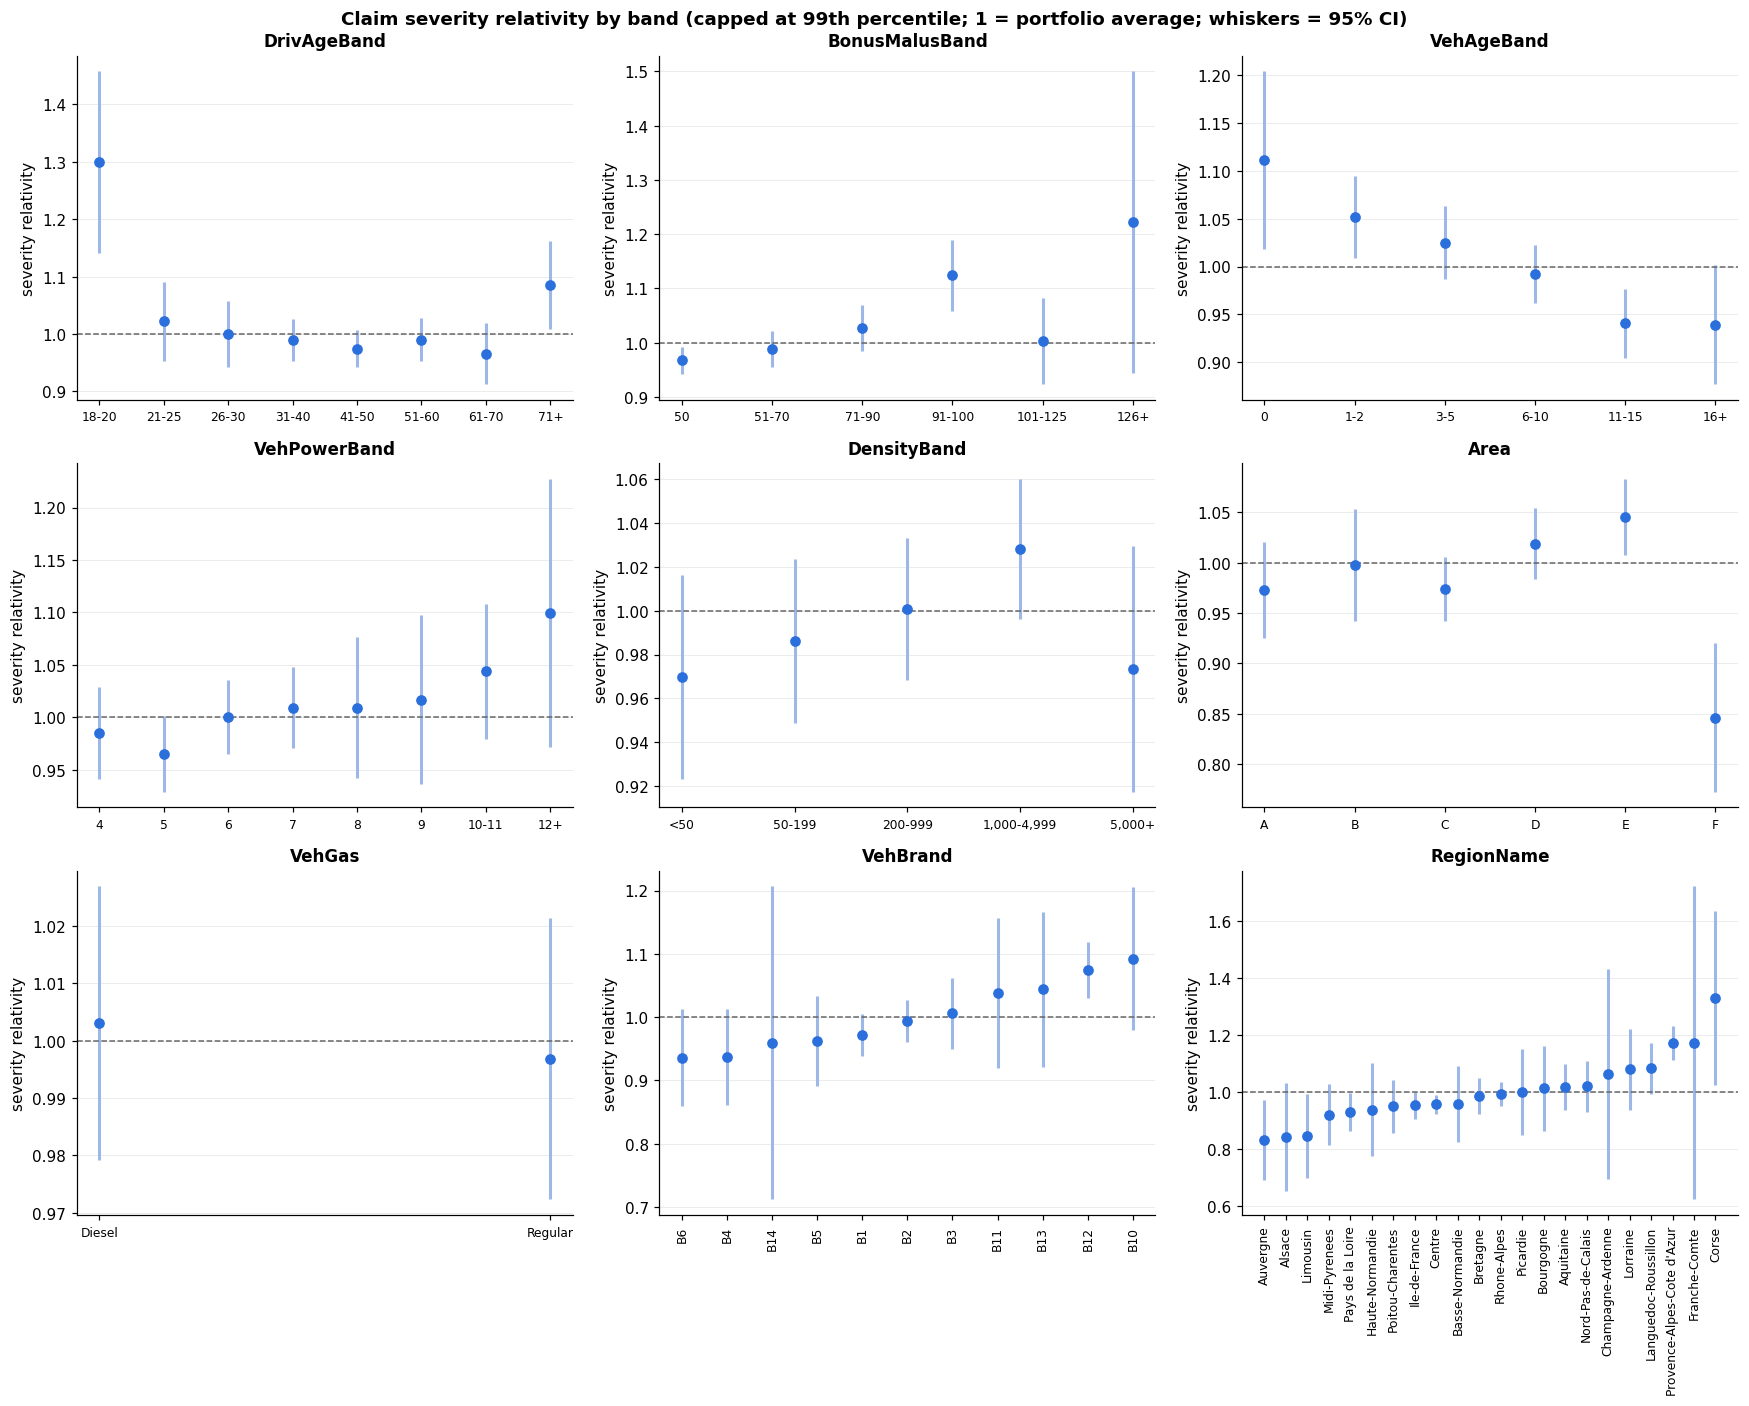

Severity drivers, ranked by spread:


factor,bands,KW statistic,p_value,epsilon_sq,lowest band,lowest rel.,highest band,highest rel.,spread
DrivAgeBand,8,55.900000,9.8e-10,0.001900,61-70,0.970000,18-20,1.300000,1.350000
RegionName,22,114.000000,8.9e-15,0.003500,Midi-Pyrenees,0.920000,Provence-Alpes-Cote d'Azur,1.170000,1.270000
Area,6,7.500000,1.8e-01,0.000100,F,0.850000,E,1.050000,1.240000
VehAgeBand,6,61.500000,6.1e-12,0.002100,16+,0.940000,0,1.110000,1.180000
VehBrand,11,249.500000,7.0e-48,0.009100,B6,0.940000,B10,1.090000,1.170000
BonusMalusBand,6,56.100000,7.7e-11,0.001900,50,0.970000,91-100,1.120000,1.160000
VehPowerBand,8,27.500000,2.8e-04,0.000800,5,0.970000,12+,1.100000,1.140000
DensityBand,5,5.000000,2.9e-01,0.000000,<50,0.970000,"1,000-4,999",1.030000,1.060000
VehGas,2,2.900000,9.1e-02,0.000100,Regular,1.000000,Diesel,1.000000,1.010000


In [ ]:
def one_way_sev(col):
    g = claims_b.groupby(col, observed=True)
    t = g.agg(claims=("ClaimAmount", "size"), avg_severity=("ClaimAmount_capped", "mean"),
              sd=("ClaimAmount_capped", "std"), median_severity=("ClaimAmount", "median"))
    t["relativity"] = t["avg_severity"] / port_sev
    se = t["sd"] / np.sqrt(t["claims"])
    t["rel_low"]  = ((t["avg_severity"] - 1.96 * se) / port_sev).clip(lower=0)
    t["rel_high"] = (t["avg_severity"] + 1.96 * se) / port_sev
    return t.drop(columns="sd")

def kw_test(col):
    groups = [g["ClaimAmount"].to_numpy() for _, g in claims_b.groupby(col, observed=True) if len(g) > 1]
    h, p = kruskal(*groups)
    n, k = sum(len(g) for g in groups), len(groups)
    return h, p, max((h - k + 1) / (n - k), 0)

sev_tables, sev_summary = {}, []
for col in factors:
    t = one_way_sev(col)
    sev_tables[col] = t
    h, p, eps2 = kw_test(col)
    cred = t[t["claims"] >= MIN_SEV_CLAIMS]
    sev_summary.append({"factor": col, "bands": len(t), "KW statistic": round(h, 1), "p_value": f"{p:.1e}",
                        "epsilon_sq": round(eps2, 4), **spread_info(cred["relativity"])})
sev_summary = pd.DataFrame(sev_summary).sort_values("spread", ascending=False)

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, col in zip(axes.flat, factors):
    t = sev_tables[col].copy()
    if col in unordered:
        t = t.sort_values("relativity")
    xs = np.arange(len(t))
    ax.errorbar(xs, t["relativity"], yerr=[t["relativity"] - t["rel_low"], t["rel_high"] - t["relativity"]],
                fmt="o", color=MAIN_COLOR, ecolor="#9db8e8", elinewidth=2, capsize=0, markersize=6)
    ax.axhline(1, color="#666", ls="--", lw=1)
    ax.set_xticks(xs)
    ax.set_xticklabels(t.index.astype(str), rotation=90 if len(t) > 8 else 0, fontsize=8)
    ax.set_title(col); ax.set_ylabel("severity relativity")
    ax.grid(axis="x", visible=False)
fig.suptitle("Claim severity relativity by band (capped at 99th percentile; 1 = portfolio average; whiskers = 95% CI)",
             fontweight="bold")
fig.tight_layout(); plt.show()

print("Severity drivers, ranked by spread:")
display(sev_summary.style.hide(axis="index"))

In [ ]:
# detail tables - the numbers behind the chart
for col in factors:
    t = sev_tables[col]
    print(f"\n{col}")
    display(t.style.format({"claims": "{:,}", "avg_severity": "{:,.0f}", "median_severity": "{:,.0f}",
                            "relativity": "{:.2f}", "rel_low": "{:.2f}", "rel_high": "{:.2f}"}))


DrivAgeBand


,claims,avg_severity,median_severity,relativity,rel_low,rel_high
DrivAgeBand,,,,,,
18-20,617,"2,040","1,172",1.30,1.14,1.46
21-25,"1,786","1,605","1,172",1.02,0.95,1.09
26-30,"2,379","1,569","1,128",1.00,0.94,1.06
31-40,"5,800","1,552","1,153",0.99,0.95,1.03
41-50,"6,660","1,529","1,172",0.97,0.94,1.01
51-60,"5,233","1,554","1,172",0.99,0.95,1.03
61-70,"2,359","1,516","1,172",0.97,0.91,1.02
71+,"1,610","1,703","1,172",1.09,1.01,1.16



BonusMalusBand


,claims,avg_severity,median_severity,relativity,rel_low,rel_high
BonusMalusBand,,,,,,
50,"11,592","1,518","1,172",0.97,0.94,0.99
51-70,"6,692","1,551","1,150",0.99,0.95,1.02
71-90,"4,518","1,611","1,172",1.03,0.98,1.07
91-100,"2,386","1,764","1,172",1.12,1.06,1.19
101-125,"1,093","1,574","1,172",1.00,0.92,1.08
126+,163,"1,918","1,172",1.22,0.94,1.50



VehAgeBand


...

,claims,avg_severity,median_severity,relativity,rel_low,rel_high
VehGas,,,,,,
Diesel,"13,450","1,574","1,172",1.00,0.98,1.03
Regular,"12,994","1,564","1,172",1.00,0.97,1.02



VehBrand


,claims,avg_severity,median_severity,relativity,rel_low,rel_high
VehBrand,,,,,,
B1,"6,898","1,525","1,128",0.97,0.94,1.00
B10,765,"1,714","1,165",1.09,0.98,1.21
B11,664,"1,629","1,128",1.04,0.92,1.16
B12,"4,200","1,686","1,204",1.07,1.03,1.12
B13,539,"1,638","1,172",1.04,0.92,1.17
B14,131,"1,506","1,128",0.96,0.71,1.21
B2,"6,805","1,561","1,172",0.99,0.96,1.03
B3,"2,429","1,579","1,172",1.01,0.95,1.06
B4,"1,099","1,471","1,128",0.94,0.86,1.01



RegionName


,claims,avg_severity,median_severity,relativity,rel_low,rel_high
RegionName,,,,,,
Alsace,92,"1,320","1,172",0.84,0.65,1.03
Aquitaine,"1,055","1,596","1,172",1.02,0.94,1.10
Auvergne,141,"1,305","1,204",0.83,0.69,0.97
Basse-Normandie,452,"1,503","1,128",0.96,0.82,1.09
Bourgogne,345,"1,590","1,172",1.01,0.86,1.16
Bretagne,"1,871","1,548","1,147",0.99,0.92,1.05
Centre,"6,475","1,501","1,128",0.96,0.92,0.99
Champagne-Ardenne,77,"1,670","1,204",1.06,0.70,1.43
Corse,132,"2,087","1,204",1.33,1.03,1.63


**Finding:**

**Claim severity varies much less between groups than claim frequency**.

- Severity spreads range only from 1.01 (fuel type) to 1.35 (driver age), compared with frequency spreads which is up to 4.84 (vehicle age) and 2.75 (bonus-malus). Who the customer is changes how often they claim far more than how much a claim costs.
- Driver age has the largest severity spread (1.35): a claim by a driver aged 18-20 costs 1.30x the portfolio average, against 0.97x for drivers aged 61-70. Region follows (spread 1.27): claims in Provence-Alpes-Cote d'Azur cost 1.17x the average, against 0.92x in Midi-Pyrenees.
- Six of the nine factors show a statistically significant difference in claim cost (p < 0.05), but every effect size is negligible: the largest epsilon-squared is 0.0091 (vehicle brand), so no factor explains even 1% of the variation in claim cost.
- Area (p = 0.18), density (p = 0.29) and fuel type (p = 0.091) show no significant difference at all. Area's spread of 1.24 therefore likely reflects a few larger claims rather than a genuine difference in typical claim cost.

## 3.3 Frequency drivers vs severity drivers



This step puts the two analyses side by side to answer *"are the same factors driving both?"*

**Method:**
- Each factor is placed on a chart by its frequency spread (horizontal) and severity spread (vertical).
-- A factor is called a **material driver** if its spread is at least **1.25** (the highest band is at least 25% above the lowest) **and** its test is significant at the 1% level (p < 0.01). The 1.25 threshold is a practical judgement, not a statistical standard: differences smaller than this rarely justify a separate pricing factor. A sensitivity table below shows how the result changes at other thresholds. Epsilon-squared is reported for context but not used in the rule, because it measures how well a factor explains *individual* claims, which is always low in insurance, whereas pricing depends on differences in *average* cost between groups.
- Factors in the top-right corner drive both; top-left drive mainly severity; bottom-right mainly frequency; bottom-left neither.

factor,freq_spread,freq_p,sev_spread,sev_p,sev_epsilon_sq,drives
DrivAgeBand,1.80,3.9e-208,1.35,9.8e-10,0.0019,frequency and severity
RegionName,1.75,3.7e-122,1.27,8.9e-15,0.0035,frequency and severity
VehAgeBand,4.81,0.0e+00,1.18,6.1e-12,0.0021,frequency only
BonusMalusBand,2.77,0.0e+00,1.16,7.7e-11,0.0019,frequency only
Area,1.71,1.5e-166,1.24,1.8e-01,0.0001,frequency only
DensityBand,1.62,2.1e-160,1.06,2.9e-01,0.0000,frequency only
VehBrand,1.52,4.4e-209,1.17,7.0e-48,0.0091,frequency only
VehPowerBand,1.35,6.3e-35,1.14,2.8e-04,0.0008,frequency only
VehGas,1.06,3.3e-08,1.01,9.1e-02,0.0001,neither


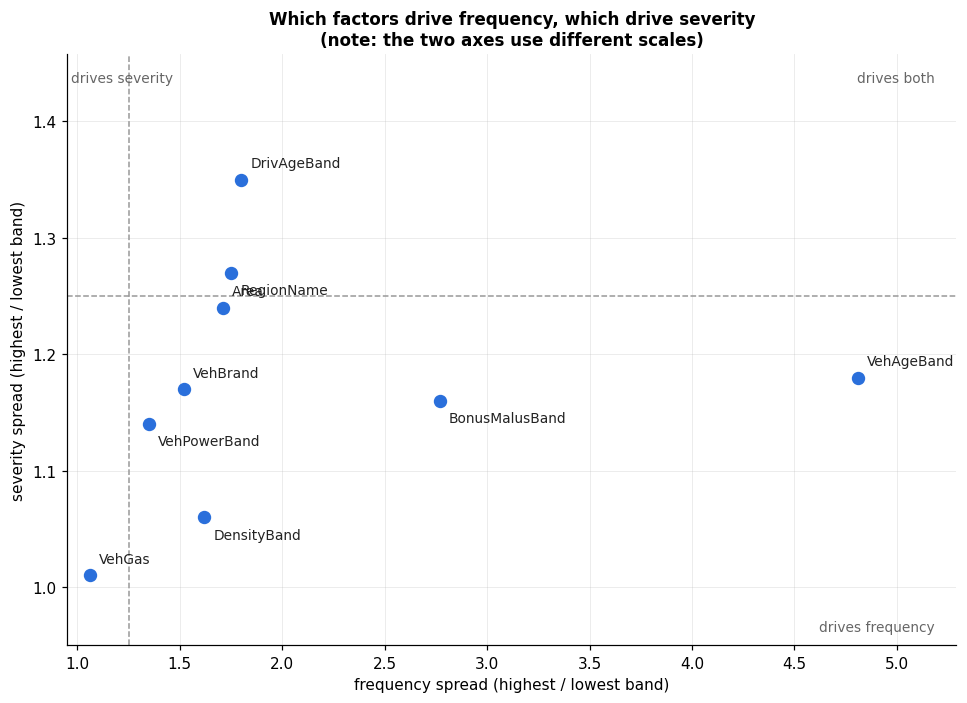

In [ ]:
SPREAD_MIN, ALPHA = 1.25, 0.01

compare = (freq_summary[["factor", "spread", "p_value"]].rename(columns={"spread": "freq_spread", "p_value": "freq_p"})
           .merge(sev_summary[["factor", "spread", "p_value", "epsilon_sq"]]
                  .rename(columns={"spread": "sev_spread", "p_value": "sev_p", "epsilon_sq": "sev_epsilon_sq"}),
                  on="factor"))
freq_material = (compare["freq_spread"] >= SPREAD_MIN) & (compare["freq_p"].astype(float) < ALPHA)
sev_material  = (compare["sev_spread"]  >= SPREAD_MIN) & (compare["sev_p"].astype(float)  < ALPHA)
compare["drives"] = np.select([freq_material & sev_material, freq_material, sev_material],
                              ["frequency and severity", "frequency only", "severity only"], "neither")
compare = compare.sort_values(["drives", "freq_spread"], ascending=[True, False])
display(compare.style.hide(axis="index").format({"freq_spread": "{:.2f}", "sev_spread": "{:.2f}", "sev_epsilon_sq": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(compare["freq_spread"], compare["sev_spread"], s=60, color=MAIN_COLOR, zorder=3)
# stagger labels of factors that sit close together
for i, (_, r) in enumerate(compare.sort_values("freq_spread").iterrows()):
    ax.annotate(r["factor"], (r["freq_spread"], r["sev_spread"]),
                xytext=(6, 8 if i % 2 == 0 else -14), textcoords="offset points", fontsize=9, color="#222")
ax.axvline(SPREAD_MIN, color="#999", ls="--", lw=1)
ax.axhline(SPREAD_MIN, color="#999", ls="--", lw=1)
xmax = compare["freq_spread"].max() * 1.1
ymax = max(compare["sev_spread"].max(), SPREAD_MIN) * 1.08       # each axis gets its own range
ax.set_xlim(0.95, xmax); ax.set_ylim(0.95, ymax)
ax.set_xlabel("frequency spread (highest / lowest band)")
ax.set_ylabel("severity spread (highest / lowest band)")
ax.set_title("Which factors drive frequency, which drive severity\n(note: the two axes use different scales)")
ax.text(xmax * 0.98, 0.96, "drives frequency", ha="right", va="bottom", fontsize=9, color="#666")
ax.text(0.97, ymax * 0.99, "drives severity", ha="left", va="top", fontsize=9, color="#666")
ax.text(xmax * 0.98, ymax * 0.99, "drives both", ha="right", va="top", fontsize=9, color="#666")
fig.tight_layout(); plt.show()

**Sensitivity check: how many factors count as material drivers at different spread thresholds?**


In [ ]:
sens = []
for thr in [1.15, 1.20, 1.25, 1.30, 1.50]:
    f = ((compare["freq_spread"] >= thr) & (compare["freq_p"].astype(float) < ALPHA))
    s = ((compare["sev_spread"]  >= thr) & (compare["sev_p"].astype(float)  < ALPHA))
    sens.append({"spread threshold": thr,
                 "frequency drivers": int(f.sum()), "severity drivers": int(s.sum()),
                 "severity drivers (names)": ", ".join(compare.loc[s, "factor"]) or "-"})
print("Sensitivity of the 'material driver' classification to the spread threshold:")
display(pd.DataFrame(sens).style.hide(axis="index"))

Sensitivity of the 'material driver' classification to the spread threshold:


spread threshold,frequency drivers,severity drivers,severity drivers (names)
1.150000,8,5,"DrivAgeBand, RegionName, VehAgeBand, BonusMalusBand, VehBrand"
1.200000,8,2,"DrivAgeBand, RegionName"
1.250000,8,2,"DrivAgeBand, RegionName"
1.300000,8,1,DrivAgeBand
1.500000,7,0,-


**Finding:**

**Frequency and severity are driven by largely different factors: many factors drive frequency, while severity is barely driven by any**.

- 8 of the 9 factors are material frequency drivers (all except fuel type), led by vehicle age (spread 4.81) and bonus-malus (spread 2.77).
- Only 2 factors are material severity drivers, driver age (spread 1.35) and region (spread 1.27), and both only just pass the 1.25 threshold; the sensitivity table shows that at a threshold of 1.30 only driver age remains. Their epsilon-squared values (0.0019 and 0.0035) are low, which is typical for individual claim costs, but confirms that severity differences between groups are weak when compared with frequency.
- Driver age and region therefore drive both, but their effect on claim cost is small; vehicle age, bonus-malus, area, density, vehicle brand and vehicle power affect frequency only, and fuel type affects neither.
- This supports modelling frequency and severity separately (Section 4): the frequency model needs most of the rating factors, while the severity model is likely to need only a few, with modest effects.

## 3.4 Do the factors overlap?



This step checks whether rating factors are linked to each other. One-way analysis looks at each factor alone, so if two factors are strongly linked, part of one factor's effect may really belong to the other.

*Example:* young drivers are usually new drivers, and new drivers start at BonusMalus 100. So the high claim frequency of young drivers and of BonusMalus 100 may partly be the **same effect seen twice**. The GLM in Section 5 separates these effects by looking at all factors together.

**Method:**
- **Cramér's V** between every pair of factors (0 = unrelated, 1 = one factor fully determines the other). Above about 0.3 is a strong link.
- **Driver age × bonus-malus heatmap** of frequency relativity: shows how the two factors combine. Red = above average, blue = below. Cells with fewer than 1,000 policy-years are left blank as too uncertain.

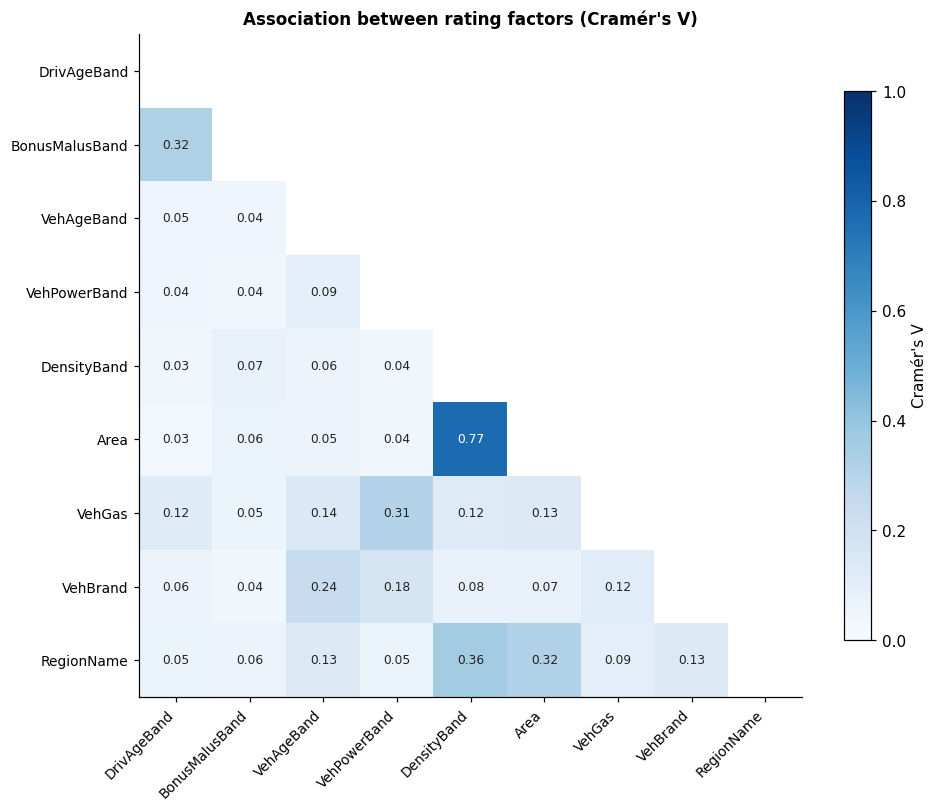

Most strongly linked factor pairs:


,,cramers_v
Area,DensityBand,0.77
RegionName,DensityBand,0.36
BonusMalusBand,DrivAgeBand,0.32
RegionName,Area,0.32
VehGas,VehPowerBand,0.31


In [ ]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2_stat = chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2_stat / (ct.values.sum() * (min(ct.shape) - 1)))

cv = pd.DataFrame(np.eye(len(factors)), index=factors, columns=factors)
for i, a in enumerate(factors):
    for b in factors[i + 1:]:
        cv.loc[a, b] = cv.loc[b, a] = cramers_v(policies[a], policies[b])

fig, ax = plt.subplots(figsize=(9, 7.5))
mask = np.triu(np.ones_like(cv, dtype=bool))
shown = cv.mask(mask)
im = ax.imshow(shown, cmap="Blues", vmin=0, vmax=1)
for i in range(len(factors)):
    for j in range(len(factors)):
        if not mask[i, j]:
            v = cv.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.5 else "#222")
ax.set_xticks(range(len(factors))); ax.set_xticklabels(factors, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(factors))); ax.set_yticklabels(factors, fontsize=9)
ax.grid(False); ax.set_title("Association between rating factors (Cramér's V)")
fig.colorbar(im, ax=ax, shrink=0.8, label="Cramér's V")
fig.tight_layout(); plt.show()

pairs = (cv.where(np.tril(np.ones_like(cv, dtype=bool), k=-1)).stack()
           .sort_values(ascending=False).head(5).round(3).rename("cramers_v").to_frame())
print("Most strongly linked factor pairs:")
display(pairs)

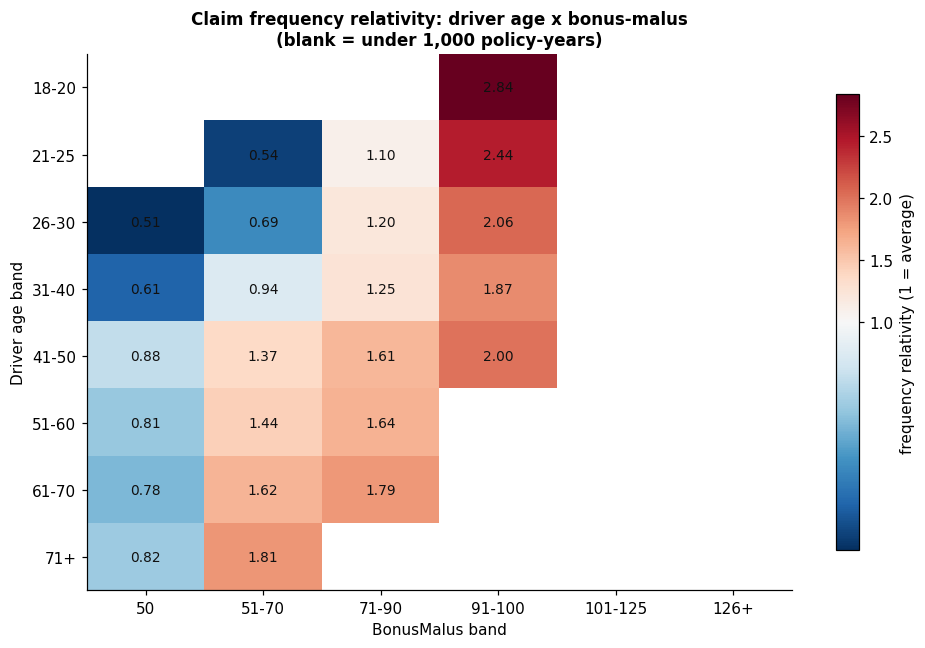

Policy-years per cell:


BonusMalusBand,50,51-70,71-90,91-100,101-125,126+
DrivAgeBand,,,,,,
18-20,163,32,635,"1,537",200,16
21-25,442,"1,170","7,557","3,429",939,106
26-30,"1,783","13,013","10,963","2,702",642,64
31-40,"37,784","30,431","12,085","2,859",669,70
41-50,"66,880","14,091","5,246","1,493",349,41
51-60,"61,977","9,220","3,339",905,224,36
61-70,"32,598","3,976","1,310",307,108,22
71+,"23,525","2,510",664,164,65,18


In [ ]:

grid = (policies.groupby(["DrivAgeBand", "BonusMalusBand"], observed=True)
                .agg(policy_years=("Exposure", "sum"), claims=("ClaimNb_model", "sum")))
grid["relativity"] = grid["claims"] / grid["policy_years"] / port_freq
rel = grid["relativity"].where(grid["policy_years"] >= 1000).unstack("BonusMalusBand")
py  = grid["policy_years"].unstack("BonusMalusBand")

fig, ax = plt.subplots(figsize=(9, 6))
vmax = np.nanmax(rel.values)
div_norm = TwoSlopeNorm(vmin=min(np.nanmin(rel.values), 0.99), vcenter=1.0, vmax=max(vmax, 1.01))
im = ax.imshow(rel.values, cmap="RdBu_r", norm=div_norm, aspect="auto")
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        v = rel.iloc[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="#111")
ax.set_xticks(range(rel.shape[1])); ax.set_xticklabels(rel.columns.astype(str))
ax.set_yticks(range(rel.shape[0])); ax.set_yticklabels(rel.index.astype(str))
ax.set_xlabel("BonusMalus band"); ax.set_ylabel("Driver age band"); ax.grid(False)
ax.set_title("Claim frequency relativity: driver age x bonus-malus\n(blank = under 1,000 policy-years)")
fig.colorbar(im, ax=ax, shrink=0.85, label="frequency relativity (1 = average)")
fig.tight_layout(); plt.show()

print("Policy-years per cell:")
display(py.style.format("{:,.0f}", na_rep="-"))

**Finding:**

**Some rating factors overlap, so part of their one-way effects is shared**.

- The most strongly linked pair is Area and DensityBand (Cramér's V 0.77): Area is a classification of how densely populated the driver's town is, so the two factors measure almost the same thing. Region is also linked to both density (0.36) and Area (0.32), because some regions are much more urban than others.
- Driver age and bonus-malus are strongly linked (Cramér's V 0.32): young drivers sit mostly in the higher bonus-malus bands, while older drivers sit at the maximum bonus. For example, drivers aged 18-20 have 1,537 policy-years in band 91-100 but only 163 at BonusMalus 50, whereas drivers aged 41-50 have 66,880 policy-years at BonusMalus 50. This is expected, since every new driver starts at 100 and needs about 13 claim-free years to reach 50.
- Fuel type and vehicle power are also linked (Cramér's V 0.31), as diesel and petrol cars tend to come in different power ranges.
- In the heatmap, claim frequency rises with bonus-malus within every age band: for drivers aged 26-30 it rises from 0.51 at BonusMalus 50 to 2.06 at 91-100, and for drivers aged 41-50 from 0.88 to 2.00. Bonus-malus therefore adds information beyond age.
- Holding bonus-malus fixed, the effect of age is much smaller than in the one-way analysis. Within band 91-100, frequency falls from 2.84 (aged 18-20) to 1.87 (aged 31-40) and then levels off (2.00 at 41-50). Among drivers at the maximum bonus (50), the youngest group even has the lowest frequency (0.51 at 26-30, against 0.78-0.88 for drivers over 40). Much of the high one-way frequency of young drivers is therefore explained by their higher bonus-malus.
- Older drivers who are not at the maximum bonus claim often: drivers aged 71+ in band 51-70 have a frequency of 1.81, against 0.82 for those at BonusMalus 50. For an experienced driver, a bonus-malus above 50 signals recent claims, which predicts more claims.
- Some combinations are implausible under the standard bonus-malus rules: 163 policy-years belong to drivers aged 18-20 at the maximum bonus (BonusMalus 50), which normally takes about 13 claim-free years to reach. These may reflect special arrangements (e.g. a young driver insured under a parent's record) or recording differences; the volumes are small, so they have little effect on the analysis.
- Because of these overlaps, the one-way relativities overstate some factors' individual effects, most notably driver age, whose effect is partly carried by bonus-malus. The GLM in Section 5 estimates each factor's effect while holding the others constant.

## Conclusion - Objective 2

- Claim **frequency** is driven mainly by vehicle age (spread 4.81) and bonus-malus (spread 2.77); 8 of the 9 factors are material frequency drivers, with fuel type being the only exception. Vehicle age's large spread comes almost entirely from brand-new vehicles (3.10x the average), a pattern that needs checking with the business before it is priced.
- Claim **severity** varies much less between groups: only 2 factors are material severity drivers, driver age (spread 1.35) and region (spread 1.27), both only just above the 1.25 threshold, and every factor's effect size is small (ε² up to 0.0091).
- Frequency and severity are therefore driven by mostly different factors: driver age and region drive both, while vehicle age, bonus-malus, area, density, vehicle brand and vehicle power affect frequency only.
- Several factors overlap (Area and density, Cramér's V 0.77; driver age and bonus-malus, Cramér's V 0.32), so one-way relativities partly double-count the same risk. Within the same bonus-malus band, the effect of driver age is much smaller than the one-way analysis suggests: much of young drivers' high frequency reflects being new drivers rather than their age.

**Business implications**
1. Most of the price differentiation should come from frequency drivers such as vehicle age and bonus-malus: these separate high-risk from low-risk customers far more than severity does.
2. Frequency and severity should be modelled separately (Sections 4-5), because the factors that matter for one are not the same as for the other; a single combined model would blur these effects.
3. Overlapping factors (e.g. Area-Density) should not both be priced from their one-way results, or customers in both groups would be charged twice for the same risk. The GLM in Section 5 resolves this.

**Limitations**
- One-way analysis looks at one factor at a time and cannot separate overlapping effects; it is a first screen, not the final answer.
- Severity is compared on claims capped at the 99th percentile, so it describes ordinary claims; very large claims are handled separately in Section 4.
- The likelihood-ratio test assumes claim counts follow a Poisson distribution; if the data is overdispersed (tested in Section 4), its p-values are somewhat overstated.

# Distribution testing and model selection

**Objective 3: Choose and justify statistically sound risk models**
- What distributions do claim counts and claim amounts follow?
- Is there overdispersion or an excess of zero-claim policies?
- Which model fits best: Poisson / negative binomial / zero-inflated Poisson for frequency; Gamma / inverse Gaussian / lognormal for severity?

**Key terms**
- **Overdispersion**: claim counts vary more between policies than a Poisson model predicts. Poisson assumes the variance equals the mean; if the variance is larger, a negative binomial model is more suitable.
- **Excess zeros**: more policies with no claims than Poisson predicts, e.g. because some customers never report small accidents. A zero-inflated model adds a separate "never claims" group.
- **AIC (Akaike Information Criterion)**: how well a model fits, with a penalty for extra parameters. Lower is better; a difference of more than about 10 is strong evidence.
- **Test-set log-likelihood**: how probable the model finds the claims in the 20% test set it has never seen. Higher (less negative) is better; this checks the model generalises rather than just fitting the training data.

## 4.1 Do claim counts vary more than Poisson allows?


This step checks the key Poisson assumption that, for customers with the same risk, the **variance of claim counts equals the mean**.

**Method:**
- Policies insured for a **full year** are grouped into cells of similar customers using three factors: **bonus-malus and driver age** (two of the strongest frequency drivers in Section 3) and **area** (location, with only 6 levels). Only a few factors with few levels are used so that each cell keeps at least 1,000 policies, enough to estimate a variance reliably. A sensitivity table below checks that the result does not depend on this choice, and the GLM in 4.6 repeats the test with all factors included.
- In each cell (with at least 1,000 policies), the mean and variance of claim counts are compared. On the chart, cells above the diagonal line have more variation than Poisson allows.
- **Dispersion index** = variance ÷ mean, averaged over cells (weighted by policies). About 1 = Poisson is fine; clearly above 1 = overdispersion.

Full-year policies: 169,349 | cells with >= 1,000 policies: 36 (covering 82.7% of full-year policies)
Weighted average dispersion index (variance / mean): 1.015
Cells with variance above the mean: 53%


,count,mean,std,min,10%,50%,90%,max
dispersion index,36.000,1.013,0.039,0.947,0.971,1.007,1.075,1.105


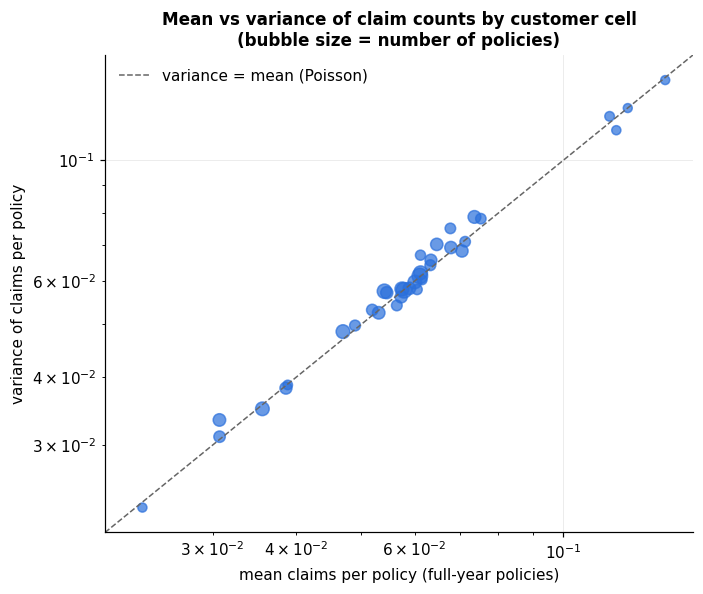

In [ ]:
full_year = policies[policies["Exposure"] == 1.0]
cell_cols = ["DrivAgeBand", "BonusMalusBand", "Area"]
cells = (full_year.groupby(cell_cols, observed=True)["ClaimNb_model"]
                  .agg(policies="size", mean="mean", variance="var")
                  .reset_index())
MIN_CELL_POLICIES = 1000
cells = cells[cells["policies"] >= MIN_CELL_POLICIES].reset_index(drop=True)
cells["dispersion"] = cells["variance"] / cells["mean"]
disp_index = np.average(cells["dispersion"], weights=cells["policies"])

print(f"Full-year policies: {len(full_year):,} | cells with >= 1,000 policies: {len(cells)} "
      f"(covering {cells['policies'].sum() / len(full_year):.1%} of full-year policies)")
print(f"Weighted average dispersion index (variance / mean): {disp_index:.3f}")
print(f"Cells with variance above the mean: {(cells['dispersion'] > 1).mean():.0%}")
display(cells["dispersion"].describe(percentiles=[0.1, 0.5, 0.9]).to_frame("dispersion index").T
        .style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(cells["mean"], cells["variance"], s=np.sqrt(cells["policies"]), color=MAIN_COLOR, alpha=0.7)
lim = [cells[["mean", "variance"]].min().min() * 0.9, cells[["mean", "variance"]].max().max() * 1.1]
ax.plot(lim, lim, color="#666", ls="--", lw=1, label="variance = mean (Poisson)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("mean claims per policy (full-year policies)"); ax.set_ylabel("variance of claims per policy")
ax.set_title("Mean vs variance of claim counts by customer cell\n(bubble size = number of policies)")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); plt.show()

**Sensitivity: does the dispersion result depend on which factors define the cells?**


In [ ]:
def dispersion_for(cols, min_pol=MIN_CELL_POLICIES):
    c = (full_year.groupby(cols, observed=True)["ClaimNb_model"]
                  .agg(policies="size", mean="mean", variance="var").reset_index())
    c = c[c["policies"] >= min_pol]
    return {"cell definition": " x ".join(cols), "cells": len(c),
            "% of full-year policies": c["policies"].sum() / len(full_year) * 100,
            "dispersion index": np.average(c["variance"] / c["mean"], weights=c["policies"])}

options = [["BonusMalusBand"],
           ["DrivAgeBand", "BonusMalusBand"],
           ["DrivAgeBand", "BonusMalusBand", "Area"],          # main choice
           ["DrivAgeBand", "BonusMalusBand", "VehAgeBand"],
           ["BonusMalusBand", "VehAgeBand", "Area"]]
disp_sens = pd.DataFrame([dispersion_for(o) for o in options])
display(disp_sens.style.hide(axis="index").format({"% of full-year policies": "{:.1f}", "dispersion index": "{:.3f}"}))

cell definition,cells,% of full-year policies,dispersion index
BonusMalusBand,4,99.4,1.019
DrivAgeBand x BonusMalusBand,17,97.1,1.013
DrivAgeBand x BonusMalusBand x Area,36,82.7,1.015
DrivAgeBand x BonusMalusBand x VehAgeBand,40,86.8,1.015
BonusMalusBand x VehAgeBand x Area,40,86.3,1.018


**Finding:**

**Claim counts are only very slightly overdispersed: within groups of similar customers, they behave almost exactly as a Poisson model expects**.

- Across 36 cells of similar full-year customers (driver age band x bonus-malus band x area, covering 169,349 policies, 82.7% of all full-year policies), the variance of claim counts averages 1.015x the mean (dispersion index = 1.015).
- The cells sit evenly around the Poisson line: 53% are slightly above it and 47% slightly below, and the dispersion index ranges only from 0.947 to 1.105 (median 1.007). Differences this small are what random variation alone would produce, rather than a systematic pattern.
- Poisson's key assumption (variance = mean) is therefore broadly reasonable once customers are grouped by these three factors. The small excess suggests some remaining differences between customers that the cells don't capture; the GLM comparison in 4.6 tests whether a negative binomial model, which allows for this, fits meaningfully better.
- The result does not depend on which factors define the cells: the dispersion index stays between 1.013 and 1.019 across five different groupings (look at sensitivity table).

## 4.2 Are there more zero-claim policies than expected?

This step compares the actual number of policies with 0, 1, 2 and 3+ claims with the number a Poisson model would predict.

**Method:**
- Each policy gets an expected claim rate from its customer cell (driver age band × bonus-malus band × area), multiplied by its exposure. So a part-year policy is expected to claim less.
- The Poisson probability of 0, 1, 2, ... claims is added up over all policies, giving the expected number of policies in each group.
- If the observed number of zero-claim policies is clearly above the expected number, there are **excess zeros**, which supports a zero-inflated model. If 2+ claim policies are also more common than expected, that points to overdispersion instead.

claims,observed policies,Poisson-expected policies,observed / expected
0,"643,953","643,524",1.001
1,"32,178","32,990",0.975
2,"1,784","1,435",1.243
3+,98,64,1.531


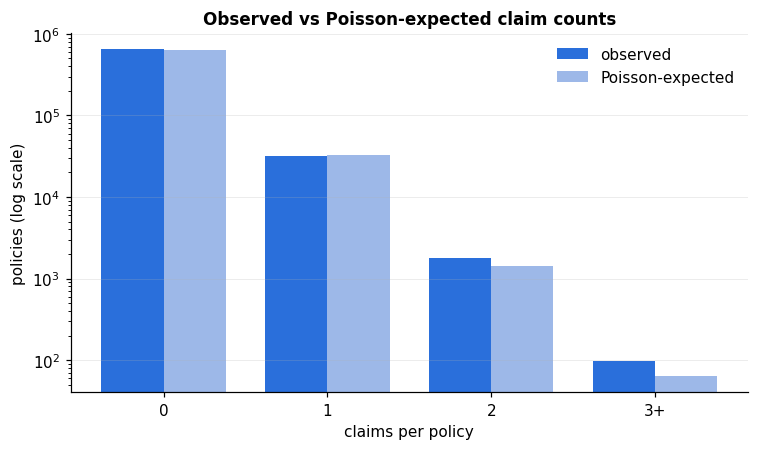

In [ ]:

cell_sums = policies.groupby(cell_cols, observed=True)[["ClaimNb_model", "Exposure"]].sum()
cell_rate = (cell_sums["ClaimNb_model"] / cell_sums["Exposure"]).rename("cell_rate")
mu_cell = policies[cell_cols].merge(cell_rate.reset_index(), on=cell_cols, how="left")["cell_rate"].to_numpy() \
          * policies["Exposure"].to_numpy()

obs = policies["ClaimNb_model"].clip(upper=3).value_counts().sort_index()
exp_counts = [poisson.pmf(0, mu_cell).sum(), poisson.pmf(1, mu_cell).sum(), poisson.pmf(2, mu_cell).sum()]
exp_counts.append(len(policies) - sum(exp_counts))

zero_check = pd.DataFrame({"claims": ["0", "1", "2", "3+"],
                           "observed policies": obs.reindex([0, 1, 2, 3], fill_value=0).to_numpy(),
                           "Poisson-expected policies": np.round(exp_counts, 0)})
zero_check["observed / expected"] = zero_check["observed policies"] / zero_check["Poisson-expected policies"]
display(zero_check.style.hide(axis="index").format({"observed policies": "{:,.0f}",
                                                   "Poisson-expected policies": "{:,.0f}",
                                                   "observed / expected": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(zero_check)); w = 0.38
ax.bar(x - w / 2, zero_check["observed policies"], w, color=MAIN_COLOR, label="observed")
ax.bar(x + w / 2, zero_check["Poisson-expected policies"], w, color="#9db8e8", label="Poisson-expected")
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(zero_check["claims"])
ax.set_xlabel("claims per policy"); ax.set_ylabel("policies (log scale)")
ax.set_title("Observed vs Poisson-expected claim counts"); ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

**Finding:**

**There is no excess of zero-claim policies; the small extra variation shows up as more multiple-claim policies, a sign of mild overdispersion**.

- Poisson expects 643,524 policies with no claim and 643,953 were observed (observed / expected = 1.001): only 429 more, a 0.07% difference. There is therefore no sign of excess zeros, so a zero-inflated model is not needed on this evidence.
- Policies with one claim are slightly fewer than expected (32,178 vs 32,990, ratio 0.975), while policies with 2 claims (1,784 vs 1,435, ratio 1.243) and 3+ claims (98 vs 64, ratio 1.531) are more common than Poisson predicts.
- This pattern (fewer single claims, more repeat claims) is the typical sign of overdispersion: some customers are riskier than their group's average and claim more than once. It points to a negative binomial model rather than a zero-inflated one.
- In absolute terms the effect is small, about 350 more 2-times-claim and 34 more 3+-times-claim policies than expected out of 678,013, which matches the mild overdispersion found in 4.1 (dispersion index 1.015). The 3+ ratio is based on very few policies (98), so it is less precise.

## 4.3 Where does the large-claim tail start?

This step chooses the **large-claim cap**. Claims above the cap are capped for severity modelling, and the cost above the cap is spread across all policies as a separate loading (Section 5). This stops a few multi-million claims from distorting the price of ordinary risks.

**Method:**
- **Fixed-amount spike:** the share of claims within ±2% of the most common amount. A continuous distribution cannot reproduce a spike like this, so it is noted before fitting distributions.
- **Mean excess plot:** for each threshold *u*, the average amount by which claims above *u* exceed it. If this keeps rising as *u* increases, the tail is heavy (Pareto-like): the bigger a claim already is, the bigger it is likely to get.
- **Candidate thresholds** (95th, 99th and 99.5th percentiles): share of claims and share of total cost above each. A good cap affects few claims but removes the volatile part of the cost.

In [ ]:
amt = claims_b["ClaimAmount"].to_numpy()

# fixed-amount spike
mode_amt = claims_b["ClaimAmount"].round(0).mode()[0]
in_spike = np.abs(amt / mode_amt - 1) <= 0.02
print(f"Most common claim amount: EUR {mode_amt:,.0f}; claims within +/-2% of it: {in_spike.sum():,} ({in_spike.mean():.1%})")

# mean excess function on a log grid of thresholds
thresholds = np.quantile(amt, np.linspace(0.50, 0.998, 60))
mean_excess = [np.mean(amt[amt > u] - u) for u in thresholds]

cand = []
for q in [0.95, 0.99, 0.995]:
    u = np.quantile(amt, q)
    above = amt > u
    cand.append({"threshold": f"{q * 100:g}th percentile", "cap (EUR)": u,
                 "claims above": int(above.sum()), "% of claims": above.mean() * 100,
                 "% of total cost above cap": (amt[above] - u).sum() / amt.sum() * 100})
cand = pd.DataFrame(cand)
display(cand.style.hide(axis="index").format({"cap (EUR)": "{:,.0f}", "claims above": "{:,}",
                                             "% of claims": "{:.2f}", "% of total cost above cap": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, mean_excess, color=MAIN_COLOR, lw=2, marker="o", markersize=3)
for _, r in cand.iterrows():
    ax.axvline(r["cap (EUR)"], color="#999", ls="--", lw=1)
    ax.text(r["cap (EUR)"], ax.get_ylim()[1] * 0.95, " " + r["threshold"].split()[0], fontsize=8, color="#555")
ax.set_xscale("log")
ax.set_xlabel("threshold u (EUR, log scale)"); ax.set_ylabel("mean excess over u (EUR)")
ax.set_title("Mean excess plot: does the tail keep getting heavier?")
fig.tight_layout(); plt.show()

LARGE_CAP = float(np.quantile(amt, 0.99))     # chosen cap - change if the plot suggests a different point
claims_b["sev_capped"] = claims_b["ClaimAmount"].clip(upper=LARGE_CAP)
print(f"Chosen large-claim cap: EUR {LARGE_CAP:,.0f} (99th percentile)")

for q in [0.50, 0.95, 0.99]:
    u = np.quantile(amt, q)
    print(f"Mean excess at the {q*100:g}th percentile (EUR {u:,.0f}): EUR {np.mean(amt[amt > u] - u):,.0f}")

NameError: name 'claims_b' is not defined

**Finding:**

**The claim cost tail is heavy, so claims are capped at EUR 16,451 (99th percentile) for severity modelling**.

- 19.0% of claims (5,032) sit within ±2% of a single amount, EUR 1,204: a fixed-amount settlement spike that no smooth distribution can reproduce.
- The mean excess keeps rising as the threshold increases: for claims above the median (EUR 1,172), the average excess is EUR 3,049; for claims above the 99th percentile (EUR 16,451), it is EUR 69,488. The curve turns sharply upward from roughly EUR 10,000-16,000: the bigger a claim already is, the bigger it tends to get, a sign of a heavy, Pareto-like tail. The 99th percentile sits at this turning point.
- Capping at the 99th percentile affects only 1.00% of claims (265) but moves 30.7% of total claim cost (the part of those claims above EUR 16,451) into a separate large-claim loading, added back in Section 5. A lower cap (95th percentile) would move 41.6% of cost out of the model, while a higher cap (99.5th percentile) would still leave very large claims of up to EUR 34,377 in the modelling data.

## 4.4 Which distribution fits claim amounts?

This step fits four candidate distributions to claim amounts below the cap and compares how well each describes the data.

**Method:**
- **Candidates:** Gamma, lognormal, Weibull and inverse Gaussian, all common for insurance claim sizes (positive, right-skewed).
- **Maximum likelihood** finds each distribution's parameters that make the observed claims most probable.
- **QQ plots** compare the actual claim amounts with the amounts each fitted distribution predicts at the same percentiles. Points on the diagonal = good fit; points bending away in the upper right = the distribution underestimates large claims.
- **AIC** ranks the fits (lower = better). The fit is repeated **without the fixed-amount spike** to check that the ranking does not depend on it.
- Formal goodness-of-fit tests (Kolmogorov-Smirnov, Anderson-Darling) are not used to choose: with over 20,000 claims they reject every distribution over tiny differences, so they cannot separate the candidates.
- This step looks at all claims together; 4.7 repeats the comparison inside GLMs with rating factors, which is what decides.

In [ ]:

below = amt[amt <= LARGE_CAP]
below_no_spike = below[np.abs(below / mode_amt - 1) > 0.02]

dists = {"Gamma": stats.gamma, "Lognormal": stats.lognorm, "Weibull": stats.weibull_min,
         "Inverse Gaussian": stats.invgauss}
fits, rows = {}, []
for name, dist in dists.items():
    params = dist.fit(below, floc=0)
    fits[name] = params
    ll = dist.logpdf(below, *params).sum()
    params_ns = dist.fit(below_no_spike, floc=0)
    ll_ns = dist.logpdf(below_no_spike, *params_ns).sum()
    rows.append({"distribution": name, "AIC (all claims below cap)": 2 * 2 - 2 * ll,
                 "AIC (excluding fixed-amount spike)": 2 * 2 - 2 * ll_ns})
sev_fit = pd.DataFrame(rows)
for c in ["AIC (all claims below cap)", "AIC (excluding fixed-amount spike)"]:
    sev_fit[c.replace("AIC", "rank")] = sev_fit[c].rank().astype(int)
display(sev_fit.sort_values("AIC (all claims below cap)").style.hide(axis="index")
        .format({"AIC (all claims below cap)": "{:,.0f}", "AIC (excluding fixed-amount spike)": "{:,.0f}"}))

# QQ plots on log scale (200 percentiles)
probs = np.linspace(0.005, 0.995, 200)
emp_q = np.quantile(below, probs)
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, dist) in zip(axes.flat, dists.items()):
    th_q = dist.ppf(probs, *fits[name])
    ax.scatter(th_q, emp_q, s=10, color=MAIN_COLOR)
    lo, hi = min(th_q.min(), emp_q.min()), max(th_q.max(), emp_q.max())
    ax.plot([lo, hi], [lo, hi], color="#666", ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(name); ax.set_xlabel("fitted distribution quantile (EUR)"); ax.set_ylabel("actual quantile (EUR)")
fig.suptitle("QQ plots: actual vs fitted claim amounts (claims below the cap)", fontweight="bold")
fig.tight_layout(); plt.show()

**Finding:**

**Gamma fits claim amounts best, closely followed by Weibull, but no distribution fits the whole shape well**.

- By AIC, the ranking is Gamma (431,565) < Weibull (432,064) < lognormal (434,007) < inverse Gaussian (448,062). Gamma beats Weibull by 499 points and lognormal by 2,442 points, far above the 10-point threshold for strong evidence; inverse Gaussian fits clearly worst (16,497 points behind Gamma).
- The ranking is unchanged when the 5,032 fixed-amount claims around EUR 1,204 are excluded, so the choice does not depend on how each distribution handles the spike. Without the spike, Gamma (350,716) and Weibull (350,718) are virtually tied (a difference of 2 points).
- All four QQ plots show a flat stretch at about EUR 1,100-1,250: the fixed-amount settlements.
- Gamma and Weibull follow the actual claim amounts closely in the middle of the range, but their highest points rise above the diagonal: they slightly underestimate the largest claims below the cap. Lognormal's highest points fall below the diagonal, so it expects larger claims than the data contains (partly because claims are capped at EUR 16,451). Inverse Gaussian shows the largest departures throughout.
- This comparison uses all claims together; the GLM comparison in 4.7 tests Gamma, inverse Gaussian and lognormal with rating factors included, which is decisive.

## 4.5 How does the spread of claim costs grow with their size?

**What this step does:** tests a second, more direct way to choose between Gamma and inverse Gaussian: how the **variance** of claim costs grows with the **mean**.

**Method:** claims are grouped into segments (driver age band × region) with at least 100 claims each. For each segment, the mean and variance of capped claim costs are calculated, and the slope of log(variance) against log(mean) is estimated.

In [ ]:
seg = (claims_b.groupby(["DrivAgeBand", "RegionName"], observed=True)["sev_capped"]
               .agg(claims="size", mean="mean", variance="var").reset_index())
MIN_SEG_CLAIMS = 100
seg = seg[seg["claims"] >= MIN_SEG_CLAIMS].reset_index(drop=True)

lx, ly, w = np.log(seg["mean"]), np.log(seg["variance"]), np.sqrt(seg["claims"])
(slope, intercept), cov = np.polyfit(lx, ly, 1, w=w, cov=True)
slope_se = np.sqrt(cov[0, 0])
# robustness: drop the segment with the lowest mean
keep = seg["mean"] != seg["mean"].min()
slope_drop = np.polyfit(lx[keep], ly[keep], 1, w=w[keep])[0]

print(f"Segments with >= {MIN_SEG_CLAIMS} claims: {len(seg)} | segment mean claim cost ranges "
      f"from EUR {seg['mean'].min():,.0f} to EUR {seg['mean'].max():,.0f}")
print(f"Estimated slope: {slope:.2f} (95% CI {slope - 1.96 * slope_se:.2f} to {slope + 1.96 * slope_se:.2f})")
print(f"Slope without the lowest-mean segment: {slope_drop:.2f}")

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.scatter(seg["mean"], seg["variance"], s=w * 2, color=MAIN_COLOR, alpha=0.7)
xs = np.linspace(seg["mean"].min(), seg["mean"].max(), 50)
ax.plot(xs, np.exp(intercept) * xs ** slope, color="#222", lw=1.8, label=f"fitted slope = {slope:.2f}")
x0, y0 = np.exp(np.average(lx, weights=w)), np.exp(np.average(ly, weights=w))   # anchor reference lines at the centre
for p, ls, lab in [(2, "--", "slope 2 (Gamma)"), (3, ":", "slope 3 (inverse Gaussian)")]:
    ax.plot(xs, y0 * (xs / x0) ** p, color="#888", ls=ls, lw=1.3, label=lab)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("mean claim cost in segment (EUR, capped)"); ax.set_ylabel("variance of claim cost")
ax.set_title("Mean-variance relationship of claim costs\n(segments = driver age band x region)")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

**Finding:**

**The variance of claim cost grows with the mean to the power 2.90, significantly faster than a Gamma model assumes and consistent with inverse Gaussian**.

- Across 59 segments (driver age band x region, each with at least 100 claims), the estimated slope of log(variance) on log(mean) is 2.90, with a 95% confidence interval of 2.50 to 3.29. The interval excludes 2 (Gamma) and includes 3 (inverse Gaussian): in groups with a higher average claim cost, the spread of claim costs grows faster than Gamma allows.
- The chart shows the same: the fitted line almost overlaps the slope-3 (inverse Gaussian) reference line, while the slope-2 (Gamma) line is too flat. It overstates the variance of the cheapest segments and understates that of the most expensive ones.
- The result is not driven by a single point: without the segment with the lowest average cost, the slope is 2.76, still well above 2. The estimate does rest on a fairly narrow range of segment averages (EUR 1,164 to EUR 2,132), so it is less precise than it would be over a wider range.
- This points in the opposite direction from 4.4, where Gamma fitted the overall shape of claim costs best and inverse Gaussian worst. The two checks measure different things: 4.4 looks at the shape of all claims pooled together, while 4.5 looks at how the variance grows with the mean, which is what a GLM's choice of family assumes. The GLM comparison in 4.7, with rating factors and test-set validation, decides between them.

## 4.6 Best frequency model: Poisson vs negative binomial vs zero-inflated Poisson

**What this step does:** fits the three candidate frequency models on the **training set**, with the rating factors included, and compares them.

**Method:**
- **Rating factors:** driver age, bonus-malus, vehicle age, vehicle power, vehicle brand, fuel type, area and region (bands from Section 1). Density is left out because it overlaps almost completely with area (Cramér's V 0.77, Section 3.4). Every model uses the same factors, so only the distribution differs. Final factor selection happens in Section 5.
- **Offset log(exposure):** tells each model how long each policy was insured, so a 3-month policy is expected to have a quarter of a full-year policy's claims.
- **Models:** Poisson GLM; negative binomial (NB2, variance = mean + α × mean², where α > 0 measures overdispersion); zero-inflated Poisson (an extra probability π of being a "never claims" customer).
- **Tests:**
    - **Pearson dispersion** (Poisson model): Pearson χ² ÷ degrees of freedom; about 1 = no overdispersion.
    - **Cameron-Trivedi test**: a regression test of whether the variance grows faster than the mean; a significant positive coefficient = overdispersion.
    - **Vuong test** (zero-inflated vs plain Poisson): a positive, significant statistic favours the zero-inflated model.
    - **AIC / BIC** on the training set and **log-likelihood** and **Poisson deviance** on the test set.
    - **Observed vs predicted** number of test policies with 0, 1, 2, 3+ claims.

In [ ]:

freq_factors = ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "VehPowerBand",
                "VehBrand", "VehGas", "Area", "RegionName"]
freq_formula = "ClaimNb_model ~ " + " + ".join(f"C({f})" for f in freq_factors)

train = policies[policies["split"] == "train"].reset_index(drop=True)
test  = policies[policies["split"] == "test"].reset_index(drop=True)
y_tr, X_tr = dmatrices(freq_formula, train, return_type="dataframe")
X_te = build_design_matrices([X_tr.design_info], test, return_type="dataframe")[0]
y_tr, y_te = y_tr.iloc[:, 0].to_numpy(), test["ClaimNb_model"].to_numpy()
off_tr, off_te = np.log(train["Exposure"].to_numpy()), np.log(test["Exposure"].to_numpy())
print(f"Training policies: {len(train):,} | test policies: {len(test):,} | model parameters: {X_tr.shape[1]}")

# 1) Poisson GLM
pois = sm.GLM(y_tr, X_tr, family=sm.families.Poisson(), offset=off_tr).fit()
mu_tr_p = pois.fittedvalues.to_numpy()
pearson_disp = pois.pearson_chi2 / pois.df_resid

# Cameron-Trivedi overdispersion test: regress ((y - mu)^2 - y) / mu on mu (no constant)
z = ((y_tr - mu_tr_p) ** 2 - y_tr) / mu_tr_p
ct_alpha = np.sum(z * mu_tr_p) / np.sum(mu_tr_p ** 2)
ct_resid = z - ct_alpha * mu_tr_p
ct_se = np.sqrt(np.sum(ct_resid ** 2) / (len(z) - 1) / np.sum(mu_tr_p ** 2))
ct_t = ct_alpha / ct_se

# 2) Negative binomial (NB2), started from the Poisson estimates
nb = sm.NegativeBinomial(y_tr, X_tr, loglike_method="nb2", exposure=train["Exposure"].to_numpy()) \
       .fit(start_params=np.append(pois.params.to_numpy(), 0.5), maxiter=200, disp=0)
nb_alpha = nb.params.iloc[-1]

# 3) Zero-inflated Poisson (constant inflation probability), started from the Poisson estimates
zip_model = sm.ZeroInflatedPoisson(y_tr, X_tr, exposure=train["Exposure"].to_numpy(), inflation="logit")
zip_res = zip_model.fit(start_params=np.append(-2.0, pois.params.to_numpy()), method="bfgs", maxiter=500, disp=0)
zip_pi = 1 / (1 + np.exp(-zip_res.params.iloc[0]))

# Vuong test: zero-inflated vs plain Poisson (per-policy log-likelihood differences, training set)
ll_p_obs = poisson.logpmf(y_tr, mu_tr_p)
ll_zip_obs = zip_model.loglikeobs(zip_res.params.to_numpy())
m = ll_zip_obs - ll_p_obs
vuong = np.sqrt(len(m)) * m.mean() / m.std(ddof=1)

print(f"Pearson dispersion (Poisson): {pearson_disp:.3f}")
print(f"Cameron-Trivedi test: alpha = {ct_alpha:.3f}, t = {ct_t:.1f}, one-sided p = {stats.norm.sf(ct_t):.1e}")
print(f"Negative binomial alpha: {nb_alpha:.3f}")
print(f"Zero-inflated Poisson: estimated share of 'never claims' customers = {zip_pi:.1%}")
print(f"Vuong statistic (ZIP vs Poisson): {vuong:.2f}, one-sided p = {stats.norm.sf(vuong):.1e}")

In [ ]:
# test-set evaluation
exp_te = test["Exposure"].to_numpy()
mu_te = {"Poisson": pois.predict(X_te, offset=off_te).to_numpy(),
         "Negative binomial": np.asarray(nb.predict(X_te, exposure=exp_te)),
         "Zero-inflated Poisson": np.asarray(zip_res.predict(X_te, exposure=exp_te))}

def test_loglik(name):
    mu = mu_te[name]
    if name == "Poisson":
        return poisson.logpmf(y_te, mu).sum()
    if name == "Negative binomial":
        n = 1 / nb_alpha
        return nbinom.logpmf(y_te, n, n / (n + mu)).sum()
    lam = mu / (1 - zip_pi)                                    # mean of the Poisson part
    return np.where(y_te == 0, np.log(zip_pi + (1 - zip_pi) * np.exp(-lam)),
                    np.log(1 - zip_pi) + poisson.logpmf(y_te, lam)).sum()

freq_compare = pd.DataFrame({
    "model": list(mu_te),
    "parameters": [len(pois.params), len(nb.params), len(zip_res.params)],
    "AIC (train)": [pois.aic, nb.aic, zip_res.aic],
    "BIC (train)": [pois.bic_llf, nb.bic, zip_res.bic],
    "log-likelihood (test)": [test_loglik(k) for k in mu_te],
    "Poisson deviance (test, mean)": [mean_poisson_deviance(y_te, mu_te[k]) for k in mu_te],
})
freq_compare["AIC vs best"] = freq_compare["AIC (train)"] - freq_compare["AIC (train)"].min()
display(freq_compare.style.hide(axis="index").format({"AIC (train)": "{:,.1f}", "BIC (train)": "{:,.1f}",
        "log-likelihood (test)": "{:,.1f}", "Poisson deviance (test, mean)": "{:.5f}", "AIC vs best": "{:,.1f}"}))

# observed vs predicted number of test policies with 0, 1, 2, 3+ claims
def count_probs(name, k):
    mu = mu_te[name]
    if name == "Poisson":
        return poisson.pmf(k, mu)
    if name == "Negative binomial":
        n = 1 / nb_alpha
        return nbinom.pmf(k, n, n / (n + mu))
    lam = mu / (1 - zip_pi)
    return (zip_pi if k == 0 else 0) + (1 - zip_pi) * poisson.pmf(k, lam)

cnt = {"claims": ["0", "1", "2", "3+"],
       "observed": [np.sum(y_te == 0), np.sum(y_te == 1), np.sum(y_te == 2), np.sum(y_te >= 3)]}
for name in mu_te:
    p = [count_probs(name, k).sum() for k in range(3)]
    cnt[name] = p + [len(y_te) - sum(p)]
count_fit = pd.DataFrame(cnt)
print("Test set: observed vs predicted number of policies by claim count")
display(count_fit.style.hide(axis="index").format({c: "{:,.0f}" for c in count_fit.columns if c != "claims"}))

**Finding:**

**The negative binomial fits best on every likelihood measure, but all three models predict average claim frequency equally well**.

- The negative binomial has the lowest AIC (224,981.2) and BIC (225,687.0) and the highest test-set log-likelihood (-28,075.8). The zero-inflated Poisson is second (AIC 72.9 points higher, test log-likelihood 13.2 lower) and Poisson is last (AIC 452.6 points higher, test log-likelihood 68.6 lower); all gaps are well above the 10-point threshold for strong evidence.
- However, all three models predict average claim counts on the test set almost identically (mean Poisson deviance ~0.31), so the choice of distribution has very little effect on predicted frequencies, and therefore on prices; it mainly affects how the variation around those predictions is described.
- With rating factors included, the Poisson model's Pearson dispersion is 2.299, far above the 1.015 found for full-year policies in 4.1. This suggests the extra variation likely comes mainly from part-year policies that had a claim (a short policy with a claim produces a very large residual), consistent with policies being started or changed around a claim. The Cameron-Trivedi test, which measures overdispersion differently, is not significant at the 5% level (alpha = 0.514, p = 0.067). The negative binomial estimates alpha = 0.790.
- The zero-inflated model estimates that 38.5% of customers never claim and the Vuong test favours it over Poisson (8.70, p < 0.001), but 4.2 found no excess of zero-claim policies (observed / expected = 1.001), so this improvement reflects extra variation rather than a genuine "never claims" group.
- On the test set, Poisson slightly under-predicts repeat claims (306 vs 361 observed with 2 claims, 18 vs 24 with 3+), while the negative binomial over-predicts them by more (460 and 59) and under-predicts single claims (6,199 vs 6,427). The negative binomial's alpha is therefore pulled up by a small number of unusual policies, and it overstates the variation for typical customers.
- **Choice:** the negative binomial is selected as the frequency model, because it is best on AIC, BIC and test-set log-likelihood. As all three models give practically the same average predictions, Section 5 will compare its relativities with the Poisson model's to confirm that the choice does not change prices.

## 4.7 Best severity model: Gamma vs inverse Gaussian vs lognormal



**What this step does:** fits the three candidate severity models on the training claims, with rating factors, and compares them.

**Method:**
- **Target:** claim cost capped at the large-claim cap from 4.3. **Rating factors:** driver age and region, the two material severity drivers from Section 3; other factors are tested in Section 5.
- **Models:** Gamma GLM and inverse Gaussian GLM, both with a log link (so rating factors multiply the average cost), and a lognormal model (linear regression on log cost).
- **Comparison:**
    - **AIC** and **test-set log-likelihood**, calculated on the same scale (EUR) for all three so they are directly comparable.
    - **Predicted vs actual average cost** on the test set. The lognormal model predicts on the log scale, and turning that back into euros needs a correction (× e^(σ²/2)); without it, it would underestimate the average cost. Both versions are shown.
    - **Deviance residual QQ plot:** if the chosen distribution is right, the deviance residuals should roughly follow a normal distribution (points on the line).

In [ ]:
sev_formula = "sev_capped ~ C(DrivAgeBand) + C(RegionName)"
c_tr = claims_b[claims_b["split"] == "train"].reset_index(drop=True)
c_te = claims_b[claims_b["split"] == "test"].reset_index(drop=True)
ys_tr, Xs_tr = dmatrices(sev_formula, c_tr, return_type="dataframe")
Xs_te = build_design_matrices([Xs_tr.design_info], c_te, return_type="dataframe")[0]
ys_tr, ys_te = ys_tr.iloc[:, 0].to_numpy(), c_te["sev_capped"].to_numpy()
k = Xs_tr.shape[1] + 1                                  # coefficients + dispersion / sigma
print(f"Training claims: {len(ys_tr):,} | test claims: {len(ys_te):,} | parameters per model: {k}")

log_link = sm.families.links.Log()
gam = sm.GLM(ys_tr, Xs_tr, family=sm.families.Gamma(link=log_link)).fit()
ig  = sm.GLM(ys_tr, Xs_tr, family=sm.families.InverseGaussian(link=log_link)).fit(maxiter=200)
lno = sm.OLS(np.log(ys_tr), Xs_tr).fit()
sigma2 = lno.mse_resid

def gamma_ll(y, mu, phi):  return stats.gamma.logpdf(y, 1 / phi, scale=mu * phi)
def ig_ll(y, mu, phi):     return stats.invgauss.logpdf(y, mu * phi, scale=1 / phi)
def lnorm_ll(y, mlog, s2): return stats.norm.logpdf(np.log(y), mlog, np.sqrt(s2)) - np.log(y)

mu_g_te  = gam.predict(Xs_te).to_numpy()
mu_ig_te = ig.predict(Xs_te).to_numpy()
mlog_te  = lno.predict(Xs_te).to_numpy()

sev_compare = pd.DataFrame({
    "model": ["Gamma GLM", "Inverse Gaussian GLM", "Lognormal"],
    "AIC (train)": [2 * k - 2 * gamma_ll(ys_tr, gam.fittedvalues.to_numpy(), gam.scale).sum(),
                    2 * k - 2 * ig_ll(ys_tr, ig.fittedvalues.to_numpy(), ig.scale).sum(),
                    2 * k - 2 * lnorm_ll(ys_tr, lno.fittedvalues.to_numpy(), sigma2).sum()],
    "log-likelihood (test)": [gamma_ll(ys_te, mu_g_te, gam.scale).sum(),
                              ig_ll(ys_te, mu_ig_te, ig.scale).sum(),
                              lnorm_ll(ys_te, mlog_te, sigma2).sum()],
    "predicted avg cost (test)": [mu_g_te.mean(), mu_ig_te.mean(), np.exp(mlog_te + sigma2 / 2).mean()],
})
sev_compare["actual avg cost (test)"] = ys_te.mean()
sev_compare["predicted / actual"] = sev_compare["predicted avg cost (test)"] / ys_te.mean()
sev_compare["AIC vs best"] = sev_compare["AIC (train)"] - sev_compare["AIC (train)"].min()
display(sev_compare.style.hide(axis="index").format({"AIC (train)": "{:,.1f}", "log-likelihood (test)": "{:,.1f}",
        "predicted avg cost (test)": "{:,.0f}", "actual avg cost (test)": "{:,.0f}",
        "predicted / actual": "{:.3f}", "AIC vs best": "{:,.1f}"}))
print(f"Lognormal WITHOUT the back-transformation correction would predict an average of "
      f"EUR {np.exp(mlog_te).mean():,.0f} ({np.exp(mlog_te).mean() / ys_te.mean():.0%} of actual)")

# deviance residual QQ plots (Gamma vs inverse Gaussian)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, res) in zip(axes, [("Gamma GLM", gam), ("Inverse Gaussian GLM", ig)]):
    r = np.sort(res.resid_deviance.to_numpy() / np.sqrt(res.scale))
    q = stats.norm.ppf((np.arange(1, len(r) + 1) - 0.5) / len(r))
    idx = np.linspace(0, len(r) - 1, 400).astype(int)
    ax.scatter(q[idx], r[idx], s=10, color=MAIN_COLOR)
    ax.plot([-4, 4], [-4, 4], color="#666", ls="--", lw=1)
    ax.set_title(name); ax.set_xlabel("normal quantile"); ax.set_ylabel("standardised deviance residual")
fig.suptitle("Deviance residual QQ plots (points on the line = distribution fits)", fontweight="bold")
fig.tight_layout(); plt.show()

**Finding:**

**The Gamma GLM is the best severity model: the lognormal fits the shape of claim costs better but overstates the average cost by 8.9%**.

- Fitted on 21,132 training claims and tested on 5,312 claims, each model with 30 parameters (driver age and region).
- On AIC, the lognormal model is best (352,844.8), with Gamma 6,787.4 points behind and inverse Gaussian 15,099.8 points behind. The lognormal also has the highest test-set log-likelihood (-44,326.4, vs -45,203.8 for Gamma and -46,121.0 for inverse Gaussian), so it describes the shape of individual claim costs best.
- However, the lognormal predicts an average test-set claim cost of EUR 1,709 against an actual EUR 1,569 (ratio 1.089), so it would overprice claim costs by about 8.9%. Without the back-transformation correction it would predict only EUR 937 (60% of actual), underpricing every policy. Gamma and inverse Gaussian both predict EUR 1,573 (ratios 1.002 and 1.003).
- Because pricing depends on the average cost, accuracy of the average was set as the first selection criterion. Gamma is therefore chosen: it predicts the average almost exactly and beats inverse Gaussian on AIC (by 8,312.4 points) and on test-set log-likelihood.
- The deviance residual QQ plots support Gamma over inverse Gaussian. Gamma's residuals stay roughly within -3 to +3; they flatten in the middle (the fixed-amount settlements, which all get similar residuals) and bend away from the line in both tails. Inverse Gaussian's residuals fall well below the line on the left, with one residual near -28, so it treats small claims as far more surprising than they are.
- This resolves the conflict between 4.4 and 4.5. The mean-variance slope of 2.90 pointed towards inverse Gaussian, but with rating factors included, inverse Gaussian is clearly the weakest model, consistent with the shape-based fit in 4.4, where Gamma beat inverse Gaussian.

## 4.8 Model selection summary

In [ ]:
# Selection rules (set before seeing results):
#   Frequency: lowest AIC (all three models predict the average equally well - see 4.6)
#   Severity : must predict the average test-set cost within 2% of actual; then lowest AIC

# Frequency choice
best_freq = freq_compare.sort_values("AIC (train)").iloc[0]
freq_best_ll = freq_compare.loc[freq_compare["log-likelihood (test)"].idxmax(), "model"]

# Severity choice
sev_compare["average within 2%"] = (sev_compare["predicted / actual"] - 1).abs() <= 0.02
sev_ok = sev_compare[sev_compare["average within 2%"]]
best_sev = sev_ok.sort_values("AIC (train)").iloc[0]
sev_lowest_aic = sev_compare.loc[sev_compare["AIC (train)"].idxmin(), "model"]
sev_best_ll = sev_compare.loc[sev_compare["log-likelihood (test)"].idxmax(), "model"]
lowest_aic_ratio = sev_compare.loc[sev_compare["model"] == sev_lowest_aic, "predicted / actual"].iloc[0]

# Severity rule table: shows why each candidate was kept or ruled out
display(sev_compare[["model", "AIC (train)", "log-likelihood (test)", "predicted / actual", "average within 2%"]]
        .style.hide(axis="index")
        .format({"AIC (train)": "{:,.1f}", "log-likelihood (test)": "{:,.1f}", "predicted / actual": "{:.3f}"}))

# Large-claim share for the summary
pct_above_cap = cand.loc[cand["threshold"].str.startswith("99th"), "% of total cost above cap"].iloc[0]

selection = pd.DataFrame([
    {"target": "Claim frequency",
     "chosen model": best_freq["model"],
     "lowest AIC": "yes",
     "best test log-likelihood": "yes" if best_freq["model"] == freq_best_ll else f"no ({freq_best_ll})",
     "key evidence": f"Pearson dispersion {pearson_disp:.3f}; NB alpha {nb_alpha:.3f}; Vuong {vuong:.2f}"},
    {"target": "Claim severity (capped)",
     "chosen model": best_sev["model"],
     "lowest AIC": "yes" if best_sev["model"] == sev_lowest_aic
                   else f"no ({sev_lowest_aic}, but predicted/actual avg cost {lowest_aic_ratio:.3f})",
     "best test log-likelihood": "yes" if best_sev["model"] == sev_best_ll else f"no ({sev_best_ll})",
     "key evidence": f"predicted/actual avg cost {best_sev['predicted / actual']:.3f}; "
                     f"mean-variance slope {slope:.2f}"},
    {"target": "Large claims",
     "chosen model": f"Cap at EUR {LARGE_CAP:,.0f} + loading",
     "lowest AIC": "-",
     "best test log-likelihood": "-",
     "key evidence": f"claims above the cap = {pct_above_cap:.1f}% of total cost"},
])
display(selection.style.hide(axis="index"))

**Conclusion - Objective 3:**
- **Claim counts show mild overdispersion.** Full-year policies are very close to Poisson (dispersion index 1.015 across 36 cells covering 169,349 full-year policies, range 0.947 to 1.105), but with rating factors included, Poisson still under-predicts repeat claims on the test set (306 vs 361 policies with 2 claims; 18 vs 24 with 3+) and its Pearson dispersion is 2.299. The Cameron-Trivedi test is borderline (p = 0.067), so the extra spread is small and appears concentrated in part-year policies rather than across the whole book.
- **There is no excess of zero-claim policies.** Observed zero-claim policies are 1.001x the Poisson-expected number (4.2). The Vuong test favours the zero-inflated model over Poisson (8.70), but its implied 38.5% "never claim" group reflects extra spread rather than genuine extra zeros, and the negative binomial beats it on AIC and test-set log-likelihood.
- **The negative binomial is chosen for frequency.** It has the lowest AIC (224,981.2; Poisson 452.6 points higher, zero-inflated Poisson 72.9 higher) and the best test-set log-likelihood (-28,075.8). All three models predict average claim counts almost identically (mean Poisson deviance 0.31281 to 0.31287), so the choice has little effect on predicted frequencies.
- **Claim costs are heavily right-skewed, with a fixed-amount spike.** 19.0% of costed claims fall within ±2% of EUR 1,204. Claims are capped at EUR 16,451 (99th percentile, 265 claims), where the mean excess plot starts rising sharply; 30.7% of total claim cost lies above the cap and will be priced through a separate large-claim loading.
- **No continuous distribution fits claim costs perfectly** because of the spike. Among the simple fits, Gamma had the lowest AIC (431,565), ahead of Weibull, lognormal and inverse Gaussian, with the same ranking when the spike was excluded (4.4). The mean-variance slope of 2.90 (95% CI 2.50 to 3.29) leaned towards inverse Gaussian (4.5), so the rating-factor models in 4.7 settled the choice.
- **The Gamma GLM is chosen for severity.** It predicts the average test-set claim cost almost exactly (EUR 1,573 vs actual EUR 1,569, ratio 1.002) and beats inverse Gaussian on AIC (359,632.3 vs 367,944.7), test-set log-likelihood (-45,203.8 vs -46,121.0) and the residual QQ plot. The lognormal model fits the shape of individual claims best (lowest AIC, 352,844.8) but overstates the average cost (EUR 1,709, ratio 1.089).

**Business implications**
1. The pricing model will use a **negative binomial GLM for claim frequency** and a **Gamma GLM for capped claim severity**, each chosen on statistical evidence rather than by default, which makes the technical premium defensible to reviewers and regulators.
2. Because all three frequency models predict the same averages, prices are not sensitive to the frequency distribution choice. Section 5 will confirm this by comparing negative binomial and Poisson relativities.
3. A model must be judged on whether it reproduces the average cost, not only on statistical fit: the best-fitting severity model (lognormal) would have overpriced claim costs by about 8.9% after correction.
4. Large claims are priced separately through a loading, so a single very large claim does not distort the price of a whole customer group. As 30.7% of claim cost lies above EUR 16,451, the insurer can also consider reinsurance for this tail.

**Limitations**
- The fixed-amount settlement spike cannot be reproduced by any continuous distribution, so every severity model fits the middle of the distribution imperfectly (QQ plots in 4.4 and 4.7).
- The large-claim cap (99th percentile) is a judgement supported by the mean excess plot; a different cap would shift cost between the severity model and the large-claim loading.
- The frequency model assumes claims are proportional to time insured (the exposure offset). The high Pearson dispersion suggests short policies with claims behave differently, and the negative binomial's alpha (0.790) likely overstates the spread for typical full-year policies.
- Weibull was excluded from the severity models because it is not a GLM family and is harder to use with rating factors, even though it ranked second in 4.4.
- The model comparison uses a fixed set of rating factors (the material drivers from Section 3); the final factor selection in Section 5 could slightly change how the models compare.
- The Vuong test is approximate when the models are nested, so it was used alongside AIC and test-set results rather than on its own.

# Risk-based technical premium and GBM challenger

**Objective 4:** Build a risk-based technical premium.

**Key questions:**
- What is the expected claims cost (pure premium) for each policy?
- Does a GBM challenger find patterns the GLM misses?

**Terms used:**
- **Pure premium (EUR per policy-year):** expected claims per year × (expected capped cost per claim + large-claim loading per claim)
- **Relativity:** how much more (or less) a group costs than the reference group. For example, 1.30 = 30% more. The reference level is the one with the most policy-years.
- **Actual ÷ expected (A/E):** actual claims divided by predicted claims. 1.00 = the model predicts the total exactly.
- **Lift chart:** test policies sorted into 10 groups of equal policy-years, from lowest to highest predicted premium. A good model shows actual cost rising steeply from group 1 to group 10.
- **Gini:** a single number for how well the model ranks risk. 0 = no better than random; higher = better ranking.
- **Double-lift chart:** sorts policies by how much the GBM and GLM disagree, then checks which model's prediction is closer to actual cost.

## 5.1 Frequency model - factor selection

This step starts from the 4.6 negative binomial model (eight factors) and tests whether each factor is really needed, whether area or density band works better for location, and whether the bonus-malus effect differs by driver age.

**Method:**
- **Drop test:** each factor is removed in turn. "AIC gain" = how much worse AIC gets without it; a factor stays if the gain is > 10 and p < 0.01.
- **Area vs density band:** the model is refitted with density band in place of area. A positive "AIC gain" means density band fits better.
- **Interaction:** in the Section 3.4 heatmap, young drivers at bonus-malus 50 had lower frequency than older drivers at 50, which is the opposite of the usual age pattern. The interaction lets the bonus-malus-50 effect differ for each driver age band.


In [ ]:
# ---------- Setup: recreate what Section 5 needs from Sections 3-4 ----------

# Section 3: claims with rating bands
claims_b = claims.merge(policies[["IDpol"] + band_cols + ["RegionName"]], on="IDpol", how="left")

# Section 4.3: large-claim cap (99th percentile of claim amounts) and capped cost per claim
LARGE_CAP = float(np.quantile(claims_b["ClaimAmount"].to_numpy(), 0.99))
claims_b["sev_capped"] = claims_b["ClaimAmount"].clip(upper=LARGE_CAP)

# Section 4.6: train/test sets, exposure offsets, test claim counts, negative binomial alpha
train = policies[policies["split"] == "train"].reset_index(drop=True)
test  = policies[policies["split"] == "test"].reset_index(drop=True)
off_tr = np.log(train["Exposure"].to_numpy())
off_te = np.log(test["Exposure"].to_numpy())
y_te = test["ClaimNb_model"].to_numpy()
nb_alpha = 0.790                     # negative binomial alpha printed in Section 4.6

print(f"Costed claims: {len(claims_b):,} | large-claim cap: EUR {LARGE_CAP:,.0f} | "
      f"training policies: {len(train):,} | test policies: {len(test):,} | NB alpha: {nb_alpha}")
gc.collect()

Costed claims: 26,444 | large-claim cap: EUR 16,451 | training policies: 542,410 | test policies: 135,603 | NB alpha: 0.79


17794

In [ ]:
# ---------- 5.1 Frequency model: factor selection (memory-light version) ----------
cand_freq = ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "VehPowerBand",
             "VehBrand", "VehGas", "Area", "RegionName"]                 # the 4.6 factor set
all_cand = cand_freq + ["DensityBand"]

# reference level = level with the most policy-years, so relativities read as "vs the typical customer"
refs = {f: train.groupby(f, observed=True)["Exposure"].sum().idxmax() for f in all_cand}

def term(f):
    return f'C({f}, Treatment(reference="{refs[f]}"))'

# Interaction: does being at the bonus-malus floor (50) have the same effect at every driver age?
age_levels = list(policies["DrivAgeBand"].cat.categories)
int_cols, int_labels = [], {}
for i, lvl in enumerate(age_levels):
    if lvl == refs["DrivAgeBand"]:
        continue
    col = f"ageXbm50_{i}"
    for df in (policies, train, test):
        df[col] = ((df["DrivAgeBand"] == lvl) & (df["BonusMalus"] == 50)).astype(float)
    int_cols.append(col)
    int_labels[col] = f"Driver age {lvl} at BM 50"

# Build ONE design matrix with every candidate column; each model below uses a subset of its columns
y_df, X_df = dmatrices("ClaimNb_model ~ " + " + ".join([term(f) for f in all_cand] + int_cols),
                       train, return_type="dataframe")
freq_di = X_df.design_info
freq_colnames = list(X_df.columns)
y_arr, X_arr = y_df.iloc[:, 0].to_numpy(), X_df.to_numpy()
del y_df, X_df; gc.collect()

# which columns belong to which factor
cols_of = {}
for t, sl in freq_di.term_slices.items():
    name = t.name()
    key = next((f for f in all_cand if re.search(rf"\b{f}\b", name)), name)
    cols_of[key] = list(range(sl.start, sl.stop))
cols_of["interaction"] = [i for c in int_cols for i in cols_of.pop(c)]

nb_fam = sm.families.NegativeBinomial(alpha=nb_alpha)           # alpha fixed at the 4.6 estimate

def fit_freq(groups, family=nb_fam, keep=False):
    """Fit on the chosen factor groups; keep only the numbers needed (frees memory)."""
    idx = cols_of["Intercept"] + [i for g in groups for i in cols_of[g]]
    res = sm.GLM(y_arr, X_arr[:, idx], family=family, offset=off_tr).fit()
    out = {"aic": res.aic, "llf": res.llf, "k": len(idx)}
    if keep:
        out.update(idx=idx, params=np.asarray(res.params))
    del res; gc.collect()
    return out

def lr_test(bigger, smaller):
    lr = 2 * (bigger["llf"] - smaller["llf"])
    df = bigger["k"] - smaller["k"]
    return lr, df, stats.chi2.sf(lr, df)

base_freq = fit_freq(cand_freq)
rows = []

# (a) drop each factor in turn
for f in cand_freq:
    reduced = fit_freq([g for g in cand_freq if g != f])
    lr, df, p = lr_test(base_freq, reduced)
    gain = reduced["aic"] - base_freq["aic"]
    rows.append({"test": f"drop {f}", "parameters": df, "AIC gain": gain, "LR statistic": lr, "p-value": p,
                 "decision": "keep" if (gain > 10 and p < 0.01) else "drop"})

# (b) area vs density band (keep only one)
dens_model = fit_freq([f for f in cand_freq if f != "Area"] + ["DensityBand"])
gain = base_freq["aic"] - dens_model["aic"]
rows.append({"test": "replace Area with DensityBand", "parameters": np.nan, "AIC gain": gain,
             "LR statistic": np.nan, "p-value": np.nan,
             "decision": "use DensityBand" if gain > 0 else "keep Area"})

# (c) driver age x bonus-malus 50 interaction
inter_model = fit_freq(cand_freq + ["interaction"])
lr, df, p = lr_test(inter_model, base_freq)
gain = base_freq["aic"] - inter_model["aic"]
rows.append({"test": "add driver age x BM 50 interaction", "parameters": df, "AIC gain": gain,
             "LR statistic": lr, "p-value": p,
             "decision": "add" if (gain > 10 and p < 0.01) else "do not add"})

freq_select = pd.DataFrame(rows)
display(freq_select.style.hide(axis="index")
        .format({"AIC gain": "{:,.1f}", "LR statistic": "{:,.1f}", "p-value": "{:.1e}", "parameters": "{:.0f}"},
                na_rep="-"))

# apply the rules
dec = dict(zip(freq_select["test"], freq_select["decision"]))
final_freq_factors = [f for f in cand_freq if dec[f"drop {f}"] == "keep"]
if "Area" in final_freq_factors and dec["replace Area with DensityBand"] == "use DensityBand":
    final_freq_factors[final_freq_factors.index("Area")] = "DensityBand"
use_interaction = dec["add driver age x BM 50 interaction"] == "add"
final_freq_groups = final_freq_factors + (["interaction"] if use_interaction else [])
print("Reference levels:", {f: refs[f] for f in final_freq_factors})
print("Final frequency factors:", ", ".join(final_freq_factors),
      "+ driver age x BM 50 interaction" if use_interaction else "(no interaction)")

test,parameters,AIC gain,LR statistic,p-value,decision
drop DrivAgeBand,7,599.5,613.5,3.1e-128,keep
drop BonusMalusBand,5,"2,991.2","3,001.2",0.0e+00,keep
drop VehAgeBand,5,"3,850.4","3,860.4",0.0e+00,keep
drop VehPowerBand,7,211.2,225.2,5.1e-45,keep
drop VehBrand,10,56.9,76.9,2.0e-12,keep
drop VehGas,1,24.5,26.5,2.6e-07,keep
drop Area,5,102.9,112.9,1.0e-22,keep
drop RegionName,21,102.9,144.9,1.7e-20,keep
replace Area with DensityBand,-,-14.5,-,-,keep Area
add driver age x BM 50 interaction,7,64.0,78.0,3.5e-14,add


Reference levels: {'DrivAgeBand': '41-50', 'BonusMalusBand': '50', 'VehAgeBand': '6-10', 'VehPowerBand': '6', 'VehBrand': 'B1', 'VehGas': 'Regular', 'Area': 'C', 'RegionName': 'Centre'}
Final frequency factors: DrivAgeBand, BonusMalusBand, VehAgeBand, VehPowerBand, VehBrand, VehGas, Area, RegionName + driver age x BM 50 interaction


**Finding:**

**All eight rating factors are needed, area is kept over density band, and the driver age × bonus-malus 50 interaction is added**.

- Vehicle age and bonus-malus are by far the strongest factors: removing them worsens AIC by 3,850.4 and 2,991.2 points. They are followed by driver age (599.5), vehicle power (211.2), area and region (102.9 each), vehicle brand (56.9) and fuel type (24.5). Every factor passes the rule (AIC gain > 10 and p < 0.01); the weakest p-value is 2.6e-07 (fuel type).
- Fuel type made almost no difference on its own in Section 3 (spread 1.06), but once the other factors are held constant it still improves AIC by 24.5 points, so it stays.
- Replacing area with density band makes AIC 14.5 points worse, so area is kept as the location factor.
- Adding the driver age × bonus-malus 50 interaction improves AIC by 64.0 points (p = 3.5e-14), so it is added; its effect is shown in 5.2.
- Relativities are measured against the most common level of each factor: driver age 41-50, bonus-malus 50, vehicle age 6-10, vehicle power 6, brand B1, regular fuel, area C and the Centre region.

## 5.2 Final frequency model and Poisson check

**What this step does:** fits the final negative binomial model with the selected factors and fits a Poisson model with the same factors to check that the two give the same relativities (and therefore the same prices).

**What to expect:** if the distribution choice doesn't matter for pricing, relativities should differ by only a few percent and predicted frequencies should be almost identical.

In [ ]:
# ---------- 5.2 Final frequency model and Poisson check ----------

freq_nb = fit_freq(final_freq_groups, keep=True)                                  # negative binomial
freq_po = fit_freq(final_freq_groups, family=sm.families.Poisson(), keep=True)   # Poisson, same factors
freq_idx = freq_nb["idx"]
freq_names = [freq_colnames[i] for i in freq_idx]

def predict_freq(df, params, offset=None, chunk=100_000):
    """Predicted claims = exp(design matrix x coefficients [+ log exposure]); built in chunks to save memory.
    Without an offset the result is claims per policy-year."""
    eta = np.concatenate([
        np.asarray(build_design_matrices([freq_di], df.iloc[s:s + chunk])[0])[:, freq_idx] @ params
        for s in range(0, len(df), chunk)])
    return np.exp(eta if offset is None else eta + offset)

mu_te_glm = predict_freq(test, freq_nb["params"], off_te)
mu_te_pois = predict_freq(test, freq_po["params"], off_te)

def factor_of(name):
    return name.split(",")[0].replace("C(", "") if name.startswith("C(") else "DrivAge x BM 50 interaction"

rel_cmp = pd.DataFrame({"negative binomial": np.exp(freq_nb["params"]),
                        "Poisson": np.exp(freq_po["params"])}, index=freq_names).drop(index="Intercept")
rel_cmp["factor"] = [factor_of(n) for n in rel_cmp.index]
rel_cmp["% difference"] = (rel_cmp["negative binomial"] / rel_cmp["Poisson"] - 1) * 100
rel_diff = (rel_cmp.groupby("factor")
            .agg(levels=("% difference", "size"),
                 max_abs_pct_difference=("% difference", lambda s: s.abs().max()))
            .sort_values("max_abs_pct_difference", ascending=False))
display(rel_diff.style.format({"max_abs_pct_difference": "{:.1f}%"}))

ratio_nb_p = mu_te_glm / mu_te_pois
print(f"Final frequency model: {len(freq_idx)} parameters")
print(f"Test set, predicted frequency negative binomial / Poisson: 1st percentile {np.percentile(ratio_nb_p, 1):.3f}, "
      f"median {np.median(ratio_nb_p):.3f}, 99th percentile {np.percentile(ratio_nb_p, 99):.3f}")
print(f"Test mean Poisson deviance: negative binomial {mean_poisson_deviance(y_te, mu_te_glm):.5f} | "
      f"Poisson {mean_poisson_deviance(y_te, mu_te_pois):.5f}")
print(f"Test claims: actual {y_te.sum():,.0f} | predicted negative binomial {mu_te_glm.sum():,.0f} | "
      f"Poisson {mu_te_pois.sum():,.0f}")

if use_interaction:
    int_tbl = (rel_cmp.loc[int_cols, ["negative binomial"]].rename(index=int_labels)
               .rename(columns={"negative binomial": "extra multiplier at BM 50 (vs reference age band)"}))
    display(int_tbl.style.format("{:.3f}"))

,levels,max_abs_pct_difference
factor,,
VehAgeBand,5,5.0%
BonusMalusBand,5,2.1%
DrivAge x BM 50 interaction,7,1.3%
RegionName,21,0.9%
DrivAgeBand,7,0.7%
VehPowerBand,7,0.7%
VehBrand,10,0.3%
Area,5,0.3%
VehGas,1,0.2%


Final frequency model: 69 parameters
Test set, predicted frequency negative binomial / Poisson: 1st percentile 0.993, median 1.004, 99th percentile 1.063
Test mean Poisson deviance: negative binomial 0.31281 | Poisson 0.31276
Test claims: actual 7,225 | predicted negative binomial 7,312 | Poisson 7,217


,extra multiplier at BM 50 (vs reference age band)
Driver age 18-20 at BM 50,1.280
Driver age 21-25 at BM 50,2.129
Driver age 26-30 at BM 50,0.921
Driver age 31-40 at BM 50,0.910
Driver age 51-60 at BM 50,0.863
Driver age 61-70 at BM 50,0.777
Driver age 71+ at BM 50,0.707


**Finding:**

**Negative binomial and Poisson give practically the same prices, and the bonus-malus 50 discount means much less for young drivers than for older ones**.

- The final frequency model has 69 parameters. With the same factors, negative binomial and Poisson relativities differ by at most 5.0% (vehicle age) and 2.1% (bonus-malus); all other factors differ by 1.3% or less.
- On the test set, the negative binomial predicts a median of 1.004 times the Poisson frequency, with 98% of policies between 0.993 and 1.063. Test deviance is practically identical (0.31281 vs 0.31276), and both predict the total number of test claims closely (7,312 negative binomial and 7,217 Poisson vs 7,225 actual). This confirms the Section 4 conclusion that the distribution choice does not change prices; the negative binomial is kept, as selected in Section 4.
- The interaction shows how the effect of being at bonus-malus 50 differs by age, compared with drivers aged 41-50. Drivers aged 21-25 at bonus-malus 50 are expected to claim 2.129 times more than the main factors alone suggest, and those aged 18-20 1.280 times more. For older drivers the opposite holds: 0.863 (51-60), 0.777 (61-70) and 0.707 (71+).
- In other words, a bonus-malus of 50 is a strong sign of low risk for older drivers, who reached it through many claim-free years, but a weak sign for young drivers, who cannot have earned it the same way. This is consistent with the implausible young drivers at bonus-malus 50 flagged in Section 3.

## 5.3 Severity model - factor selection and final Gamma GLM

This step starts from the 4.7 Gamma model (driver age and region, the two material severity drivers from Section 3) and tests whether each of these is still needed, and whether any other factor adds information about cost per claim.

**Method:**
- **Drop test** for driver age and region; **add test** for each other factor, one at a time.
- An **F-test** is used instead of a likelihood-ratio test because the Gamma model estimates its own dispersion. The rule is the same: AIC gain > 10 and p < 0.01.
- If both area and density band pass, only the one with the larger AIC gain is added.
- **What to expect:** with ~21,000 training claims, only factors with a clear effect on cost should pass. Section 3 found most factors barely move severity.

In [ ]:
# ---------- 5.3 Severity model: factor selection and final Gamma GLM ----------
from sklearn.metrics import mean_gamma_deviance

feat_cols = ["VehBrand", "VehGas", "Area", "DrivAge", "BonusMalus", "VehAge", "VehPower", "LogDensity"]
feat_cols = ["IDpol"] + [c for c in feat_cols if c not in claims_b.columns]
c_tr = (claims_b[claims_b["split"] == "train"].merge(policies[feat_cols], on="IDpol", how="left")
        .reset_index(drop=True))
c_te = (claims_b[claims_b["split"] == "test"].merge(policies[feat_cols], on="IDpol", how="left")
        .reset_index(drop=True))

gamma_fam = sm.families.Gamma(link=sm.families.links.Log())

def fit_sev(factors):
    rhs = " + ".join(term(f) for f in factors) if factors else "1"
    y, X = dmatrices("sev_capped ~ " + rhs, c_tr, return_type="dataframe")
    return sm.GLM(y.iloc[:, 0], X, family=gamma_fam).fit(), X.design_info

def f_test(bigger, smaller):
    df = int(round(bigger.df_model - smaller.df_model))
    F = (smaller.deviance - bigger.deviance) / df / bigger.scale
    return F, df, stats.f.sf(F, df, bigger.df_resid)

sev_base_factors = ["DrivAgeBand", "RegionName"]
sev_candidates = ["BonusMalusBand", "VehAgeBand", "VehPowerBand", "VehBrand", "VehGas", "Area", "DensityBand"]
sev_base, sev_base_info = fit_sev(sev_base_factors)

rows = []
for f in sev_base_factors:
    reduced, _ = fit_sev([g for g in sev_base_factors if g != f])
    F, df, p = f_test(sev_base, reduced)
    gain = reduced.aic - sev_base.aic
    rows.append({"test": f"drop {f}", "parameters": df, "AIC gain": gain, "F statistic": F, "p-value": p,
                 "decision": "keep" if (gain > 10 and p < 0.01) else "drop"})
for f in sev_candidates:
    bigger, _ = fit_sev(sev_base_factors + [f])
    F, df, p = f_test(bigger, sev_base)
    gain = sev_base.aic - bigger.aic
    rows.append({"test": f"add {f}", "parameters": df, "AIC gain": gain, "F statistic": F, "p-value": p,
                 "decision": "add" if (gain > 10 and p < 0.01) else "do not add"})

sev_select = pd.DataFrame(rows)
display(sev_select.style.hide(axis="index")
        .format({"AIC gain": "{:,.1f}", "F statistic": "{:,.2f}", "p-value": "{:.1e}"}))

# apply the rules
dec = dict(zip(sev_select["test"], sev_select["decision"]))
final_sev_factors = [f for f in sev_base_factors if dec[f"drop {f}"] == "keep"]
added = [f for f in sev_candidates if dec[f"add {f}"] == "add"]
if "Area" in added and "DensityBand" in added:
    g = sev_select.set_index("test")["AIC gain"]
    added.remove("Area" if g["add Area"] < g["add DensityBand"] else "DensityBand")
final_sev_factors += added

sev_glm, sev_info = fit_sev(final_sev_factors)
Xs_te_f = build_design_matrices([sev_info], c_te, return_type="dataframe")[0]
sev_te_glm = np.asarray(sev_glm.predict(Xs_te_f))
sev_te_base = np.asarray(sev_base.predict(build_design_matrices([sev_base_info], c_te, return_type="dataframe")[0]))

print(f"Final severity factors: {', '.join(final_sev_factors) or 'none'} | parameters: {len(sev_glm.params)}")
print(f"Test claims: predicted average capped cost EUR {sev_te_glm.mean():,.0f} vs actual EUR "
      f"{c_te['sev_capped'].mean():,.0f} (ratio {sev_te_glm.mean() / c_te['sev_capped'].mean():.3f})")
print(f"Test mean Gamma deviance: final model {mean_gamma_deviance(c_te['sev_capped'], sev_te_glm):.4f} | "
      f"4.7 model (driver age + region) {mean_gamma_deviance(c_te['sev_capped'], sev_te_base):.4f}")

test,parameters,AIC gain,F statistic,p-value,decision
drop DrivAgeBand,7,202.0,5.50,2.4e-06,keep
drop RegionName,21,230.4,2.97,5.8e-06,keep
add BonusMalusBand,5,7.9,3.62,2.9e-03,do not add
add VehAgeBand,5,34.5,3.06,9.1e-03,add
add VehPowerBand,7,68.1,1.55,1.4e-01,do not add
add VehBrand,10,26.5,1.69,7.7e-02,do not add
add VehGas,1,-4.5,0.43,5.1e-01,do not add
add Area,5,81.0,2.87,1.4e-02,do not add
add DensityBand,4,6.0,0.59,6.7e-01,do not add


Final severity factors: DrivAgeBand, RegionName, VehAgeBand | parameters: 34
Test claims: predicted average capped cost EUR 1,572 vs actual EUR 1,569 (ratio 1.001)
Test mean Gamma deviance: final model 1.0317 | 4.7 model (driver age + region) 1.0356


**Finding:**

**Cost per claim depends on driver age, region and vehicle age; no other factor passes both tests**.

- Driver age and region both stay: removing them worsens AIC by 202.0 and 230.4 points (p = 2.4e-06 and 5.8e-06).
- Vehicle age is added (AIC gain 34.5, p = 9.1e-03). It only just passes the 1% significance threshold, so its effect on cost is modest.
- No other factor passes both tests. Bonus-malus is significant (p = 2.9e-03) but improves AIC by only 7.9 points. Vehicle power and area show large AIC gains (68.1 and 81.0) but are not significant on the F-test (p = 0.14 and 0.014), and the same applies to brand (26.5, p = 0.077). The Gamma model's AIC depends on its estimated dispersion, which is sensitive to a few extreme claims, so the F-test is the more reliable signal here; requiring both tests prevents factors being added on unstable evidence.
- The final severity model (34 parameters) predicts an average test-set cost of EUR 1,572 against an actual EUR 1,569 (ratio 1.001), and improves test deviance from 1.0356 (4.7 model) to 1.0317.

## 5.4 Large-claim loading and pure premium per policy

This step adds back the cost of large claims and calculates the pure premium for every policy.

**Method:**
- **Large-claim loading:** the total training cost **above** the EUR cap (4.3) is spread evenly over all training claims, giving a fixed amount per claim. It is added per *expected claim*, so riskier customers (more expected claims) pay more of it.
- **Pure premium (EUR per policy-year)** = predicted claims per year × (predicted capped cost per claim + loading per claim).
- Three example policies (low, typical and high pure premium) show how the formula works.

Large-claim loading: EUR 743 per claim (training cost above the EUR 16,451 cap = EUR 15,695,779, spread over 21,132 costed claims)


,EUR per policy-year
average (weighted by policy-years),237
5th percentile,112
25th percentile,158
50th percentile,197
75th percentile,275
95th percentile,735
99th percentile,"1,216"


95th percentile / 5th percentile: 6.6x


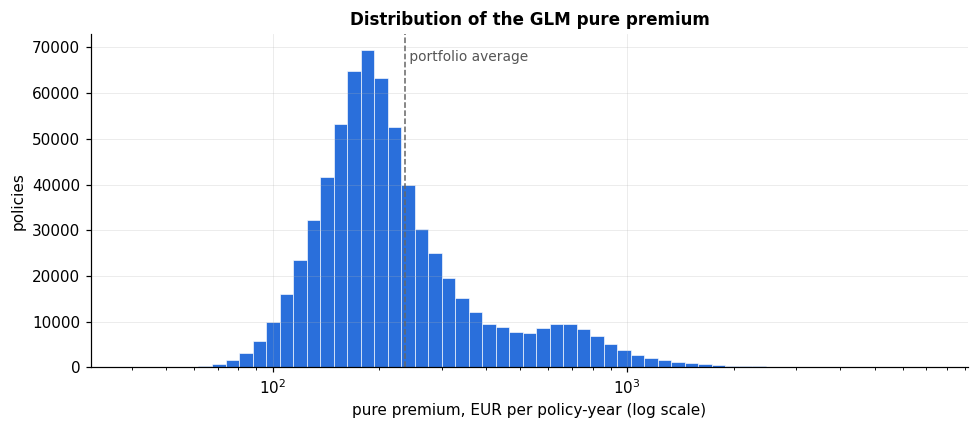

,low (5th percentile),typical (median),high (95th percentile)
DrivAge,61,54,52
BonusMalus,50,50,50
VehAge,2,8,0
VehPower,12,7,6
VehBrand,B12,B3,B2
VehGas,Diesel,Regular,Diesel
Area,A,D,E
RegionName,Haute-Normandie,Centre,Rhone-Alpes
claims per year,0.0521,0.0891,0.3063
capped cost per claim (EUR),"1,411","1,474","1,657"


In [ ]:
# ---------- 5.4 Large-claim loading and pure premium per policy ----------
for v in ["X_arr", "y_arr"]:                 # the 5.1 design matrix is no longer needed
    globals().pop(v, None)
gc.collect()

excess_tr = (c_tr["ClaimAmount"] - LARGE_CAP).clip(lower=0)
LARGE_LOAD = excess_tr.sum() / len(c_tr)
print(f"Large-claim loading: EUR {LARGE_LOAD:,.0f} per claim (training cost above the EUR {LARGE_CAP:,.0f} cap "
      f"= EUR {excess_tr.sum():,.0f}, spread over {len(c_tr):,} costed claims)")

policies["freq_glm"] = predict_freq(policies, freq_nb["params"])                              # claims per year
policies["sev_glm"] = np.concatenate([                                                        # capped cost per claim
    np.asarray(sev_glm.predict(build_design_matrices([sev_info], policies.iloc[s:s + 100_000],
                                                     return_type="dataframe")[0]))
    for s in range(0, len(policies), 100_000)])
policies["pp_glm"] = policies["freq_glm"] * (policies["sev_glm"] + LARGE_LOAD)               # EUR per policy-year

pp_pct = policies["pp_glm"].quantile([0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
pp_summary = pd.DataFrame({"EUR per policy-year": {
    "average (weighted by policy-years)": np.average(policies["pp_glm"], weights=policies["Exposure"]),
    **{f"{int(round(q * 100))}th percentile": v for q, v in pp_pct.items()}}})
display(pp_summary.style.format("{:,.0f}"))
print(f"95th percentile / 5th percentile: {pp_pct[0.95] / pp_pct[0.05]:.1f}x")

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(np.log10(policies["pp_glm"].min()), np.log10(policies["pp_glm"].max()), 60)
ax.hist(policies["pp_glm"], bins=bins, color=MAIN_COLOR, edgecolor="white", linewidth=0.4)
ax.set_xscale("log")
ax.axvline(pp_summary.iloc[0, 0], color="#666", ls="--", lw=1)
ax.text(pp_summary.iloc[0, 0], ax.get_ylim()[1] * 0.92, " portfolio average", fontsize=9, color="#555")
ax.set_xlabel("pure premium, EUR per policy-year (log scale)"); ax.set_ylabel("policies")
ax.set_title("Distribution of the GLM pure premium", fontweight="bold")
plt.tight_layout(); plt.show()

# worked examples
profile_cols = ["DrivAge", "BonusMalus", "VehAge", "VehPower", "VehBrand", "VehGas", "Area", "RegionName"]
examples = {}
for label, q in [("low (5th percentile)", 0.05), ("typical (median)", 0.5), ("high (95th percentile)", 0.95)]:
    r = policies.loc[(policies["pp_glm"] - pp_pct[q]).abs().idxmin()]
    examples[label] = {**{c: str(r[c]) for c in profile_cols},
                       "claims per year": f"{r['freq_glm']:.4f}",
                       "capped cost per claim (EUR)": f"{r['sev_glm']:,.0f}",
                       "large-claim loading per claim (EUR)": f"{LARGE_LOAD:,.0f}",
                       "pure premium (EUR per year)": f"{r['pp_glm']:,.0f}"}
pp_examples = pd.DataFrame(examples)
display(pp_examples)



**Finding:**

**The pure premium ranges from EUR 112 to EUR 735 per year between the 5th and 95th percentile, a 6.6x difference between low- and high-risk policies**.

- The portfolio average pure premium is EUR 237 per policy-year. The median policy pays EUR 197, half of policies pay between EUR 158 and EUR 275, and the highest 1% pay more than EUR 1,216.
- The large-claim loading is EUR 743 per expected claim: the EUR 15,695,779 of training claim cost above the EUR 16,451 cap, spread over 21,132 costed claims.
- Worked example: the typical policy (driver aged 54, bonus-malus 50, 8-year-old vehicle, Centre) is expected to have 0.0891 claims per year at EUR 1,474 each plus EUR 743 loading: 0.0891 × (1,474 + 743) = EUR 197 per year.
- The low-risk example (driver aged 61, 2-year-old vehicle, area A) pays EUR 112, and the high-risk example (driver aged 52, new vehicle, area E) pays EUR 735. The difference comes almost entirely from frequency (0.0521 vs 0.3063 claims per year), while cost per claim differs much less (EUR 1,411 vs EUR 1,657). All three examples are at bonus-malus 50.


## 5.5 Validation on the test set

This checks the premium on the 20% of policies the models never saw.

**Checks:**
- **Actual ÷ expected** for each part of the premium: frequency, severity, large claims, and total cost.
- **Lift chart:** test policies are split into 10 groups of equal policy-years, from lowest to highest predicted premium. Actual cost should rise from group 1 to group 10, in line with the prediction.
- **Gini:** how well the premium ranks risk (0 = random).

**"Actual" cost per test policy** = recorded capped cost + uncosted claims × average capped cost (training) + large-claim loading per claim. Large claims are spread evenly here, as in the premium, because individual large claims in a test set of ~5,000 claims are too random to judge the ranking. The large-claim row of the A/E table checks the loading level separately.

component,actual,expected,actual / expected
Frequency (number of claims),"7,225","7,312",0.988
"Severity (average capped cost per costed claim, EUR)","1,569","1,572",0.999
"Large claims (cost above cap per costed claim, EUR)",512,743,0.689
Total cost (EUR),"16,722,430","16,982,152",0.985


Uncosted test claims filled at EUR 1,569 each: 1,924 claims


,policy_years,actual cost per policy-year,predicted cost per policy-year,actual / predicted
decile (1 = lowest predicted),,,,
1,"7,158",98,106,0.926
2,"7,159",136,133,1.022
3,"7,159",140,151,0.932
4,"7,158",174,165,1.049
5,"7,159",188,179,1.051
6,"7,158",191,194,0.987
7,"7,158",202,213,0.952
8,"7,159",249,243,1.023
9,"7,158",327,310,1.055


Highest vs lowest decile, actual cost per policy-year: 6.4x
Gini (GLM pure premium, test set): 0.298


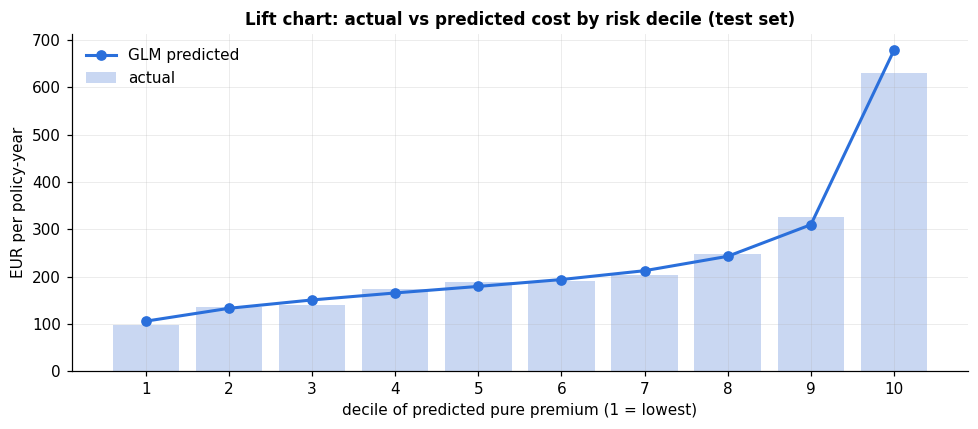

In [ ]:
# ---------- 5.5 Validation on the test set ----------
SEV_FILL = c_tr["sev_capped"].mean()          # neutral cost for claims with no recorded amount
te = policies[policies["split"] == "test"].copy()
te["capped_cost"] = te["IDpol"].map(c_te.groupby("IDpol")["sev_capped"].sum()).fillna(0)
te["actual_cost"] = te["capped_cost"] + te["n_claims_uncosted"] * SEV_FILL + te["ClaimNb_model"] * LARGE_LOAD
te["exp_cost_glm"] = te["pp_glm"] * te["Exposure"]
expo_te = te["Exposure"].to_numpy()

ae_table = pd.DataFrame([
    {"component": "Frequency (number of claims)",
     "actual": te["ClaimNb_model"].sum(), "expected": (te["freq_glm"] * te["Exposure"]).sum()},
    {"component": "Severity (average capped cost per costed claim, EUR)",
     "actual": c_te["sev_capped"].mean(), "expected": sev_te_glm.mean()},
    {"component": "Large claims (cost above cap per costed claim, EUR)",
     "actual": (c_te["ClaimAmount"] - LARGE_CAP).clip(lower=0).mean(), "expected": LARGE_LOAD},
    {"component": "Total cost (EUR)",
     "actual": te["actual_cost"].sum(), "expected": te["exp_cost_glm"].sum()},
])
ae_table["actual / expected"] = ae_table["actual"] / ae_table["expected"]
display(ae_table.style.hide(axis="index")
        .format({"actual": "{:,.0f}", "expected": "{:,.0f}", "actual / expected": "{:.3f}"}))
print(f"Uncosted test claims filled at EUR {SEV_FILL:,.0f} each: {te['n_claims_uncosted'].sum():,.0f} claims")

def exposure_deciles(score, expo, n=10):
    """Groups 1..n with equal policy-years, from lowest to highest score."""
    order = np.argsort(score, kind="mergesort")
    cum = np.empty(len(score))
    cum[order] = np.cumsum(expo[order]) / expo.sum()
    return np.clip(np.ceil(cum * n).astype(int), 1, n)

def gini_index(actual, pred_rate, expo):
    """Exposure-weighted Gini: 0 = random ranking, higher = better ranking."""
    order = np.argsort(pred_rate, kind="mergesort")
    x = np.concatenate([[0], np.cumsum(expo[order]) / expo.sum()])
    y = np.concatenate([[0], np.cumsum(actual[order]) / actual.sum()])
    return 1 - 2 * np.sum((y[1:] + y[:-1]) / 2 * np.diff(x))

te["decile_glm"] = exposure_deciles(te["pp_glm"].to_numpy(), expo_te)
lift = te.groupby("decile_glm").agg(policy_years=("Exposure", "sum"), actual=("actual_cost", "sum"),
                                    predicted=("exp_cost_glm", "sum"))
lift["actual cost per policy-year"] = lift["actual"] / lift["policy_years"]
lift["predicted cost per policy-year"] = lift["predicted"] / lift["policy_years"]
lift["actual / predicted"] = lift["actual"] / lift["predicted"]
lift = lift.drop(columns=["actual", "predicted"])
lift.index.name = "decile (1 = lowest predicted)"
display(lift.style.format({"policy_years": "{:,.0f}", "actual cost per policy-year": "{:,.0f}",
                           "predicted cost per policy-year": "{:,.0f}", "actual / predicted": "{:.3f}"}))

gini_glm = gini_index(te["actual_cost"].to_numpy(), te["pp_glm"].to_numpy(), expo_te)
print(f"Highest vs lowest decile, actual cost per policy-year: "
      f"{lift['actual cost per policy-year'].iloc[-1] / lift['actual cost per policy-year'].iloc[0]:.1f}x")
print(f"Gini (GLM pure premium, test set): {gini_glm:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(lift.index, lift["actual cost per policy-year"], color="#c9d7f2", label="actual")
ax.plot(lift.index, lift["predicted cost per policy-year"], color=MAIN_COLOR, marker="o", lw=2, label="GLM predicted")
ax.set_xticks(lift.index); ax.set_xlabel("decile of predicted pure premium (1 = lowest)")
ax.set_ylabel("EUR per policy-year"); ax.legend(frameon=False)
ax.set_title("Lift chart: actual vs predicted cost by risk decile (test set)", fontweight="bold")
plt.tight_layout(); plt.show()

**Finding:**

**On unseen policies, the premium predicts total cost within 1.5% and separates low- and high-risk policies well**.

- Actual ÷ expected on the test set is 0.988 for frequency (7,225 vs 7,312 claims), 0.999 for severity (EUR 1,569 vs EUR 1,572 per claim) and 0.985 for total cost (EUR 16,722,430 vs EUR 16,982,152). The 1,924 test claims without a recorded cost were filled in at EUR 1,569 each.
- Test claims cost EUR 512 above the cap per costed claim, against a loading of EUR 743 (ratio 0.689). Large claims are rare and random, so one test set cannot reliably check the loading; it is kept at the training level.
- In the lift chart, actual cost rises in every decile, from EUR 98 per policy-year in the lowest to EUR 631 in the highest (6.4x), and actual ÷ predicted stays between 0.926 and 1.055. Both ends are slightly over-predicted (0.926 in decile 1, 0.929 in decile 10).
- The Gini of the pure premium on the test set is 0.298.

## 5.6 GBM challenger

This step builds a gradient boosting model (GBM) for frequency and severity and compares it with the GLM on the test set.

**Why a GBM:** a GLM only finds the effects it's given: one relativity per band, and no interactions unless added. A GBM builds hundreds of small decision trees and can find curves within bands (e.g. age 22 vs 25) and combinations of factors on its own. If it predicts clearly better, the GLM is missing something.

**Method:**
- **Inputs:** raw (unbanded) driver age, bonus-malus, vehicle age, vehicle power and log density, plus brand, fuel, area and region. The GBM sees more detail than the GLM; that is the point of the challenge.
- **Frequency:** claims per policy-year with Poisson loss, weighted by exposure (equivalent to the GLM's exposure offset). **Severity:** capped cost with Gamma loss.
- **Settings:** learning rate 0.05; trees stop being added when a 10% validation slice of the training data stops improving (early stopping); the minimum leaf size keeps each tree split based on enough data.
- **Pure premium** is built the same way as for the GLM: frequency × (severity + the same large-claim loading).
- **Comparison (test set):** mean deviance for frequency and severity, with a 95% interval for the GBM − GLM difference (paired, normal approximation); Gini, with a 95% bootstrap interval (200 resamples). The GBM is clearly better only if the interval excludes zero in its favour.

In [ ]:
# ---------- 5.6 GBM challenger ----------
from sklearn.ensemble import HistGradientBoostingRegressor

gbm_num = ["DrivAge", "BonusMalus", "VehAge", "VehPower", "LogDensity"]
gbm_cat = ["VehBrand", "VehGas", "Area", "RegionName"]
cat_levels = {c: sorted(policies[c].astype(str).unique()) for c in gbm_cat}

def gbm_matrix(df):
    X = df[gbm_num].astype(float).reset_index(drop=True)
    for c in gbm_cat:
        codes = pd.Categorical(df[c].astype(str), categories=cat_levels[c]).codes
        X[c] = np.where(codes < 0, np.nan, codes)
    return X

cat_mask = [False] * len(gbm_num) + [True] * len(gbm_cat)
gbm_settings = dict(learning_rate=0.05, max_iter=1000, early_stopping=True, validation_fraction=0.1,
                    n_iter_no_change=30, l2_regularization=1.0, categorical_features=cat_mask,
                    random_state=SEED)

gbm_freq = HistGradientBoostingRegressor(loss="poisson", max_leaf_nodes=31, min_samples_leaf=1000, **gbm_settings)
gbm_freq.fit(gbm_matrix(train), train["ClaimNb_model"] / train["Exposure"], sample_weight=train["Exposure"])
gbm_sev = HistGradientBoostingRegressor(loss="gamma", max_leaf_nodes=15, min_samples_leaf=200, **gbm_settings)
gbm_sev.fit(gbm_matrix(c_tr), c_tr["sev_capped"])
print(f"Trees used: frequency GBM {gbm_freq.n_iter_} | severity GBM {gbm_sev.n_iter_}")

X_all_g = gbm_matrix(policies)
policies["freq_gbm"] = gbm_freq.predict(X_all_g)
policies["sev_gbm"] = gbm_sev.predict(X_all_g)
policies["pp_gbm"] = policies["freq_gbm"] * (policies["sev_gbm"] + LARGE_LOAD)
del X_all_g

te[["freq_gbm", "sev_gbm", "pp_gbm"]] = policies.loc[te.index, ["freq_gbm", "sev_gbm", "pp_gbm"]]
te["exp_cost_gbm"] = te["pp_gbm"] * te["Exposure"]
mu_te_gbm = te["freq_gbm"].to_numpy() * expo_te
sev_te_gbm = gbm_sev.predict(gbm_matrix(c_te))

# per-policy / per-claim deviances, so the difference can get a confidence interval
def poisson_unit_dev(y, mu):
    return 2 * (np.where(y > 0, y * np.log(np.where(y > 0, y, 1) / mu), 0) - (y - mu))
def gamma_unit_dev(y, mu):
    return 2 * (-np.log(y / mu) + (y - mu) / mu)
def paired_interval(d):
    se = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean() - 1.96 * se, d.mean() + 1.96 * se

ys_te_c = c_te["sev_capped"].to_numpy()
fd_glm, fd_gbm = poisson_unit_dev(y_te, mu_te_glm), poisson_unit_dev(y_te, mu_te_gbm)
sd_glm, sd_gbm = gamma_unit_dev(ys_te_c, sev_te_glm), gamma_unit_dev(ys_te_c, sev_te_gbm)

act, p_glm, p_gbm = te["actual_cost"].to_numpy(), te["pp_glm"].to_numpy(), te["pp_gbm"].to_numpy()
gini_gbm = gini_index(act, p_gbm, expo_te)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(200):
    i = rng.integers(0, len(act), len(act))
    boot.append(gini_index(act[i], p_gbm[i], expo_te[i]) - gini_index(act[i], p_glm[i], expo_te[i]))
gini_lo, gini_hi = np.percentile(boot, [2.5, 97.5])

f_lo, f_hi = paired_interval(fd_gbm - fd_glm)
s_lo, s_hi = paired_interval(sd_gbm - sd_glm)
gbm_compare = pd.DataFrame([
    {"measure": "Frequency: mean Poisson deviance (lower = better)", "GLM": fd_glm.mean(), "GBM": fd_gbm.mean(),
     "interval low": f_lo, "interval high": f_hi, "GBM clearly better": "yes" if f_hi < 0 else "no"},
    {"measure": "Severity: mean Gamma deviance (lower = better)", "GLM": sd_glm.mean(), "GBM": sd_gbm.mean(),
     "interval low": s_lo, "interval high": s_hi, "GBM clearly better": "yes" if s_hi < 0 else "no"},
    {"measure": "Pure premium: Gini (higher = better)", "GLM": gini_glm, "GBM": gini_gbm,
     "interval low": gini_lo, "interval high": gini_hi, "GBM clearly better": "yes" if gini_lo > 0 else "no"},
    {"measure": "Total cost: actual / expected", "GLM": act.sum() / te["exp_cost_glm"].sum(),
     "GBM": act.sum() / te["exp_cost_gbm"].sum(), "interval low": np.nan, "interval high": np.nan,
     "GBM clearly better": "-"},
])
gbm_compare["GBM - GLM"] = gbm_compare["GBM"] - gbm_compare["GLM"]
gbm_compare = gbm_compare[["measure", "GLM", "GBM", "GBM - GLM", "interval low", "interval high", "GBM clearly better"]]
print("Test set comparison (interval = 95% interval for GBM - GLM)")
display(gbm_compare.style.hide(axis="index").format(
    {c: "{:.4f}" for c in ["GLM", "GBM", "GBM - GLM", "interval low", "interval high"]}, na_rep="-"))

Trees used: frequency GBM 367 | severity GBM 43
Test set comparison (interval = 95% interval for GBM - GLM)


measure,GLM,GBM,GBM - GLM,interval low,interval high,GBM clearly better
Frequency: mean Poisson deviance (lower = better),0.3128,0.3018,-0.0110,-0.0123,-0.0098,yes
Severity: mean Gamma deviance (lower = better),1.0317,1.0353,0.0036,-0.0034,0.0107,no
Pure premium: Gini (higher = better),0.2979,0.3503,0.0524,0.0401,0.0669,yes
Total cost: actual / expected,0.9847,1.0127,0.0280,-,-,-


**Finding:**

**The GBM predicts claim frequency clearly better than the GLM and ranks risk better, but adds nothing for cost per claim**.

- Frequency: the GBM's test deviance is 0.3018 against 0.3128 for the GLM, a difference of -0.0110 (95% interval -0.0123 to -0.0098), so the GBM is clearly better.
- Severity: the GBM is not better (1.0353 vs 1.0317, difference 0.0036, 95% interval -0.0034 to 0.0107). It stopped after 43 trees (vs 367 for frequency), showing there is little extra structure in cost per claim for it to learn.
- Ranking of total cost: the GBM's Gini is 0.3503 against 0.2979 for the GLM, an improvement of 0.0524 (95% interval 0.0401 to 0.0669).
- Both models predict total test-set cost closely (actual ÷ expected 1.0127 for the GBM and 0.9847 for the GLM).
- The GLM is therefore missing some frequency patterns; 5.7 shows where.

## 5.7 Where the GBM and GLM disagree

**What this step does:** finds the policies where the two models disagree most, checks which model is closer to actual cost there, and describes who those policies are.

**Method:**
- **Double-lift chart:** test policies are sorted by GBM premium ÷ GLM premium and split into 10 groups of equal policy-years. Group 1 = GBM much lower than GLM; group 10 = GBM much higher. Both models are first rescaled to the actual total, so only the ranking is compared. In each group, the model whose prediction is closer to actual cost is "right" there.
- **Profile:** the average characteristics of groups 1 and 10 compared with all test policies.
- **Pattern charts:** actual vs predicted frequency by single year of driver age and vehicle age (ages with at least 500 test policy-years). Smooth curves within bands are something only the GBM can capture.

,policy_years,GBM / GLM premium,actual per policy-year,GLM per policy-year,GBM per policy-year,actual / GLM,actual / GBM,closer to actual
decile (1 = GBM lowest vs GLM),,,,,,,,
1,"7,158",0.43,178,366,158,0.486,1.125,GBM
2,"7,158",0.65,155,235,153,0.660,1.014,GBM
3,"7,158",0.75,177,214,162,0.828,1.098,GBM
4,"7,158",0.84,175,204,171,0.858,1.027,GBM
5,"7,159",0.91,195,202,184,0.967,1.063,GLM
6,"7,158",0.98,178,199,195,0.895,0.912,GBM
7,"7,158",1.06,206,203,215,1.018,0.958,GLM
8,"7,158",1.16,225,204,236,1.106,0.954,GBM
9,"7,158",1.31,276,219,286,1.262,0.965,GBM


GBM closer to actual in 8 of 10 deciles


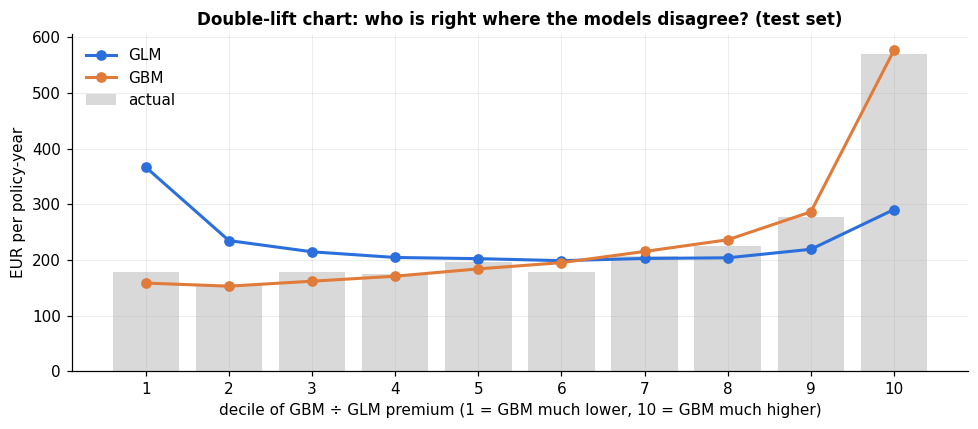

,GBM much lower (decile 1),all test policies,GBM much higher (decile 10)
policies,"15,770.0","135,603.0","15,336.0"
policy-years,"7,158.2","71,583.6","7,158.4"
average exposure (years),0.5,0.5,0.5
average driver age,43.7,45.5,43.9
average bonus-malus,60.5,59.8,67.0
% at bonus-malus 50,40.4,56.7,37.7
average vehicle age,5.8,7.0,6.1
% new vehicles (age 0),34.9,8.7,17.4
median density,298.0,393.0,634.0
% diesel,44.8,49.1,50.8


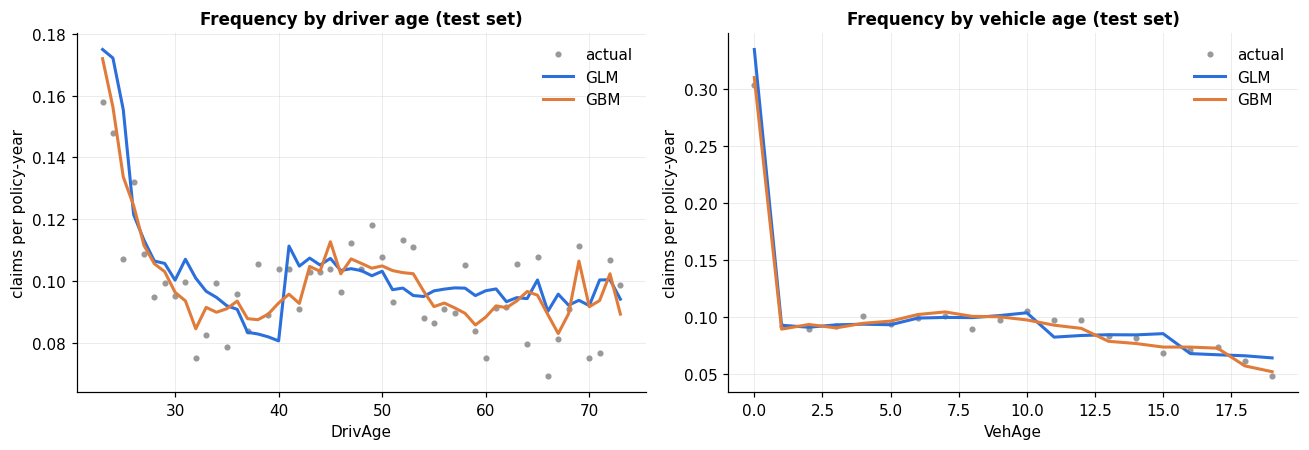

In [ ]:
# ---------- 5.7 Where the GBM and GLM disagree ----------
k_glm = act.sum() / te["exp_cost_glm"].sum()      # rescale both models to the actual total,
k_gbm = act.sum() / te["exp_cost_gbm"].sum()      # so only the ranking is compared
te["gbm_vs_glm"] = (te["pp_gbm"] * k_gbm) / (te["pp_glm"] * k_glm)
te["decile_ratio"] = exposure_deciles(te["gbm_vs_glm"].to_numpy(), expo_te)

dl = te.groupby("decile_ratio").agg(policy_years=("Exposure", "sum"), actual=("actual_cost", "sum"),
                                    glm=("exp_cost_glm", "sum"), gbm=("exp_cost_gbm", "sum"))
dl["glm"] *= k_glm; dl["gbm"] *= k_gbm
dl["GBM / GLM premium"] = dl["gbm"] / dl["glm"]
dl["actual per policy-year"] = dl["actual"] / dl["policy_years"]
dl["GLM per policy-year"] = dl["glm"] / dl["policy_years"]
dl["GBM per policy-year"] = dl["gbm"] / dl["policy_years"]
dl["actual / GLM"] = dl["actual"] / dl["glm"]
dl["actual / GBM"] = dl["actual"] / dl["gbm"]
dl["closer to actual"] = np.where((dl["actual / GBM"] - 1).abs() < (dl["actual / GLM"] - 1).abs(), "GBM", "GLM")
dl = dl.drop(columns=["actual", "glm", "gbm"])
dl.index.name = "decile (1 = GBM lowest vs GLM)"
display(dl.style.format({"policy_years": "{:,.0f}", "GBM / GLM premium": "{:.2f}",
                         "actual per policy-year": "{:,.0f}", "GLM per policy-year": "{:,.0f}",
                         "GBM per policy-year": "{:,.0f}", "actual / GLM": "{:.3f}", "actual / GBM": "{:.3f}"}))
print(f"GBM closer to actual in {(dl['closer to actual'] == 'GBM').sum()} of 10 deciles")

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(dl.index, dl["actual per policy-year"], color="#d9d9d9", label="actual")
ax.plot(dl.index, dl["GLM per policy-year"], color=MAIN_COLOR, marker="o", lw=2, label="GLM")
ax.plot(dl.index, dl["GBM per policy-year"], color="#e07b39", marker="o", lw=2, label="GBM")
ax.set_xticks(dl.index); ax.set_xlabel("decile of GBM ÷ GLM premium (1 = GBM much lower, 10 = GBM much higher)")
ax.set_ylabel("EUR per policy-year"); ax.legend(frameon=False)
ax.set_title("Double-lift chart: who is right where the models disagree? (test set)", fontweight="bold")
plt.tight_layout(); plt.show()

# who are the policies where the models disagree most?
def profile_of(d):
    return pd.Series({
        "policies": len(d), "policy-years": d["Exposure"].sum(),
        "average exposure (years)": d["Exposure"].mean(),
        "average driver age": d["DrivAge"].mean(), "average bonus-malus": d["BonusMalus"].mean(),
        "% at bonus-malus 50": (d["BonusMalus"] == 50).mean() * 100,
        "average vehicle age": d["VehAge"].mean(), "% new vehicles (age 0)": (d["VehAge"] == 0).mean() * 100,
        "median density": d["Density"].median(),
        "% diesel": d["VehGas"].astype(str).str.contains("Diesel").mean() * 100,
        "average GLM premium (EUR)": np.average(d["pp_glm"], weights=d["Exposure"]),
        "average GBM premium (EUR)": np.average(d["pp_gbm"], weights=d["Exposure"]),
    })
disagree_profile = pd.DataFrame({
    "GBM much lower (decile 1)": profile_of(te[te["decile_ratio"] == 1]),
    "all test policies": profile_of(te),
    "GBM much higher (decile 10)": profile_of(te[te["decile_ratio"] == 10]),
})
display(disagree_profile.style.format("{:,.1f}"))

# patterns within bands: frequency by single year of driver age and vehicle age
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, lo, hi in [(axes[0], "DrivAge", 18, 90), (axes[1], "VehAge", 0, 20)]:
    d = te[(te[col] >= lo) & (te[col] <= hi)].assign(
        glm=lambda x: x["freq_glm"] * x["Exposure"], gbm=lambda x: x["freq_gbm"] * x["Exposure"])
    g = d.groupby(col).agg(py=("Exposure", "sum"), actual=("ClaimNb_model", "sum"),
                           glm=("glm", "sum"), gbm=("gbm", "sum"))
    g = g[g["py"] >= 500]
    ax.plot(g.index, g["actual"] / g["py"], "o", color="#999", ms=3, label="actual")
    ax.plot(g.index, g["glm"] / g["py"], color=MAIN_COLOR, lw=2, label="GLM")
    ax.plot(g.index, g["gbm"] / g["py"], color="#e07b39", lw=2, label="GBM")
    ax.set_xlabel(col); ax.set_ylabel("claims per policy-year"); ax.legend(frameon=False)
axes[0].set_title("Frequency by driver age (test set)")
axes[1].set_title("Frequency by vehicle age (test set)")
plt.tight_layout(); plt.show()

**Finding:**

**Where the models disagree, the GBM is closer to actual cost in 8 of 10 deciles, and the biggest disagreements involve new vehicles**.

- The GBM's premium ranges from 0.43 times the GLM's (decile 1) to 1.99 times (decile 10).
- In decile 1, actual cost is EUR 178 per policy-year, against EUR 366 from the GLM and EUR 158 from the GBM, so the GLM charges about twice the actual cost (actual ÷ GLM 0.486). New vehicles make up 34.9% of these policies, against 8.7% of all test policies.
- In decile 10, actual cost is EUR 570, against EUR 290 from the GLM and EUR 577 from the GBM, so the GLM charges about half (actual ÷ GLM 1.961). These policies also include more new vehicles (17.4%), have a higher average bonus-malus (67.0 vs 59.8), fewer drivers at bonus-malus 50 (37.7% vs 56.7%) and live in denser areas (median density 634 vs 393).
- New vehicles are over-represented at both extremes. The GLM applies one high multiplier to every new vehicle, while the GBM finds that new-vehicle risk varies widely with the vehicle's other characteristics: much lower for some, higher for others.
- Average exposure is 0.5 years in both extreme deciles, the same as for all test policies, so short policies do not explain the disagreement.
- By single year of age, both models follow actual frequency similarly. The GLM jumps at band boundaries (e.g. from about 0.08 at age 40 to about 0.11 at age 41) while the GBM changes gradually, and both give almost identical curves by vehicle age. The main pattern the GLM misses is therefore how new-vehicle risk combines with other factors, not the shape within bands.

## Conclusion - Objective 4


- **Frequency model:** a negative binomial GLM with all eight rating factors (vehicle age and bonus-malus strongest) plus a driver age × bonus-malus 50 interaction (AIC gain 64.0). Its relativities differ from a Poisson model by at most 5.0%, so the distribution choice in Section 4 does not affect prices.
- **Severity model:** a Gamma GLM with driver age, region and vehicle age, predicting the average test-set claim cost within 0.1% (ratio 1.001). Cost per claim varies much less than frequency, so most price differences between customers come from frequency.
- **Pure premium:** expected claims cost ranges from EUR 112 to EUR 735 per year between the 5th and 95th percentile (6.6x), around a portfolio average of EUR 237, including a large-claim loading of EUR 743 per expected claim.
- **Validation:** on unseen test policies, actual ÷ expected total cost is 0.985, actual cost rises in every decile from EUR 98 to EUR 631 per policy-year (6.4x), and the Gini is 0.298.
- **GBM challenger:** the GBM predicts frequency clearly better (deviance 0.3018 vs 0.3128) and ranks risk better (Gini 0.3503 vs 0.2979), but adds nothing for severity. Where the two disagree most, the GBM is closer to actual cost in 8 of 10 deciles, and the GLM's largest errors (charging about twice or about half the actual cost) involve a high share of new vehicles.

**Business implications**
1. Each policy now has a risk-based price, with a 6.6x gap between low- and high-risk customers; a single flat price would overcharge low-risk customers and undercharge high-risk ones. Section 6 measures this cross-subsidy.
2. The bonus-malus discount should depend on age: young drivers at bonus-malus 50 claim far more than the discount assumes (2.129 times for ages 21-25), while older drivers at 50 claim less (0.707 for 71+). Without the interaction, older customers would subsidise young ones with an unearned discount.
3. The GLM stays as the tariff because each factor's effect can be explained to customers, managers and regulators. The GBM shows that about 20% of policy-years (the two extreme deciles) are priced at roughly half or double their actual cost by the GLM, mostly involving new vehicles. Rating new vehicles in combination with other factors could capture much of the GBM's gain while keeping the tariff explainable.
4. Large claims add EUR 743 per expected claim, about a third of the typical policy's cost per claim (743 of 1,474 + 743). The test set showed less large-claim cost (EUR 512 per claim), so the loading should be reviewed with more years of data and against reinsurance costs.

**Limitations**
- Claims without a recorded cost are assumed to cost the same as similar costed claims; Section 1 showed missing costs are not random, so the premium level may be understated for groups with many uncosted claims.
- The pure premium covers expected claims only; a commercial premium would add expenses, commission, profit margin and tax.
- Factors were selected in one round (each removed or added on its own), and the negative binomial alpha was fixed at its Section 4 estimate (0.790).
- For severity, the Gamma model's AIC was unstable for some factors, so the F-test carried the decision; vehicle age passed only narrowly (p = 9.1e-03).
- The GBM used standard settings with early stopping, not a full tuning search, and it explains less clearly than the GLM why a policy's price is high or low.
- The large-claim loading could not be validated reliably on the test set (actual ÷ expected 0.689).
- The data covers one French insurer's portfolio, so the relativities may not carry over to other markets.

# Pricing adequacy and cross-subsidy

**Key question:** Which segments are subsidised or overcharged under the current tariff, and by how much?

**Terms used:**
- **Technical premium:** a customer's expected claims cost per year from the Section 5 GLM. It is the yardstick for what each customer *should* pay.
- **Premium ÷ technical:** below 1 = the customer pays less than they are expected to cost (**subsidised**); above 1 = they pay more (**overcharged**, so they subsidise others).
- **Net transfer (EUR):** premium minus expected cost for a segment. Negative = the segment receives a subsidy; positive = it pays for others.
- **Premium shifted between customers:** the total amount overcharged customers pay above their expected cost. Because every tariff breaks even, this equals the total undercharge to subsidised customers.
- **Loss ratio:** actual claims cost ÷ premium. 1.00 = premium exactly covers claims; above 1 = loss-making.


## 6.1 Three tariffs, all set to break even

This step builds the flat, bonus-malus-only and GLM premiums for every policy and scales the first two so each collects the same total premium as the GLM's expected claims cost.

In [ ]:
# ---------- 6.1 Three tariffs, all set to break even ----------
expo = policies["Exposure"].to_numpy()
tech = policies["pp_glm"].to_numpy()                 # technical premium = GLM pure premium (EUR per policy-year)
total_cost = np.sum(tech * expo)                     # total expected claims cost of the portfolio

def break_even(rate):
    """Scale a premium rate so the portfolio's total premium equals its total expected claims cost."""
    rate = np.asarray(rate, dtype=float)
    return rate * total_cost / np.sum(rate * expo)

policies["prem_flat"] = break_even(np.ones(len(policies)))                  # everyone pays the same
policies["prem_bm"] = break_even(policies["BonusMalus"].to_numpy() / 100)    # base price x bonus-malus coefficient
policies["prem_glm"] = tech                                                  # risk-based technical premium
policies["tech_gbm"] = break_even(policies["pp_gbm"].to_numpy())             # GBM benchmark, same total cost

tariffs = {"Flat": "prem_flat", "Bonus-malus only": "prem_bm", "GLM (technical)": "prem_glm"}
tariff_tbl = pd.DataFrame({name: {
    "total premium (EUR)": np.sum(policies[c].to_numpy() * expo),
    "average premium (EUR per policy-year)": np.sum(policies[c].to_numpy() * expo) / expo.sum(),
    "lowest premium (EUR per year)": policies[c].min(),
    "highest premium (EUR per year)": policies[c].max()} for name, c in tariffs.items()}).T
tariff_tbl.index.name = "tariff"
display(tariff_tbl.style.format("{:,.0f}"))

bm_base = total_cost / np.sum(policies["BonusMalus"].to_numpy() / 100 * expo)
print(f"Flat tariff: EUR {policies['prem_flat'].iloc[0]:,.0f} per policy-year for every customer")
print(f"Bonus-malus tariff: EUR {bm_base:,.0f} at bonus-malus 100, EUR {bm_base * 0.5:,.0f} at the 50 floor")

,total premium (EUR),average premium (EUR per policy-year),lowest premium (EUR per year),highest premium (EUR per year)
tariff,,,,
Flat,"84,791,890",237,237,237
Bonus-malus only,"84,791,890",237,205,942
GLM (technical),"84,791,890",237,40,"7,082"


Flat tariff: EUR 237 per policy-year for every customer
Bonus-malus tariff: EUR 409 at bonus-malus 100, EUR 205 at the 50 floor


**Finding:**

**All three tariffs collect the same EUR 84,791,890 in total, but spread it very differently across customers**.

- The flat tariff charges every customer EUR 237 per policy-year.
- The bonus-malus tariff charges EUR 409 at bonus-malus 100 and EUR 205 at the 50 floor, so premiums range from EUR 205 to EUR 942 per year.
- The GLM technical premium ranges from EUR 40 to EUR 7,082 per year, a far wider range, because it uses all rating factors rather than claims history alone.

## 6.2 How much premium is shifted between customers?

The step compares each customer's premium with their expected cost and adds up how much is shifted from overcharged to undercharged customers.

**How to read it:**
- **Premium shifted:** the total EUR that overcharged customers pay above their expected cost. The same amount subsidises undercharged customers.
- **% overcharged / undercharged by more than 20%:** the share of the portfolio priced well away from its expected cost. 20% is a practical judgement of a gap large enough for a customer to notice when comparing quotes.
- **Last row (GLM vs GBM):** how much mispricing the GLM itself still leaves, using the GBM as a more flexible yardstick (Section 5.6-5.7).

,premium shifted between customers (EUR),% of total premium,% of policy-years overcharged by more than 20%,% of policy-years undercharged by more than 20%,premium / technical: 5th percentile,premium / technical: 95th percentile
comparison,,,,,,
Flat vs GLM technical premium,"18,550,465",21.9%,57.0%,15.8%,0.32,2.11
Bonus-malus only vs GLM technical premium,"14,988,050",17.7%,48.6%,11.3%,0.32,1.92
GLM vs GBM (what the GLM still misses),"14,395,613",17.0%,34.6%,17.8%,0.57,2.15


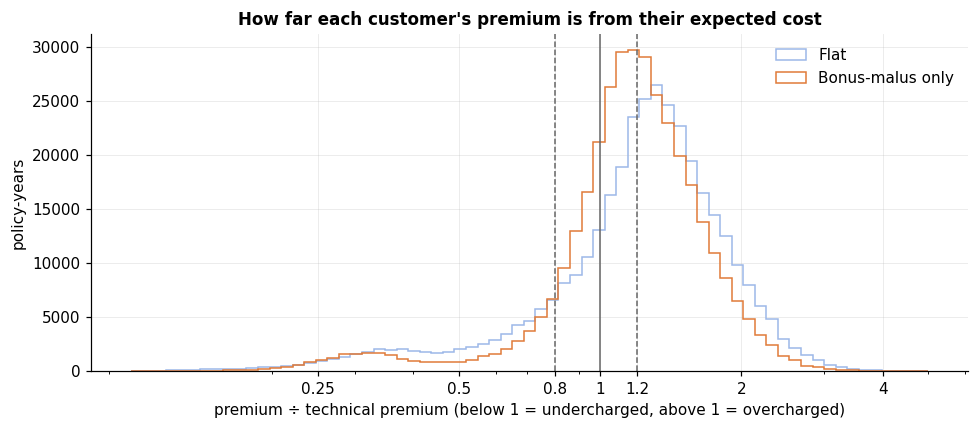

In [ ]:
# ---------- 6.2 How much premium is shifted between customers? ----------
def cross_subsidy(prem, bench):
    gap = (prem - bench) * expo                      # EUR overcharged (+) or undercharged (-) per policy
    ratio = prem / bench
    shifted = gap[gap > 0].sum()                     # = total undercharge, because both totals are equal
    return {"premium shifted between customers (EUR)": shifted,
            "% of total premium": shifted / np.sum(prem * expo) * 100,
            "% of policy-years overcharged by more than 20%": expo[ratio > 1.2].sum() / expo.sum() * 100,
            "% of policy-years undercharged by more than 20%": expo[ratio < 0.8].sum() / expo.sum() * 100,
            "premium / technical: 5th percentile": np.percentile(ratio, 5),
            "premium / technical: 95th percentile": np.percentile(ratio, 95)}

cs_tbl = pd.DataFrame({
    "Flat vs GLM technical premium": cross_subsidy(policies["prem_flat"].to_numpy(), tech),
    "Bonus-malus only vs GLM technical premium": cross_subsidy(policies["prem_bm"].to_numpy(), tech),
    "GLM vs GBM (what the GLM still misses)": cross_subsidy(tech, policies["tech_gbm"].to_numpy()),
}).T
cs_tbl.index.name = "comparison"
display(cs_tbl.style.format({c: ("{:,.0f}" if "EUR" in c else "{:.2f}" if "percentile" in c else "{:.1f}%")
                             for c in cs_tbl.columns}))

fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(np.log10(0.1), np.log10(5), 70)
for name, c, col in [("Flat", "prem_flat", "#9db8e8"), ("Bonus-malus only", "prem_bm", "#e07b39")]:
    ax.hist(policies[c] / policies["pp_glm"], bins=bins, weights=expo, histtype="step", lw=2, color=col, label=name)
for x in [0.8, 1.0, 1.2]:
    ax.axvline(x, color="#666", ls="--" if x != 1 else "-", lw=1)
ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 0.8, 1, 1.2, 2, 4]); ax.set_xticklabels(["0.25", "0.5", "0.8", "1", "1.2", "2", "4"])
ax.set_xlabel("premium ÷ technical premium (below 1 = undercharged, above 1 = overcharged)")
ax.set_ylabel("policy-years"); ax.legend(frameon=False)
ax.set_title("How far each customer's premium is from their expected cost", fontweight="bold")
plt.tight_layout(); plt.show()

**Finding:**

**Under the bonus-malus tariff, EUR 14,988,050 (17.7% of total premium) is shifted from overcharged to undercharged customers**.

- Under the flat tariff, EUR 18,550,465 (21.9% of premium) is shifted; 57.0% of policy-years are overcharged and 15.8% undercharged by more than 20%.
- The bonus-malus tariff reduces the shift only modestly, to EUR 14,988,050 (17.7%). 48.6% of policy-years are still overcharged and 11.3% undercharged by more than 20%, with premiums ranging from 0.32 to 1.92 times expected cost (5th to 95th percentile).
- The pattern is lopsided: many customers are overcharged by a moderate amount, while fewer customers are undercharged by a lot. The chart shows a small group paying only around a quarter to a half of their expected cost.
- The GLM and the GBM also disagree on individual prices by EUR 14,395,613 (17.0%). Part of this reflects patterns the GLM misses (5.7), and part reflects noise in the GBM's individual predictions, so it is an upper limit on the GLM's own mispricing rather than a measure of it.

## 6.3 Which segments are subsidised or overcharged?

**What this step does:** for each rating factor level, compares the average flat and bonus-malus premium with the average expected cost, and calculates the net EUR transferred.

**How to read it:**

- red means subsidised (premium ÷ technical below 1)
- blue = overcharged (above 1).

The second table lists the five largest subsidised and overcharged segments under the bonus-malus tariff, among segments with at least 1,000 policy-years.

factor,level,policy-years,technical premium (EUR per year),flat / technical,BM-only / technical,"net transfer, flat (EUR)","net transfer, BM-only (EUR)"
DrivAgeBand,18-20,"2,585",730,0.32,0.53,"-1,274,124","-892,176"
DrivAgeBand,21-25,"13,643",398,0.60,0.89,"-2,195,455","-619,635"
DrivAgeBand,26-30,"29,167",250,0.95,1.18,"-401,528","1,279,088"
DrivAgeBand,31-40,"83,898",208,1.14,1.17,"2,379,401","2,953,342"
DrivAgeBand,41-50,"88,100",239,0.99,0.93,"-175,844","-1,474,694"
DrivAgeBand,51-60,"75,700",225,1.05,0.97,"886,930","-560,413"
DrivAgeBand,61-70,"38,321",215,1.10,1.00,"821,657","-7,563"
DrivAgeBand,71+,"26,947",238,0.99,0.89,"-41,038","-677,949"
BonusMalusBand,50,"225,153",186,1.27,1.10,"11,385,219","4,204,481"
BonusMalusBand,51-70,"74,443",257,0.92,0.94,"-1,516,134","-1,162,990"


Largest transfers under the bonus-malus tariff (segments with at least 1,000 policy-years)


direction,factor,level,policy-years,technical premium (EUR per year),BM-only / technical,"net transfer, BM-only (EUR)"
subsidised (pays too little),VehAgeBand,0,"16,696",810,0.29,"-9,582,677"
subsidised (pays too little),VehBrand,B12,"64,802",336,0.71,"-6,356,157"
subsidised (pays too little),Area,E,"63,786",292,0.85,"-2,790,513"
subsidised (pays too little),BonusMalusBand,91-100,"13,395",544,0.73,"-1,955,578"
subsidised (pays too little),RegionName,Provence-Alpes-Cote d'Azur,"35,749",285,0.83,"-1,743,932"
overcharged (pays too much),BonusMalusBand,50,"225,153",186,1.10,"4,204,481"
overcharged (pays too much),VehAgeBand,11-15,"77,955",188,1.28,"4,076,520"
overcharged (pays too much),RegionName,Centre,"102,706",202,1.15,"3,072,861"
overcharged (pays too much),DrivAgeBand,31-40,"83,898",208,1.17,"2,953,342"
overcharged (pays too much),VehAgeBand,16+,"30,272",143,1.66,"2,870,692"


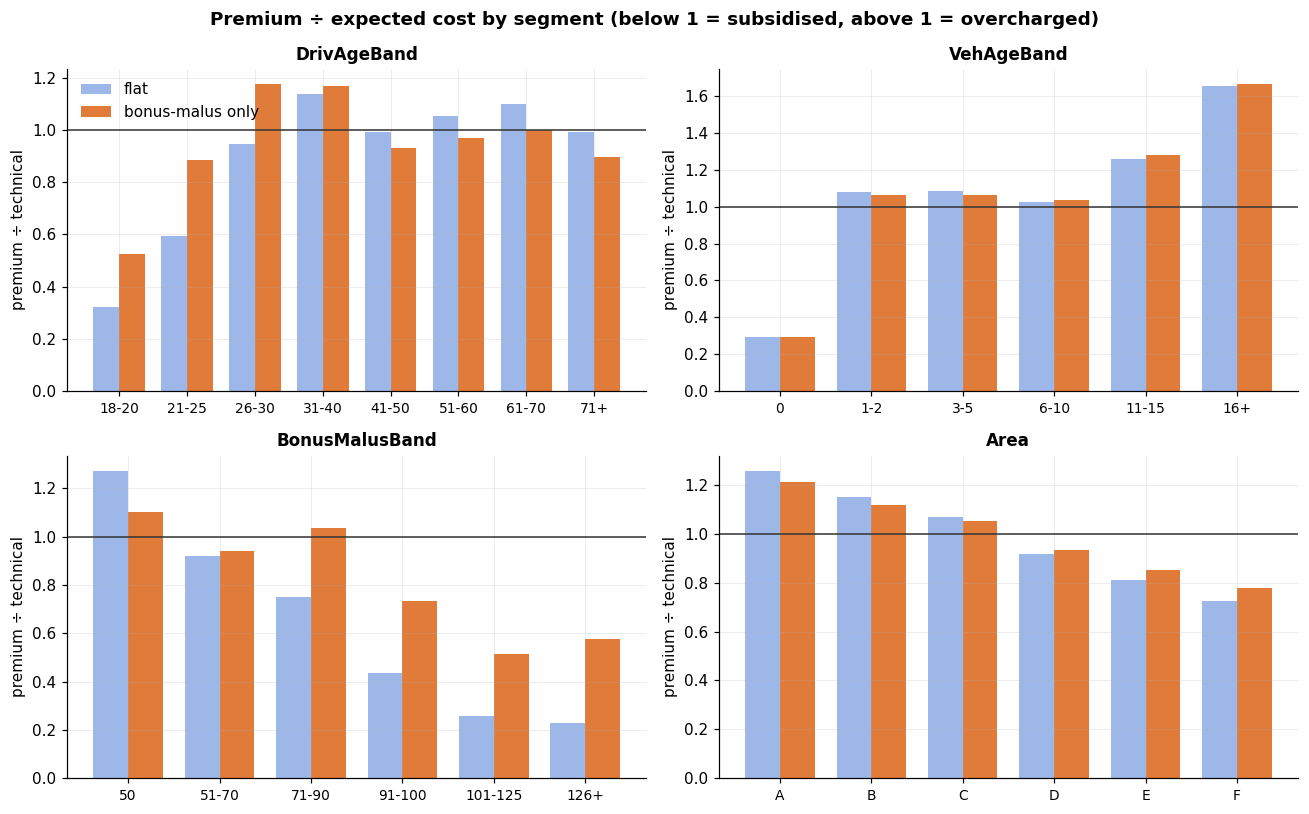

In [ ]:
# ---------- 6.3 Which segments are subsidised or overcharged? ----------
seg_factors = ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "VehPowerBand", "VehBrand", "VehGas", "Area", "RegionName"]
tmp = pd.DataFrame({"policy_years": expo, "technical": tech * expo,
                    "flat": policies["prem_flat"].to_numpy() * expo, "bm": policies["prem_bm"].to_numpy() * expo})
parts = []
for f in seg_factors:
    g = tmp.groupby(policies[f].astype(str).to_numpy()).sum()
    order = ([str(l) for l in policies[f].cat.categories] if isinstance(policies[f].dtype, pd.CategoricalDtype)
             else sorted(g.index))
    g = g.reindex([l for l in order if l in g.index])
    parts.append(pd.DataFrame({
        "factor": f, "level": g.index.astype(str),
        "policy-years": g["policy_years"].to_numpy(),
        "technical premium (EUR per year)": (g["technical"] / g["policy_years"]).to_numpy(),
        "flat / technical": (g["flat"] / g["technical"]).to_numpy(),
        "BM-only / technical": (g["bm"] / g["technical"]).to_numpy(),
        "net transfer, flat (EUR)": (g["flat"] - g["technical"]).to_numpy(),
        "net transfer, BM-only (EUR)": (g["bm"] - g["technical"]).to_numpy()}))
seg_adequacy = pd.concat(parts, ignore_index=True)
ratio_cols = ["flat / technical", "BM-only / technical"]
display(seg_adequacy.style.hide(axis="index")
        .format({"policy-years": "{:,.0f}", "technical premium (EUR per year)": "{:,.0f}",
                 "flat / technical": "{:.2f}", "BM-only / technical": "{:.2f}",
                 "net transfer, flat (EUR)": "{:,.0f}", "net transfer, BM-only (EUR)": "{:,.0f}"})
        .background_gradient(cmap="RdBu", vmin=0.5, vmax=1.5, subset=ratio_cols))

# largest transfers under the bonus-malus tariff (segments with at least 1,000 policy-years)
big = seg_adequacy[seg_adequacy["policy-years"] >= 1000]
top_transfers = pd.concat([
    big.nsmallest(5, "net transfer, BM-only (EUR)").assign(direction="subsidised (pays too little)"),
    big.nlargest(5, "net transfer, BM-only (EUR)").assign(direction="overcharged (pays too much)")])
print("Largest transfers under the bonus-malus tariff (segments with at least 1,000 policy-years)")
display(top_transfers[["direction", "factor", "level", "policy-years", "technical premium (EUR per year)",
                       "BM-only / technical", "net transfer, BM-only (EUR)"]]
        .style.hide(axis="index").format({"policy-years": "{:,.0f}", "technical premium (EUR per year)": "{:,.0f}",
                                          "BM-only / technical": "{:.2f}", "net transfer, BM-only (EUR)": "{:,.0f}"}))

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, f in zip(axes.ravel(), ["DrivAgeBand", "VehAgeBand", "BonusMalusBand", "Area"]):
    d = seg_adequacy[seg_adequacy["factor"] == f]
    x = np.arange(len(d)); w = 0.38
    ax.bar(x - w / 2, d["flat / technical"], w, color="#9db8e8", label="flat")
    ax.bar(x + w / 2, d["BM-only / technical"], w, color="#e07b39", label="bonus-malus only")
    ax.axhline(1, color="#333", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(d["level"], fontsize=9)
    ax.set_title(f, fontsize=11); ax.set_ylabel("premium ÷ technical")
axes[0, 0].legend(frameon=False)
fig.suptitle("Premium ÷ expected cost by segment (below 1 = subsidised, above 1 = overcharged)", fontweight="bold")
plt.tight_layout(); plt.show()

**Finding:**

**Under the bonus-malus tariff, new vehicles receive by far the largest subsidy, while customers at the bonus-malus floor, owners of older vehicles and drivers in the Centre region pay the most for others**.

- **New vehicles** (age 0) pay only 0.29 of their expected cost under both tariffs, a net subsidy of EUR 9,582,677 under the bonus-malus tariff, equivalent to 64% of the total premium shifted. Claims history says nothing about vehicle age, so the bonus-malus tariff cannot correct this. Older vehicles pay for them: 11-15 years at 1.28 times expected cost (EUR 4,076,520 extra) and 16+ years at 1.66 (EUR 2,870,692).
- **Brand B12** pays 0.71 of its expected cost (net subsidy EUR 6,356,157), while the two largest brands, B1 and B2, pay 1.12 and 1.13 times theirs.
- **Bonus-malus:** customers at the 50 floor, 62.8% of the portfolio (225,153 policy-years), pay 1.10 times their expected cost (EUR 4,204,481 extra), while customers with a malus remain undercharged (0.73 at 91-100, 0.51 at 101-125, 0.58 at 126+). The bonus-malus scale charges a customer at 100 twice the price of one at 50, but their expected costs differ by more than this.
- **Driver age:** the bonus-malus tariff narrows the gap for young drivers (18-20 pay 0.53 of expected cost vs 0.32 under the flat tariff; 21-25 pay 0.89 vs 0.60), because young drivers tend to have higher coefficients. But it overcharges drivers aged 26-30 (1.18) and 31-40 (1.17, EUR 2,953,342 extra).
- **Location:** rural area A pays 1.21 times its expected cost, while dense areas E and F pay 0.85 and 0.78. By region, the Centre pays 1.15 (EUR 3,072,861 extra), while Provence-Alpes-Cote d'Azur (0.83, EUR 1,743,932 subsidy), Ile-de-France (0.83) and Corse (0.60) are subsidised.

## 6.4 Do low-risk customers pay for high-risk customers?

This step sorts all policies into 10 groups of equal policy-years by expected cost (GLM technical premium) and compares what each group would pay under each tariff.

**What to expect:** under a flat tariff, low-risk groups pay far more than their cost and high-risk groups far less. A good tariff follows the expected-cost line.

,policy-years,technical premium (EUR per year),flat premium (EUR per year),BM-only premium (EUR per year),flat / technical,BM-only / technical
risk decile (1 = lowest expected cost),,,,,,
1,"35,836",106,237,207,2.24,1.96
2,"35,836",133,237,209,1.78,1.57
3,"35,836",151,237,212,1.57,1.41
4,"35,835",165,237,213,1.43,1.29
5,"35,836",179,237,216,1.32,1.21
6,"35,837",194,237,220,1.22,1.14
7,"35,835",213,237,231,1.11,1.09
8,"35,836",243,237,255,0.97,1.05
9,"35,836",309,237,290,0.77,0.94


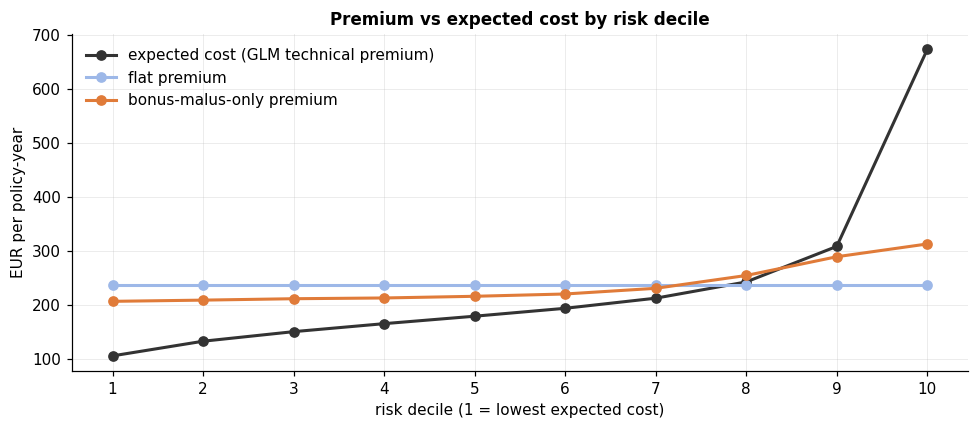

In [ ]:
# ---------- 6.4 Do low-risk customers pay for high-risk customers? ----------
risk_dec = exposure_deciles(tech, expo)
d = (tmp.assign(decile=risk_dec).groupby("decile")[["policy_years", "technical", "flat", "bm"]].sum())
decile_adequacy = pd.DataFrame({
    "policy-years": d["policy_years"],
    "technical premium (EUR per year)": d["technical"] / d["policy_years"],
    "flat premium (EUR per year)": d["flat"] / d["policy_years"],
    "BM-only premium (EUR per year)": d["bm"] / d["policy_years"],
    "flat / technical": d["flat"] / d["technical"],
    "BM-only / technical": d["bm"] / d["technical"],
})
decile_adequacy.index.name = "risk decile (1 = lowest expected cost)"
display(decile_adequacy.style.format({"policy-years": "{:,.0f}", "technical premium (EUR per year)": "{:,.0f}",
        "flat premium (EUR per year)": "{:,.0f}", "BM-only premium (EUR per year)": "{:,.0f}",
        "flat / technical": "{:.2f}", "BM-only / technical": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(decile_adequacy.index, decile_adequacy["technical premium (EUR per year)"], color="#333", marker="o", lw=2,
        label="expected cost (GLM technical premium)")
ax.plot(decile_adequacy.index, decile_adequacy["flat premium (EUR per year)"], color="#9db8e8", marker="o", lw=2,
        label="flat premium")
ax.plot(decile_adequacy.index, decile_adequacy["BM-only premium (EUR per year)"], color="#e07b39", marker="o", lw=2,
        label="bonus-malus-only premium")
ax.set_xticks(decile_adequacy.index); ax.set_xlabel("risk decile (1 = lowest expected cost)")
ax.set_ylabel("EUR per policy-year"); ax.legend(frameon=False)
ax.set_title("Premium vs expected cost by risk decile", fontweight="bold")
plt.tight_layout(); plt.show()

**Finding:**

**Under both simpler tariffs, low-risk customers pay well above their expected cost and the highest-risk customers well below it**.

- Expected cost rises from EUR 106 per year in the lowest risk decile to EUR 674 in the highest, while the bonus-malus premium rises only from EUR 207 to EUR 313.
- Under the flat tariff, the lowest-risk decile pays 2.24 times its expected cost and the highest-risk decile only 0.35.
- The bonus-malus tariff narrows but does not close the gap: the lowest-risk decile pays 1.96 times its expected cost and the highest-risk decile 0.46.
- Under the bonus-malus tariff, deciles 1 to 8 are overcharged (1.96 down to 1.05) and deciles 9 and 10 are subsidised (0.94 and 0.46), so the subsidy flows mainly from the lower-risk 80% of policy-years to the highest-risk 10%.

## 6.5 Check against actual claims (test set)

**What this step does:** checks the cross-subsidy against **actual** claims rather than model predictions, using the test policies the models never saw. Loss ratio = actual claims cost ÷ premium.

**What to expect:** if the GLM is right, the flat and bonus-malus tariffs should show loss ratios well below 1 for low-risk groups and well above 1 for high-risk groups, while the GLM's loss ratios stay close to the same level across groups.

*The test set is used because the GLM was fitted on the training set; on training data its loss ratios by rating factor would look near-perfect by construction. "Actual cost" is defined as in 5.5. Groups with few claims give less reliable loss ratios, so the number of claims is shown.*

,policy-years,claims,"loss ratio, flat","loss ratio, BM-only","loss ratio, GLM"
risk decile (1 = lowest expected cost),,,,,
1,"7,158",321,0.41,0.47,0.93
2,"7,159",410,0.57,0.65,1.02
3,"7,159",459,0.59,0.66,0.93
4,"7,158",568,0.73,0.82,1.05
5,"7,159",589,0.80,0.87,1.05
6,"7,158",594,0.81,0.87,0.99
7,"7,158",663,0.86,0.88,0.95
8,"7,159",751,1.05,0.98,1.02
9,"7,158","1,001",1.38,1.13,1.05


Test-set loss ratio overall: flat 0.987 | BM-only 0.988 | GLM 0.985
loss ratio, flat: decile 1 = 0.41, decile 10 = 2.66
loss ratio, BM-only: decile 1 = 0.47, decile 10 = 2.01
loss ratio, GLM: decile 1 = 0.93, decile 10 = 0.93


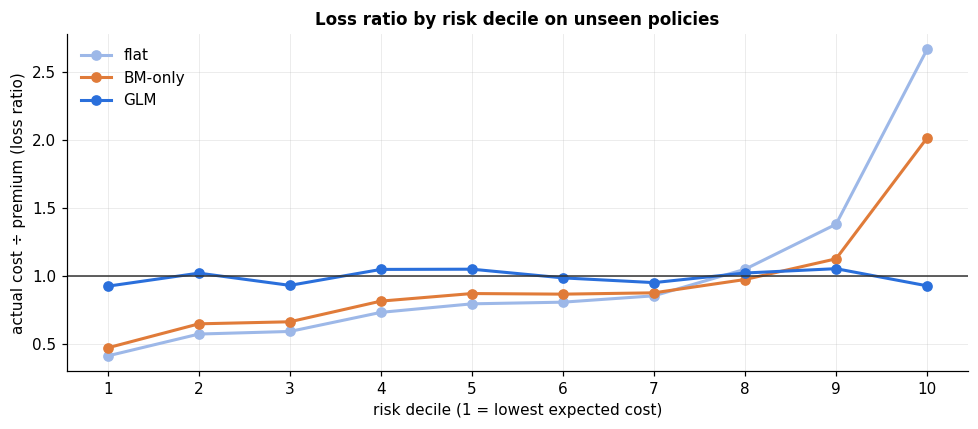

In [ ]:
# ---------- 6.5 Check against actual claims (test set) ----------
te[["prem_flat", "prem_bm", "prem_glm"]] = policies.loc[te.index, ["prem_flat", "prem_bm", "prem_glm"]]
te_expo = te["Exposure"].to_numpy()
te["risk_decile"] = exposure_deciles(te["pp_glm"].to_numpy(), te_expo)

def loss_ratios(group_col):
    g = te.assign(flat=te["prem_flat"] * te["Exposure"], bm=te["prem_bm"] * te["Exposure"],
                  glm=te["prem_glm"] * te["Exposure"]) \
          .groupby(group_col, observed=True)[["Exposure", "ClaimNb_model", "actual_cost", "flat", "bm", "glm"]].sum()
    return pd.DataFrame({"policy-years": g["Exposure"], "claims": g["ClaimNb_model"],
                         "loss ratio, flat": g["actual_cost"] / g["flat"],
                         "loss ratio, BM-only": g["actual_cost"] / g["bm"],
                         "loss ratio, GLM": g["actual_cost"] / g["glm"]})

lr_fmt = {"policy-years": "{:,.0f}", "claims": "{:,.0f}", "loss ratio, flat": "{:.2f}",
          "loss ratio, BM-only": "{:.2f}", "loss ratio, GLM": "{:.2f}"}
lr_decile = loss_ratios("risk_decile")
lr_decile.index.name = "risk decile (1 = lowest expected cost)"
display(lr_decile.style.format(lr_fmt))
overall = {k: te["actual_cost"].sum() / (te[c] * te["Exposure"]).sum()
           for k, c in [("flat", "prem_flat"), ("BM-only", "prem_bm"), ("GLM", "prem_glm")]}
print("Test-set loss ratio overall: " + " | ".join(f"{k} {v:.3f}" for k, v in overall.items()))
for col in ["loss ratio, flat", "loss ratio, BM-only", "loss ratio, GLM"]:
    print(f"{col}: decile 1 = {lr_decile[col].iloc[0]:.2f}, decile 10 = {lr_decile[col].iloc[-1]:.2f}")

lr_factor = pd.concat({f: loss_ratios(f) for f in ["DrivAgeBand", "VehAgeBand"]}, names=["factor", "level"])
display(lr_factor.style.format(lr_fmt))

fig, ax = plt.subplots(figsize=(9, 4))
for col, c in [("loss ratio, flat", "#9db8e8"), ("loss ratio, BM-only", "#e07b39"), ("loss ratio, GLM", MAIN_COLOR)]:
    ax.plot(lr_decile.index, lr_decile[col], color=c, marker="o", lw=2, label=col.replace("loss ratio, ", ""))
ax.axhline(1, color="#333", lw=1)
ax.set_xticks(lr_decile.index); ax.set_xlabel("risk decile (1 = lowest expected cost)")
ax.set_ylabel("actual cost ÷ premium (loss ratio)"); ax.legend(frameon=False)
ax.set_title("Loss ratio by risk decile on unseen policies", fontweight="bold")
plt.tight_layout(); plt.show()

**Finding:**

**Actual claims on unseen policies confirm the cross-subsidy: under the simpler tariffs, loss ratios rise steeply with risk, while the GLM keeps them between 0.93 and 1.05**.

- Under the flat tariff, the loss ratio rises from 0.41 in the lowest risk decile to 2.66 in the highest; under the bonus-malus tariff, from 0.47 to 2.01. The highest-risk decile costs twice its bonus-malus premium in actual claims.
- Under the GLM, loss ratios stay between 0.93 and 1.05 across all ten deciles (0.93 in both decile 1 and decile 10).
- The overall test-set loss ratio is almost identical for the three tariffs (0.987 flat, 0.988 bonus-malus, 0.985 GLM): they differ in who pays, not in the total collected.
- **New vehicles** have an actual loss ratio of 3.06 under both simpler tariffs vs 0.89 under the GLM (1,027 claims), confirming the subsidy found in 6.3 with real claims. Vehicles aged 16+ have a loss ratio of 0.61 under the bonus-malus tariff vs 1.00 under the GLM.
- **Drivers aged 18-20** have a loss ratio of 1.66 under the bonus-malus tariff and 0.86 under the GLM, but this rests on only 126 claims, so it is less reliable.

## 6.6 What if overcharged customers leave? (adverse selection scenario)

**What this step does:** an illustrative scenario where a competitor prices by risk, so customers who are overcharged by more than a threshold (10%, 20% or 30%) leave, while all other customers stay at their current price. The step shows what happens to the remaining book.

**How to read it:**
- "expected loss ratio of remaining customers" = their expected cost ÷ the premium they pay.
- Above 1 means the remaining book loses money, and "price rise needed" shows how much prices would have to go up to break even.
- In reality the price rise would push more customers out, repeating the cycle (the "adverse selection spiral").

*Assumptions: every customer above the threshold leaves and nobody else does; this is a one-round illustration, not a forecast.*

In [ ]:
# ---------- 6.6 What if overcharged customers leave? (adverse selection scenario) ----------
rows = []
for name, c in [("Flat", "prem_flat"), ("Bonus-malus only", "prem_bm")]:
    prem = policies[c].to_numpy()
    ratio = prem / tech
    for thr in [1.1, 1.2, 1.3]:
        stay = ratio <= thr
        lr_stay = np.sum(tech[stay] * expo[stay]) / np.sum(prem[stay] * expo[stay])
        rows.append({"tariff": name,
                     "customers leave if overcharged by more than": f"{thr - 1:.0%}",
                     "% of policy-years lost": expo[~stay].sum() / expo.sum() * 100,
                     "% of premium lost": np.sum(prem[~stay] * expo[~stay]) / np.sum(prem * expo) * 100,
                     "expected loss ratio of remaining customers": lr_stay,
                     "price rise needed to break even": (lr_stay - 1) * 100})
scenario = pd.DataFrame(rows)
display(scenario.style.hide(axis="index").format({"% of policy-years lost": "{:.1f}%", "% of premium lost": "{:.1f}%",
        "expected loss ratio of remaining customers": "{:.3f}", "price rise needed to break even": "{:+.1f}%"}))

tariff,customers leave if overcharged by more than,% of policy-years lost,% of premium lost,expected loss ratio of remaining customers,price rise needed to break even
Flat,10%,66.2%,66.2%,1.636,+63.6%
Flat,20%,57.0%,57.0%,1.472,+47.2%
Flat,30%,46.9%,46.9%,1.345,+34.5%
Bonus-malus only,10%,61.5%,59.6%,1.424,+42.4%
Bonus-malus only,20%,48.6%,47.2%,1.294,+29.4%
Bonus-malus only,30%,37.3%,36.1%,1.208,+20.8%


**Finding:**

**If customers overcharged by more than 20% left, the bonus-malus tariff's remaining customers would need a 29.4% price rise to break even**.

- Under the bonus-malus tariff, customers overcharged by more than 20% make up 48.6% of policy-years and 47.2% of premium. Without them, the expected loss ratio of the remaining customers rises from 1.00 to 1.294.
- Under the flat tariff, the same scenario loses 57.0% of policy-years and requires a 47.2% price rise.
- Even if only customers overcharged by more than 30% left, the bonus-malus book would need a 20.8% rise; at 10%, a 42.4% rise.
- The scenario is deliberately simple (every customer above the threshold leaves at once), so the figures show the direction and scale of the risk rather than a forecast: a competitor pricing by risk would attract the insurer's most profitable customers, and the price rise needed for those left would push more customers away.

## Conclusion - Objective 5


- **Size of the cross-subsidy:** under the bonus-malus tariff, EUR 14,988,050 a year (17.7% of total premium) is shifted from overcharged to undercharged customers; 48.6% of policy-years are overcharged and 11.3% undercharged by more than 20%. Under a flat tariff, the shift would be EUR 18,550,465 (21.9%), so pricing on claims history alone removes only part of the cross-subsidy.
- **Who is subsidised:** above all new vehicles, which pay only 0.29 of their expected cost (net subsidy EUR 9,582,677), followed by brand B12 (0.71), customers with a malus (0.51 to 0.73), dense areas E and F (0.85 and 0.78) and regions such as Provence-Alpes-Cote d'Azur and Ile-de-France (0.83).
- **Who pays for them:** customers at the bonus-malus floor (1.10 times expected cost, 62.8% of the portfolio), owners of older vehicles (1.28 at 11-15 years, 1.66 at 16+), drivers aged 26-40 (1.17 to 1.18), rural area A (1.21) and the Centre region (1.15).
- **Low risk pays for high risk:** the lowest-risk decile pays 1.96 times its expected cost under the bonus-malus tariff and the highest-risk decile only 0.46. Actual claims on unseen policies confirm this: loss ratios rise from 0.47 to 2.01 under the bonus-malus tariff, but stay between 0.93 and 1.05 under the GLM.
- **Adverse selection risk:** if customers overcharged by more than 20% left for a risk-based competitor, the remaining bonus-malus book would need a 29.4% price rise to break even (20.8% even at a 30% threshold).

**Business implications**
1. Pricing on claims history alone is not enough: the bonus-malus tariff ignores vehicle age, vehicle brand and location, so it cannot correct the largest subsidies. New vehicles alone receive a subsidy equivalent to 64% of all premium shifted.
2. The bonus-malus scale itself is too flat: customers at the floor (most of the portfolio) are overcharged by 10%, while customers with a malus pay only half to three-quarters of their expected cost.
3. Moving to the GLM tariff would lower prices for most low-risk customers, the ones most likely to be won by risk-based competitors, and raise them sharply for new vehicles and high-risk segments. These increases may need to be phased in, for example with caps on year-on-year changes, to manage customer reaction.
4. Because the GLM and GBM still disagree on individual prices (EUR 14,395,613, 17.0% of premium), refining the new-vehicle rating (Section 5.8) is the next priority, so that the new prices for new vehicles are not themselves mispriced.

**Limitations**
- The dataset has no real premiums, so the "current tariff" is a simplified bonus-malus-only tariff; real French tariffs combine the bonus-malus coefficient with other rating factors, so the real cross-subsidy is likely smaller than shown here.
- Expected cost comes from the GLM, which itself misses some patterns (5.7); the cross-subsidy figures are only as accurate as the technical premium.
- Net transfers by segment are calculated one factor at a time, so they overlap (a new B12 vehicle in area E appears in three segments) and cannot be added across factors.
- All tariffs are compared on claims cost only, without expenses, commission or profit margin.
- The adverse selection scenario assumes every customer above the threshold leaves and nobody else does, in a single round; real customer behaviour depends on price sensitivity, competitors and brand loyalty.
- Loss ratios on small test-set segments rest on few claims and are less reliable (e.g. 126 claims for drivers aged 18-20).

# Upload data to drive

In [ ]:
# ---------- 7. Exports for Power BI ----------
import re
from pathlib import Path
EXPORT_DIR = Path("/content/insurance_powerbi")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
def save(df, name, index=False):
    df.to_csv(EXPORT_DIR / f"{name}.csv", index=index)
    print(f"{name}.csv: {len(df):,} rows x {df.shape[1]} columns")

# ---- 1) Fact table: one row per policy ----
cost_capped_pol = claims_b.groupby("IDpol")["sev_capped"].sum()
fact = policies[["IDpol", "split", "Exposure", "ClaimNb_model", "n_claims_costed", "n_claims_uncosted", "ClaimAmount",
                 "DrivAge", "DrivAgeBand", "BonusMalus", "BonusMalusBand", "VehAge", "VehAgeBand",
                 "VehPower", "VehPowerBand", "VehBrand", "VehGas", "Area", "Density", "DensityBand", "RegionName",
                 "freq_glm", "sev_glm", "pp_glm", "tech_gbm", "prem_flat", "prem_bm", "prem_glm"]].copy()
fact["ClaimAmount_capped"] = fact["IDpol"].map(cost_capped_pol).fillna(0)
fact["actual_cost"] = (fact["ClaimAmount_capped"] + fact["n_claims_uncosted"] * SEV_FILL
                       + fact["ClaimNb_model"] * LARGE_LOAD)                       # same definition as 5.5
fact["NewVehicle"] = np.where(fact["VehAge"] == 0, "New (age 0)", "Not new")
fact["risk_decile"] = exposure_deciles(fact["pp_glm"].to_numpy(), fact["Exposure"].to_numpy())
fact["dislocation_pct"] = fact["prem_glm"] / fact["prem_bm"] - 1                  # BM-only -> GLM price change
disl_bins = [-np.inf, -0.5, -0.2, -0.05, 0.05, 0.2, 0.5, 1.0, np.inf]
disl_labels = ["Fall over 50%", "Fall 20-50%", "Fall 5-20%", "Within 5%", "Rise 5-20%", "Rise 20-50%",
               "Rise 50-100%", "Rise over 100%"]
fact["dislocation_band"] = pd.cut(fact["dislocation_pct"], bins=disl_bins, labels=disl_labels)
fact["dislocation_band_order"] = fact["dislocation_band"].cat.codes + 1
for c in ["DrivAgeBand", "BonusMalusBand", "VehAgeBand", "VehPowerBand", "DensityBand", "dislocation_band"]:
    fact[c] = fact[c].astype(str)
num_cols = fact.select_dtypes("float").columns
fact[num_cols] = fact[num_cols].round(6)
save(fact, "fact_policy")

# ---- 2) Dimension tables (one row per level, with a sort order for Power BI) ----
def dim(col, name):
    s = policies[col]
    levels = (list(s.cat.categories) if isinstance(s.dtype, pd.CategoricalDtype) else sorted(s.astype(str).unique()))
    d = pd.DataFrame({col: [str(l) for l in levels], f"{col}_order": range(1, len(levels) + 1)})
    save(d, name)

for col, name in [("DrivAgeBand", "dim_driver_age"), ("BonusMalusBand", "dim_bonus_malus"),
                  ("VehAgeBand", "dim_vehicle_age"), ("VehPowerBand", "dim_vehicle_power"),
                  ("VehBrand", "dim_vehicle_brand"), ("VehGas", "dim_fuel"), ("Area", "dim_area"),
                  ("DensityBand", "dim_density"), ("RegionName", "dim_region")]:
    dim(col, name)

# ---- 3) GLM relativities ----
def relativities(names, params, model):
    rows = []
    for n, p in zip(names, params):
        m = re.match(r"^C\((\w+),.*\)\[T\.(.+)\]$", n)
        if m:
            rows.append({"model": model, "factor": m.group(1), "level": m.group(2), "relativity": np.exp(p)})
        elif n == "Intercept":
            rows.append({"model": model, "factor": "Base level (intercept)", "level": "all reference levels",
                         "relativity": np.exp(p)})
        elif n in int_labels:
            rows.append({"model": model, "factor": "Driver age x bonus-malus 50", "level": int_labels[n],
                         "relativity": np.exp(p)})
        else:                                                 # e.g. terms added in 5.8
            rows.append({"model": model, "factor": "Other added terms", "level": n, "relativity": np.exp(p)})
    out = pd.DataFrame(rows)
    for f in out["factor"].unique():                         # add the reference level of each factor (= 1.00)
        if f in refs:
            out = pd.concat([out, pd.DataFrame([{"model": model, "factor": f, "level": str(refs[f]),
                                                 "relativity": 1.0}])], ignore_index=True)
    return out

if globals().get("adopt", False):                            # improved GLM from 5.8 was adopted
    f_names, f_params = [names2[i] for i in idx2], params2
else:
    f_names, f_params = freq_names, freq_nb["params"]
glm_rel = pd.concat([relativities(f_names, f_params, "Frequency (negative binomial)"),
                     relativities(list(sev_glm.params.index), sev_glm.params.to_numpy(), "Severity (Gamma)")],
                    ignore_index=True)
glm_rel["relativity"] = glm_rel["relativity"].round(4)
save(glm_rel, "glm_relativities")

# ---- 4) Model selection (Section 4 results, typed from the Section 4 outputs) ----
dist_tests = pd.DataFrame([
    {"target": "Frequency", "model": "Poisson", "AIC_train": 225433.7, "loglik_test": -28144.4,
     "test_deviance": 0.31281, "pred_actual_avg_cost": None, "selected": "No"},
    {"target": "Frequency", "model": "Negative binomial", "AIC_train": 224981.2, "loglik_test": -28075.8,
     "test_deviance": 0.31287, "pred_actual_avg_cost": None, "selected": "Yes"},
    {"target": "Frequency", "model": "Zero-inflated Poisson", "AIC_train": 225054.1, "loglik_test": -28089.0,
     "test_deviance": 0.31285, "pred_actual_avg_cost": None, "selected": "No"},
    {"target": "Severity", "model": "Gamma GLM", "AIC_train": 359632.3, "loglik_test": -45203.8,
     "test_deviance": None, "pred_actual_avg_cost": 1.002, "selected": "Yes"},
    {"target": "Severity", "model": "Inverse Gaussian GLM", "AIC_train": 367944.7, "loglik_test": -46121.0,
     "test_deviance": None, "pred_actual_avg_cost": 1.003, "selected": "No"},
    {"target": "Severity", "model": "Lognormal", "AIC_train": 352844.8, "loglik_test": -44326.4,
     "test_deviance": None, "pred_actual_avg_cost": 1.089, "selected": "No"},
])
save(dist_tests, "dist_tests")

# ---- 5) Model performance and Section 6 summary tables ----
save(gbm_compare, "glm_vs_gbm")
save(lift.reset_index().rename(columns={"decile (1 = lowest predicted)": "decile"}), "lift_glm_test")
save(dl.reset_index().rename(columns={"decile (1 = GBM lowest vs GLM)": "decile"}), "double_lift_test")
save(lr_decile.reset_index().rename(columns={"risk decile (1 = lowest expected cost)": "decile"}), "loss_ratio_deciles_test")
save(cs_tbl.reset_index(), "cross_subsidy_summary")
save(scenario, "adverse_selection_scenario")

# ---- 6) Claim cost concentration (Lorenz-style curve) ----
amt = np.sort(claims_b["ClaimAmount"].to_numpy())[::-1]           # largest claims first
cum_cost = np.cumsum(amt) / amt.sum()
pts = np.unique(np.concatenate([np.arange(0.001, 0.01, 0.001), np.arange(0.01, 1.0001, 0.01)]))
idx = np.clip((pts * len(amt)).astype(int) - 1, 0, len(amt) - 1)
conc_curve = pd.DataFrame({"pct_of_claims": (pts * 100).round(1), "pct_of_cost": (cum_cost[idx] * 100).round(2)})
save(conc_curve, "cost_concentration")

print(f"\nAll files saved to {EXPORT_DIR}")

fact_policy.csv: 678,013 rows x 35 columns
dim_driver_age.csv: 8 rows x 2 columns
dim_bonus_malus.csv: 6 rows x 2 columns
dim_vehicle_age.csv: 6 rows x 2 columns
dim_vehicle_power.csv: 8 rows x 2 columns
dim_vehicle_brand.csv: 11 rows x 2 columns
dim_fuel.csv: 2 rows x 2 columns
dim_area.csv: 6 rows x 2 columns
dim_density.csv: 5 rows x 2 columns
dim_region.csv: 22 rows x 2 columns
glm_relativities.csv: 114 rows x 4 columns
dist_tests.csv: 6 rows x 7 columns
glm_vs_gbm.csv: 4 rows x 7 columns
lift_glm_test.csv: 10 rows x 5 columns
double_lift_test.csv: 10 rows x 9 columns
loss_ratio_deciles_test.csv: 10 rows x 6 columns
cross_subsidy_summary.csv: 3 rows x 7 columns
adverse_selection_scenario.csv: 6 rows x 6 columns
cost_concentration.csv: 109 rows x 2 columns

All files saved to /content/insurance_powerbi


In [ ]:
import shutil
from google.colab import files
shutil.make_archive("/content/insurance_powerbi", "zip", EXPORT_DIR)
files.download("/content/insurance_powerbi.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>